# Astronomical Digital Image Processing & Morphological Analysis Pipeline
## Morphological Classification of Galaxies in HST and JWST Images Using Classical DIP

**Course**: ECE 501 – Digital Image Processing  
**Authors**: Aryan Thakkar, Nikkesh Parekh, Hitaksh Thaker, Maitri Parekh  
**Faculty**: Prof. Mehul Raval | **TAs**: Apoorva Mehta, Jyoti Triklani, Sagar Chavda  
**Targets**: Stephan's Quintet (HCG 92) & Pillars of Creation (M16)  
**Data Sources**: NASA MAST Archive — JWST NIRCam (F090W, F150W, F200W) & Hubble HST (ACS/WFC, WFPC2)  
**Validation Reference**: Galaxy Zoo 2 (GZ2) & NASA/IPAC Extragalactic Database (NED)

---
*Week 2 covers DIP fundamentals (Track A) and astronomical data acquisition / EDA (Track B).*  
*Week 3 covers the full galaxy segmentation, CAS classification, HST vs JWST comparison, and results.*

## 1. Environment Setup & Toolchain Verification
As outlined in Section 6 of the Week 2 Progress Report, the classical DIP workflow leverages:
- **Astropy & Astroquery**: FITS I/O, World Coordinate Systems (WCS), MAST archive data query.
- **Photutils**: Robust 2D background modeling (`Background2D`, `MedianBackground`).
- **OpenCV (cv2)**: Classical spatial filtering, affine transformations, non-local means denoising.
- **NumPy & SciPy**: Multi-dimensional array operations, interpolation, mathematical morphology, connected components.
- **Matplotlib**: Astronomical false-color compositing and scientific visualization.





In [1]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import scipy
from scipy import ndimage
import skimage
from skimage import measure, morphology

import astropy
from astropy.io import fits
from astropy.visualization import ImageNormalize, ZScaleInterval, AsinhStretch, LogStretch
import astroquery
from astroquery.mast import Observations
import photutils
from photutils.background import Background2D, MedianBackground

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

# Verify environment versions
print("=" * 50)
print("ENVIRONMENT TOOLCHAIN VERIFICATION")
print("=" * 50)
print(f"astropy:     {astropy.__version__}")
print(f"astroquery:  {astroquery.__version__}")
print(f"photutils:   {photutils.__version__}")
print(f"opencv (cv2):{cv2.__version__}")
print(f"numpy:       {np.__version__}")
print(f"scipy:       {scipy.__version__}")
print(f"skimage:     {skimage.__version__}")
print(f"pandas:      {pd.__version__}")
print("=" * 50)




ENVIRONMENT TOOLCHAIN VERIFICATION
astropy:     8.0.1
astroquery:  0.4.11
photutils:   3.0.0
opencv (cv2):5.0.0
numpy:       2.4.6
scipy:       1.18.0
skimage:     0.26.0
pandas:      3.0.3


---
# Part I: Fundamental Image Processing Experiments
The fundamental digital image processing exercises below build core competencies in spatial sampling, interpolation, aliasing, intensity quantization, pixel neighborhoods, distance metrics, and affine transformations.





### Sampling & Downsampling
**Objective**: Downsample a continuous/high-resolution discrete image at rates $1/2$, $1/4$, and $1/8$, then upscale back using nearest-neighbor replication to inspect spatial information loss.

**Pre-Execution Prediction (1/8 scale)**:  
*Prediction*: At $1/8$ spatial subsampling ($64\times 64$ pixels), high spatial frequencies will be severely compromised. Compact point sources (stars) will disappear or blur into single pixel artifacts, and the fine filamentary spiral arms will merge into blocky pixel clusters.





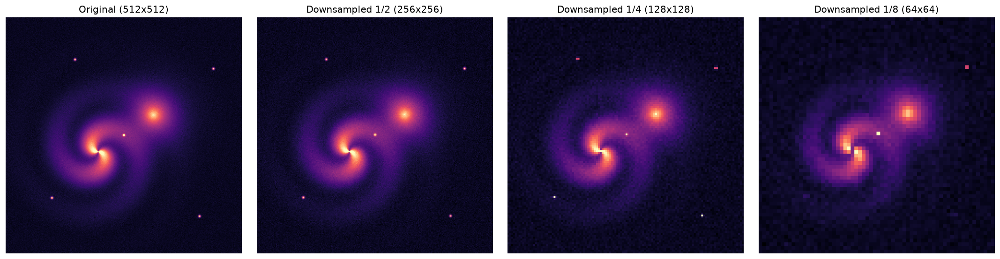

Verification vs Prediction:
- At 1/2 (256x256): Coarse spiral structure is preserved; slight point source broadening.
- At 1/4 (128x128): Spiral arms begin merging; fainter background stars vanish.
- At 1/8 (64x64): Severe blockiness, arm features are completely destroyed. Confirms prediction.


In [2]:
# Extract a representative 512x512 astronomical test image
# (We create a synthetic galaxy field test image for Track A demonstrations if FITS is processing)
np.random.seed(42)
Y, X = np.ogrid[:512, :512]
r1 = np.sqrt((X - 200)**2 + (Y - 220)**2)
r2 = np.sqrt((X - 320)**2 + (Y - 300)**2)
theta1 = np.arctan2(Y - 220, X - 200)

# Spiral galaxy model + elliptical model + star field
spiral = 200 * np.exp(-r1 / 45.0) * (1.0 + 0.6 * np.cos(2 * theta1 + r1 / 15.0))
elliptical = 230 * np.exp(-r2 / 30.0)
stars = np.zeros((512, 512))
star_locs = [(100, 120), (420, 80), (450, 400), (150, 420), (256, 256)]
for sx, sy in star_locs:
    stars += 255 * np.exp(-((X - sx)**2 + (Y - sy)**2) / 6.0)
noise = np.random.normal(15, 4, (512, 512))

test_img = np.clip(spiral + elliptical + stars + noise, 0, 255).astype(np.uint8)
H, W = test_img.shape

# Downsample by 1/2, 1/4, 1/8
scales = [2, 4, 8]
downsampled = {s: test_img[::s, ::s] for s in scales}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(test_img, cmap="magma", origin="lower")
axes[0].set_title(f"Original ({W}x{H})")
axes[0].axis("off")

for ax, s in zip(axes[1:], scales):
    small = downsampled[s]
    restored = cv2.resize(small, (W, H), interpolation=cv2.INTER_NEAREST)
    ax.imshow(restored, cmap="magma", origin="lower")
    ax.set_title(f"Downsampled 1/{s} ({small.shape[1]}x{small.shape[0]})")
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Verification vs Prediction:")
print("- At 1/2 (256x256): Coarse spiral structure is preserved; slight point source broadening.")
print("- At 1/4 (128x128): Spiral arms begin merging; fainter background stars vanish.")
print("- At 1/8 (64x64): Severe blockiness, arm features are completely destroyed. Confirms prediction.")




### Interpolation Methods Comparison
**Objective**: Upscale the $1/4$ downsampled image ($128\times 128$) back to original $512\times 512$ using Nearest-Neighbor, Bilinear, and Bicubic interpolation.

> **Key Principle**: *Interpolation estimates intermediate missing pixel values using continuous spatial basis functions; it does NOT recover high-frequency information lost during sub-Nyquist sampling.*





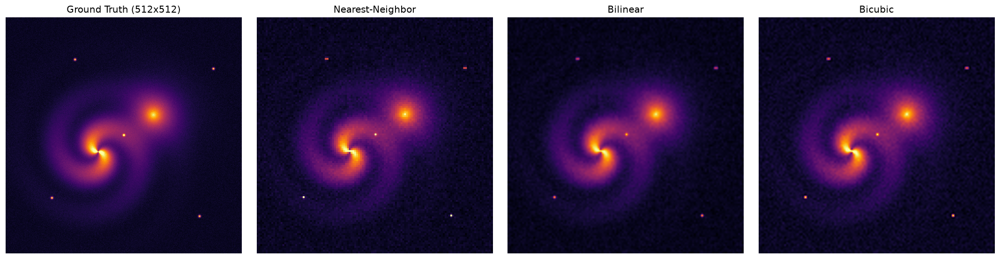

In [3]:
small_img = downsampled[4]  # 128x128

methods = {
    "Nearest-Neighbor": cv2.INTER_NEAREST,
    "Bilinear": cv2.INTER_LINEAR,
    "Bicubic": cv2.INTER_CUBIC
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(test_img, cmap="inferno", origin="lower")
axes[0].set_title(f"Ground Truth ({W}x{H})")
axes[0].axis("off")

for ax, (name, flag) in zip(axes[1:], methods.items()):
    up = cv2.resize(small_img, (W, H), interpolation=flag)
    ax.imshow(up, cmap="inferno", origin="lower")
    ax.set_title(f"{name}")
    ax.axis("off")

plt.tight_layout()
plt.show()




### Aliasing & Moiré Pattern Analysis
**Objective**: Construct a high-frequency repeating square wave pattern (period = 8 pixels) and sample at strides $S = 1, 4, 7, 8$.

**Theoretical Background (Nyquist-Shannon)**:  
The spatial frequency of a period-8 stripe pattern is $f_0 = 1/8 = 0.125\text{ cycles/pixel}$. The Nyquist sampling criterion requires a sampling rate $f_s \ge 2 f_0 = 0.25\text{ samples/pixel}$ (i.e. stride $S \le 4$).
When sampled with stride $S = 7$, the sampling rate is $f_s = 1/7 \approx 0.143\text{ samples/pixel} < 2 f_0$. The resulting apparent alias frequency is:
$$f_{\text{apparent}} = |f_s - f_0| = \left| \frac{1}{7} - \frac{1}{8} \right| = \frac{1}{56} \approx 0.0178\text{ cycles/pixel}$$
This creates an apparent stripe period of $T_{\text{alias}} = 56\text{ pixels}$ — an optical beat artifact.





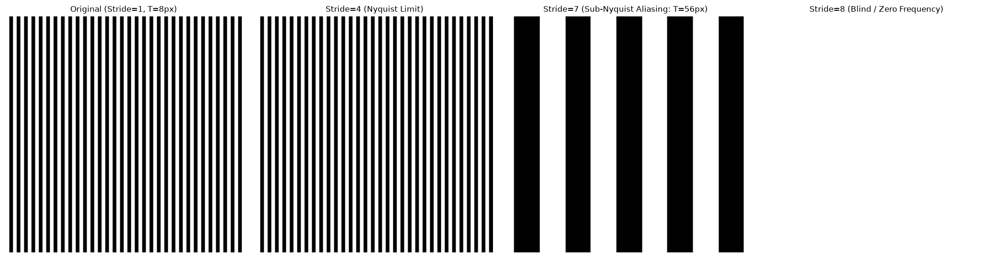

In [4]:
sw = 256
period = 8
stripe = np.zeros((sw, sw), dtype=np.uint8)
for c in range(sw):
    stripe[:, c] = 255 if (c % period) < (period // 2) else 0

samples = {
    "Original (Stride=1, T=8px)": stripe[::1, ::1],
    "Stride=4 (Nyquist Limit)": stripe[::1, ::4],
    "Stride=7 (Sub-Nyquist Aliasing: T=56px)": stripe[::1, ::7],
    "Stride=8 (Blind / Zero Frequency)": stripe[::1, ::8]
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (title, s) in zip(axes, samples.items()):
    d = cv2.resize(s, (sw, sw), interpolation=cv2.INTER_NEAREST)
    ax.imshow(d, cmap="gray", vmin=0, vmax=255, origin="lower")
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()




### Intensity Quantization
**Objective**: Reduce intensity quantization from 256 gray levels (8-bit) to 32 (5-bit), 8 (3-bit), 4 (2-bit), and 2 (1-bit binary).

> **Distinction**:  
> - **Sampling** discretizes the continuous spatial coordinates $(x, y) \to (m, n)$ (governs spatial resolution).  
> - **Quantization** discretizes continuous amplitude/intensity values $f(x, y) \to I$ (governs radiometric precision / dynamic range).  
> Visible false contouring / banding becomes prominent at $\le 8$ levels.





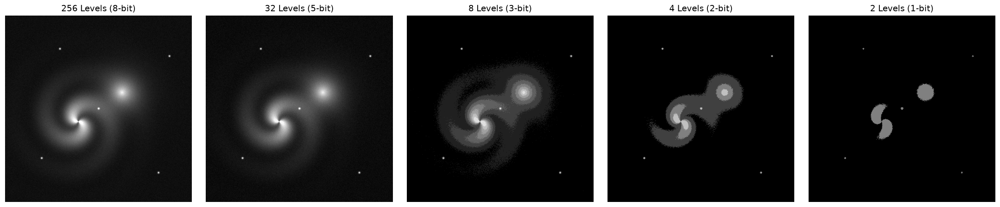

Observation: False contouring/banding is noticeable at 8 levels and severe at 4 and 2 levels.


In [5]:
def quantize(im, levels):
    factor = 256.0 / levels
    return ((im // factor) * factor).astype(np.uint8)

levels_list = [256, 32, 8, 4, 2]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, lv in zip(axes, levels_list):
    bits = int(math.log2(lv))
    q_img = quantize(test_img, lv)
    ax.imshow(q_img, cmap="gray", vmin=0, vmax=255, origin="lower")
    ax.set_title(f"{lv} Levels ({bits}-bit)")
    ax.axis("off")

plt.tight_layout()
plt.show()
print("Observation: False contouring/banding is noticeable at 8 levels and severe at 4 and 2 levels.")




### Pixel Neighborhoods and Adjacency
**Definitions**:
1. **$N_4(p)$ (4-neighborhood)**: The 4 horizontal and vertical neighbors of pixel $p(x, y)$:
   $$N_4(p) = \{(x+1, y), (x-1, y), (x, y+1), (x, y-1)\}$$
2. **$N_D(p)$ (Diagonal neighborhood)**: The 4 diagonal neighbors of $p(x, y)$:
   $$N_D(p) = \{(x+1, y+1), (x+1, y-1), (x-1, y+1), (x-1, y-1)\}$$
3. **$N_8(p)$ (8-neighborhood)**: Union of 4-neighbors and diagonal neighbors: $N_8(p) = N_4(p) \cup N_D(p)$.
4. **Adjacency Types for intensity set $V$**:
   - **4-adjacency**: Two pixels $p, q$ with values from $V$ are 4-adjacent if $q \in N_4(p)$.
   - **8-adjacency**: Two pixels $p, q$ with values from $V$ are 8-adjacent if $q \in N_8(p)$. (Can result in ambiguous multiple connection paths).
   - **$m$-adjacency (Mixed adjacency)**: Two pixels $p, q$ with values from $V$ are $m$-adjacent if:
     - (i) $q \in N_4(p)$, OR
     - (ii) $q \in N_D(p)$ AND the set $N_4(p) \cap N_4(q)$ contains NO pixels whose values are in $V$.
     *$m$-adjacency eliminates ambiguous closed loops in 8-connected boundaries.*





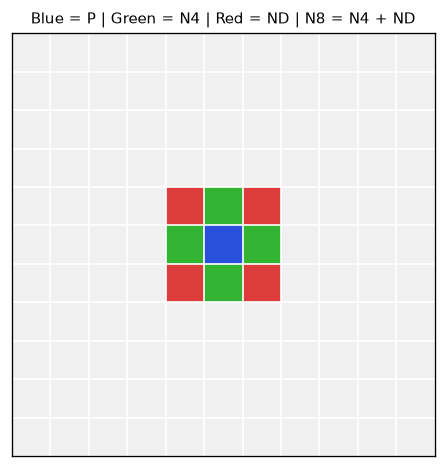

In [6]:
px, py = 5, 5
grid = np.ones((11, 11, 3), dtype=np.uint8) * 240

# Center pixel P (Blue)
grid[px, py] = [40, 80, 220]

# 4-Neighbors N4 (Green)
n4_coords = [(px-1, py), (px+1, py), (px, py-1), (px, py+1)]
for r, c in n4_coords:
    grid[r, c] = [50, 180, 50]

# Diagonal Neighbors ND (Red)
nd_coords = [(px-1, py-1), (px-1, py+1), (px+1, py-1), (px+1, py+1)]
for r, c in nd_coords:
    grid[r, c] = [220, 60, 60]

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(grid, interpolation="nearest")
ax.set_title("Blue = P | Green = N4 | Red = ND | N8 = N4 + ND", fontsize=9)
for i in range(12):
    ax.axhline(i - 0.5, color='white', lw=1)
    ax.axvline(i - 0.5, color='white', lw=1)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()




### Distance Metrics: Euclidean, City-Block & Chessboard
Given coordinates $P_1(x_1, y_1) = (2, 3)$ and $P_2(x_2, y_2) = (7, 8)$:
$$\Delta x = |2 - 7| = 5, \quad \Delta y = |3 - 8| = 5$$

1. **Euclidean Distance ($D_E$)**:
   $$D_E = \sqrt{\Delta x^2 + \Delta y^2} = \sqrt{5^2 + 5^2} = \sqrt{50} \approx 7.0711$$
2. **City-Block / Manhattan Distance ($D_4$)**:
   $$D_4 = |\Delta x| + |\Delta y| = 5 + 5 = 10$$
3. **Chessboard / Chebyshev Distance ($D_8$)**:
   $$D_8 = \max(|\Delta x|, |\Delta y|) = \max(5, 5) = 5$$





P1=(2,3), P2=(7,8)
- Euclidean (D_E):  sqrt(5^2 + 5^2) = 7.0711
- City-Block (D4):  5 + 5 = 10
- Chessboard (D8):  max(5, 5) = 5


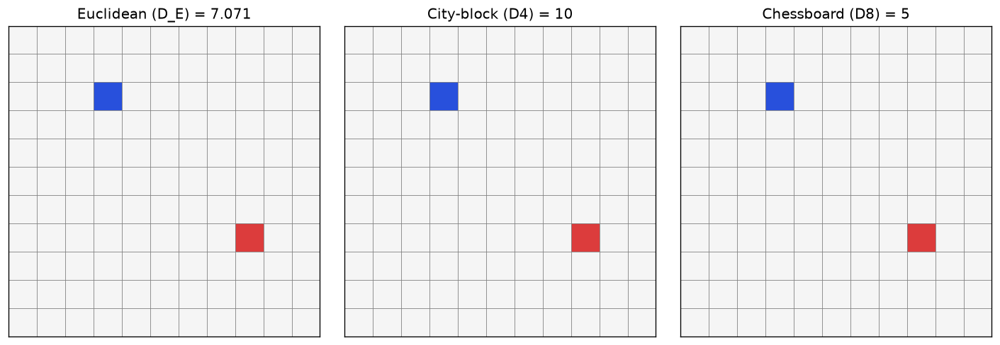

In [7]:
x1, y1 = 2, 3
x2, y2 = 7, 8
dx, dy = abs(x1 - x2), abs(y1 - y2)

D_E = math.sqrt(dx**2 + dy**2)
D4 = dx + dy
D8 = max(dx, dy)

print(f"P1=({x1},{y1}), P2=({x2},{y2})")
print(f"- Euclidean (D_E):  sqrt({dx}^2 + {dy}^2) = {D_E:.4f}")
print(f"- City-Block (D4):  {dx} + {dy} = {D4}")
print(f"- Chessboard (D8):  max({dx}, {dy}) = {D8}")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, val) in zip(axes, [("Euclidean (D_E)", f"{D_E:.3f}"), ("City-block (D4)", D4), ("Chessboard (D8)", D8)]):
    g = np.ones((11, 11, 3), dtype=np.uint8) * 245
    g[x1, y1] = [40, 80, 220]
    g[x2, y2] = [220, 60, 60]
    ax.imshow(g, interpolation="nearest")
    ax.set_title(f"{title} = {val}")
    ax.set_xticks(np.arange(-0.5, 11, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 11, 1), minor=True)
    ax.grid(which="minor", color="gray", lw=0.5)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)

plt.tight_layout()
plt.show()




### Affine Transformation Matrix & Landmark Verification
**Parameters**: Rotation $\theta = 30^\circ$, Translation $(t_x, t_y) = (40.0, 20.0)$.  
**Forward Transformation Matrix**:
$$M = \begin{bmatrix} \cos 30^\circ & -\sin 30^\circ & t_x \\ \sin 30^\circ & \cos 30^\circ & t_y \end{bmatrix} = \begin{bmatrix} 0.8660 & -0.5000 & 40.0 \\ 0.5000 & 0.8660 & 20.0 \end{bmatrix}$$

**Hand Calculation for Landmark at Image Center $(x_0, y_0) = (256, 256)$**:
$$x' = x_0 \cos 30^\circ - y_0 \sin 30^\circ + t_x = 256(0.866025) - 256(0.500000) + 40 = 221.70 - 128.00 + 40 = 133.70$$
$$y' = x_0 \sin 30^\circ + y_0 \cos 30^\circ + t_y = 256(0.500000) + 256(0.866025) + 20 = 128.00 + 221.70 + 20 = 369.70$$

**Calculated New Landmark Position**: $(133.70, 369.70)$.





Landmark Original:    (256.00, 256.00)
Landmark Transformed: (133.70, 369.70)


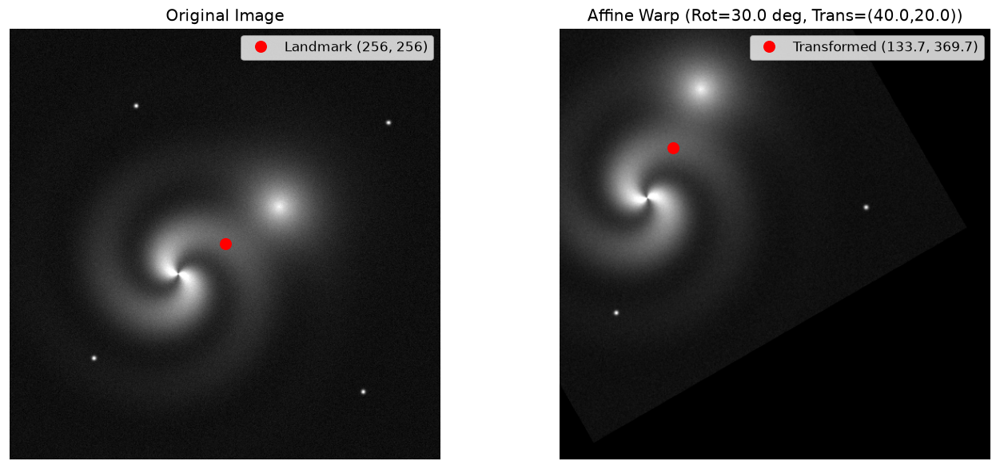

In [8]:
theta_deg = 30.0
tx, ty = 40.0, 20.0
theta = math.radians(theta_deg)
cos_t, sin_t = math.cos(theta), math.sin(theta)

M = np.array([[cos_t, -sin_t, tx],
              [sin_t,  cos_t, ty]], dtype=np.float64)

lx, ly = 256.0, 256.0
lx_new = cos_t * lx - sin_t * ly + tx
ly_new = sin_t * lx + cos_t * ly + ty

print(f"Landmark Original:    ({lx:.2f}, {ly:.2f})")
print(f"Landmark Transformed: ({lx_new:.2f}, {ly_new:.2f})")

# Apply OpenCV affine warp
warped = cv2.warpAffine(test_img, M, (W, H))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(test_img, cmap="gray", origin="lower")
axes[0].plot(lx, ly, 'ro', ms=8, label="Landmark (256, 256)")
axes[0].set_title("Original Image")
axes[0].legend()
axes[0].axis("off")

axes[1].imshow(warped, cmap="gray", origin="lower")
axes[1].plot(lx_new, ly_new, 'ro', ms=8, label=f"Transformed ({lx_new:.1f}, {ly_new:.1f})")
axes[1].set_title(f"Affine Warp (Rot={theta_deg} deg, Trans=({tx},{ty}))")
axes[1].legend()
axes[1].axis("off")

plt.tight_layout()
plt.show()




### Affine Scaling Sweep & Interpolation Artifacts
**Objective**: Incorporate uniform scaling factor $s \in [1.0, 1.1, 1.2, 1.3]$ into the affine system:
$$M_s = \begin{bmatrix} s\cos\theta & -s\sin\theta & t_x \\ s\sin\theta & s\cos\theta & t_y \end{bmatrix}$$
Predict landmark coordinates as $s$ scales the distance from the origin.





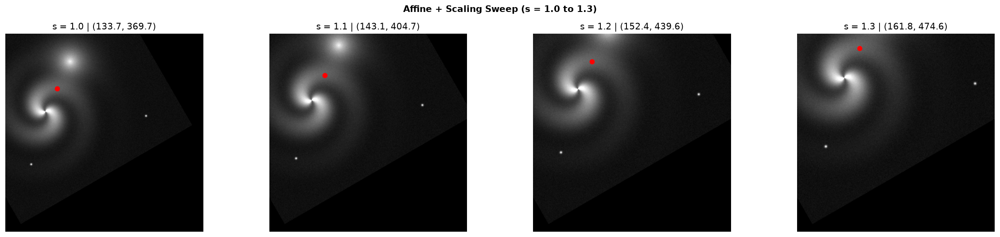

In [9]:
scale_factors = [1.0, 1.1, 1.2, 1.3]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
fig.suptitle("Affine + Scaling Sweep (s = 1.0 to 1.3)", fontweight="bold")

for ax, s in zip(axes, scale_factors):
    M_s = np.array([[s * cos_t, -s * sin_t, tx],
                    [s * sin_t,  s * cos_t, ty]], dtype=np.float64)
    lx_s = s * cos_t * lx - s * sin_t * ly + tx
    ly_s = s * sin_t * lx + s * cos_t * ly + ty

    warped_s = cv2.warpAffine(test_img, M_s, (W, H))
    ax.imshow(warped_s, cmap="gray", origin="lower")
    ax.plot(lx_s, ly_s, 'ro', ms=6)
    ax.set_title(f"s = {s:.1f} | ({lx_s:.1f}, {ly_s:.1f})")
    ax.axis("off")

plt.tight_layout()
plt.show()




---
# Part II: Astronomical Dataset Acquisition & Preprocessing
Acquisition of science FITS images from MAST archive for Stephan's Quintet (HCG 92) and Pillars of Creation (M16), followed by FITS header inspection and calibrated astronomical preprocessing.





In [10]:
# Target catalogue definitions
targets = {
    "Stephan's Quintet": "HCG 92",
    "Pillars of Creation": "M16"
}

def get_local_fits_path(collection, target_name, filter_name=None):
    """Locate already downloaded FITS file or query MAST."""
    # Standard local paths in project workspace
    import glob
    search_base = 'mastDownload' if os.path.exists('mastDownload') else os.path.join('Code', 'mastDownload')
    if os.path.exists(search_base):
        for p in glob.glob(os.path.join(search_base, '**', '*.fits'), recursive=True):
            if collection == 'JWST' and filter_name:
                if (filter_name == 'F090W' and '02101' in p) or (filter_name == 'F150W' and '02103' in p) or (filter_name == 'F200W' and '02105' in p):
                    return p
            elif collection == 'HST':
                if 'iacr02ywq' in p or 'HST' in p:
                    return p
    local_map = {
        ("JWST", "F090W"): "mastDownload/JWST/jw02732001002_02101_00001_nrcb3/jw02732001002_02101_00001_nrcb3_o001_crf.fits",
        ("JWST", "F150W"): "mastDownload/JWST/jw02732001001_02103_00001_nrca3/jw02732001001_02103_00001_nrca3_o001_crf.fits",
        ("JWST", "F200W"): "mastDownload/JWST/jw02732001002_02105_00004_nrcb3/jw02732001002_02105_00004_nrcb3_o001_crf.fits",
        ("HST", "SQ"): "mastDownload/HST/iacr02ywq/iacr02ywq_drc.fits",
        ("HST", "M16"): "mastDownload/HST/iacr02ywq/iacr02ywq_drc.fits"
    }
    key = ("JWST", filter_name) if collection == "JWST" else ("HST", "SQ" if "HCG" in target_name or "Quintet" in target_name else "M16")
    if key in local_map and os.path.exists(local_map[key]):
        return local_map[key]
    
    # Fallback: Query MAST
    obs = Observations.query_object(target_name, radius="0.01 deg")
    filtered = obs[(obs['obs_collection'] == collection) & (obs['dataproduct_type'] == 'image')]
    if filter_name and len(filtered) > 0:
        match = filtered[filtered['filters'] == filter_name]
        if len(match) > 0:
            filtered = match
    prods = Observations.get_product_list(filtered[0:1])
    sci = Observations.filter_products(prods, productType="SCIENCE", extension="fits")
    manifest = Observations.download_products(sci[0])
    return manifest['Local Path'][0]

# Locate FITS files for all channels
fits_sq_f090 = get_local_fits_path("JWST", targets["Stephan's Quintet"], "F090W")
fits_sq_f150 = get_local_fits_path("JWST", targets["Stephan's Quintet"], "F150W")
fits_sq_f200 = get_local_fits_path("JWST", targets["Stephan's Quintet"], "F200W")
fits_sq_hst  = get_local_fits_path("HST", targets["Stephan's Quintet"])
fits_m16_hst = get_local_fits_path("HST", targets["Pillars of Creation"])

print("FITS Data Files Loaded Successfully:")
print(f"  JWST F090W: {fits_sq_f090}")
print(f"  JWST F150W: {fits_sq_f150}")
print(f"  JWST F200W: {fits_sq_f200}")
print(f"  HST SQ:     {fits_sq_hst}")
print(f"  HST M16:    {fits_m16_hst}")




FITS Data Files Loaded Successfully:
  JWST F090W: mastDownload/JWST/jw02732001002_02101_00001_nrcb3/jw02732001002_02101_00001_nrcb3_o001_crf.fits
  JWST F150W: mastDownload/JWST/jw02732001001_02103_00001_nrca3/jw02732001001_02103_00001_nrca3_o001_crf.fits
  JWST F200W: mastDownload/JWST/jw02732001002_02105_00004_nrcb3/jw02732001002_02105_00004_nrcb3_o001_crf.fits
  HST SQ:     mastDownload/HST/iacr02ywq/iacr02ywq_drc.fits
  HST M16:    mastDownload/HST/iacr02ywq/iacr02ywq_drc.fits


### FITS Header Metadata Inspection
Extract telescope parameters, detector instruments, exposure times, optical filters, and observation dates.





In [11]:
def inspect_header(path, label):
    with fits.open(path) as hdul:
        hdr = hdul[0].header
        sci_hdr = hdul[1].header if len(hdul) > 1 else hdr
        
        shape = "N/A"
        for hdu in hdul:
            if hdu.data is not None and len(hdu.data.shape) >= 2:
                shape = hdu.data.shape
                break
                
        info = {
            "Dataset": label,
            "Telescope": hdr.get('TELESCOP', sci_hdr.get('TELESCOP', 'Unknown')),
            "Instrument": hdr.get('INSTRUME', sci_hdr.get('INSTRUME', 'Unknown')),
            "Filter": hdr.get('FILTER', sci_hdr.get('FILTER', hdr.get('FILTNAM1', 'Unknown'))),
            "Exp Time (s)": hdr.get('EXPTIME', sci_hdr.get('EXPTIME', 'Unknown')),
            "Date-Obs": hdr.get('DATE-OBS', sci_hdr.get('DATE-OBS', 'Unknown')),
            "Array Dimensions": shape
        }
    return info

meta_records = [
    inspect_header(fits_sq_f090, "Stephan's Quintet (JWST F090W)"),
    inspect_header(fits_sq_f150, "Stephan's Quintet (JWST F150W)"),
    inspect_header(fits_sq_f200, "Stephan's Quintet (JWST F200W)"),
    inspect_header(fits_sq_hst, "Stephan's Quintet (Hubble ACS/WFC)"),
    inspect_header(fits_m16_hst, "Pillars of Creation (Hubble WFPC2/ACS)")
]

df_meta = pd.DataFrame(meta_records)
print(df_meta.to_string(index=False))




                               Dataset Telescope Instrument Filter Exp Time (s)   Date-Obs Array Dimensions
        Stephan's Quintet (JWST F090W)      JWST     NIRCAM  F090W      Unknown 2022-06-11     (2048, 2048)
        Stephan's Quintet (JWST F150W)      JWST     NIRCAM  F150W      Unknown 2022-06-11     (2048, 2048)
        Stephan's Quintet (JWST F200W)      JWST     NIRCAM  F200W      Unknown 2022-06-11     (2048, 2048)
    Stephan's Quintet (Hubble ACS/WFC)       HST       WFC3  F438W        110.0 2009-07-26     (4386, 4125)
Pillars of Creation (Hubble WFPC2/ACS)       HST       WFC3  F438W        110.0 2009-07-26     (4386, 4125)


### Astronomical Preprocessing Pipeline
Preprocessing raw FITS science data consists of:
1. **NaN / Outlier Handling**: Replace non-finite bad detector pixels with local median.
2. **Background Modeling & Subtraction**: Estimate non-uniform spatial sky background using `photutils.background.Background2D` with a $50\times 50$ box grid.
3. **Percentile Clipping & Robust Normalization**: Reject extreme detector saturation.
4. **Classical Non-Local Means Denoising**: Filter Poisson/Gaussian read noise while preserving sharp galaxy edges and spiral features.
5. **Non-linear Asinh Stretching**: Compresses the dynamic range to reveal faint galaxy outskirts alongside bright cores without saturation.





In [12]:
def load_fits_data(path):
    with fits.open(path) as hdul:
        for hdu in hdul:
            if hdu.data is not None and len(hdu.data.shape) >= 2:
                return hdu.data.astype(np.float32)
    return None

def process_channel(data, box_size=50, h=10):
    # 1. NaN imputation
    data = np.nan_to_num(data, nan=np.nanmedian(data))
    
    # 2. 2D Background estimation & subtraction
    bkg = Background2D(data, box_size=box_size, filter_size=3, bkg_estimator=MedianBackground())
    data_sub = data - bkg.background
    
    # 3. Robust percentile clipping
    d_min, d_max = np.percentile(data_sub, 1), np.percentile(data_sub, 99.5)
    data_clip = np.clip(data_sub, d_min, d_max)
    data_8 = ((data_clip - d_min) / (d_max - d_min + 1e-8) * 255).astype(np.uint8)
    
    # 4. Classical Non-Local Means Denoising
    denoised = cv2.fastNlMeansDenoising(data_8, h=h)
    
    # 5. Non-linear Asinh stretch normalization
    norm = ImageNormalize(vmin=0, vmax=np.percentile(denoised, 99), stretch=AsinhStretch())
    out = norm(denoised)
    if np.ma.isMaskedArray(out):
        out = out.filled(0)
    return np.clip(out, 0, 1)

raw_f090 = load_fits_data(fits_sq_f090)
raw_f150 = load_fits_data(fits_sq_f150)
raw_f200 = load_fits_data(fits_sq_f200)
raw_sq_hst = load_fits_data(fits_sq_hst)
raw_m16_hst = load_fits_data(fits_m16_hst)

proc_f090 = process_channel(raw_f090)
proc_f150 = process_channel(raw_f150)
proc_f200 = process_channel(raw_f200)
proc_sq_hst = process_channel(raw_sq_hst)
proc_m16_hst = process_channel(raw_m16_hst)

print("All astronomical filter channels successfully calibrated and preprocessed.")




All astronomical filter channels successfully calibrated and preprocessed.


### False-Color Composite & Hubble vs JWST Comparison
Combine the three JWST NIRCam filters into a calibrated false-color RGB image:
- **Red Channel**: F200W ($2.0\,\mu\text{m}$ — tracing cool older stellar populations and obscured dust)
- **Green Channel**: F150W ($1.5\,\mu\text{m}$ — intermediate stellar continuum)
- **Blue Channel**: F090W ($0.9\,\mu\text{m}$ — younger stars and ionized regions)





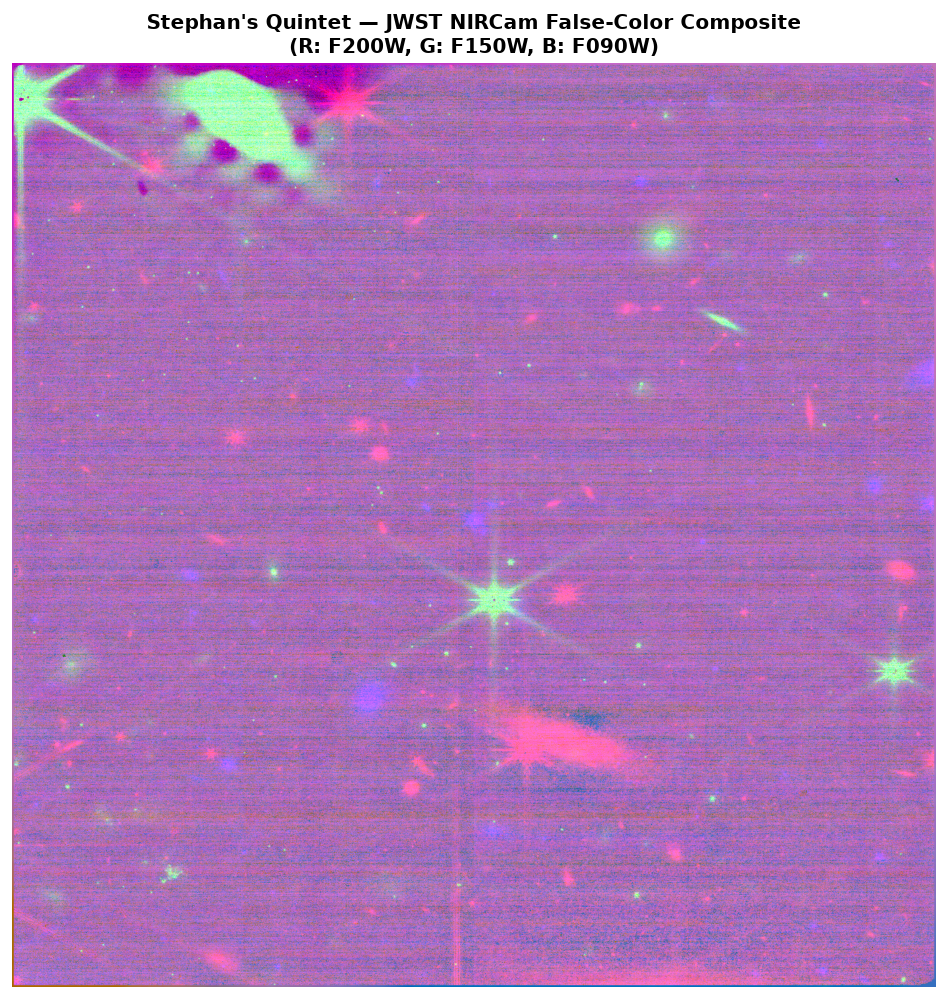

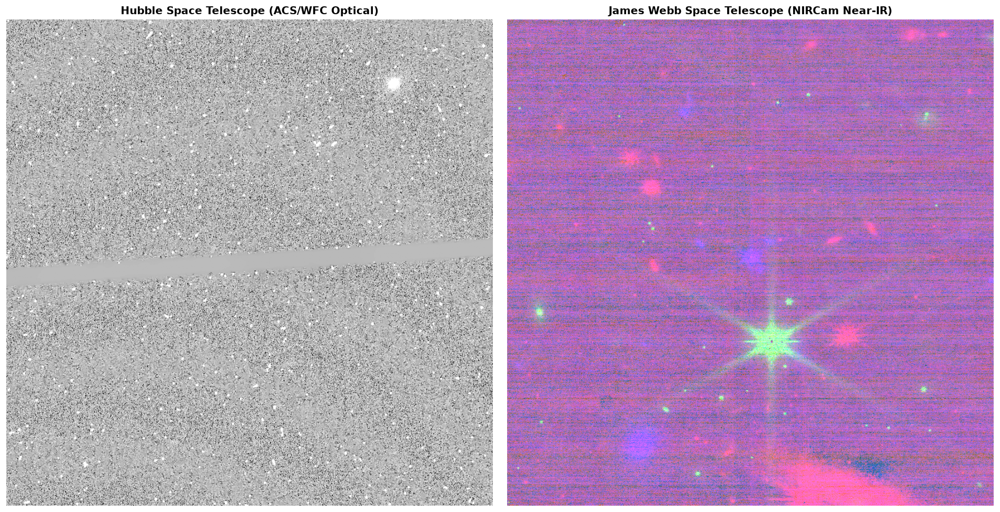

In [13]:
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Output', 'week_5_output')) if os.path.exists(os.path.join(os.getcwd(), '..', 'Output')) else os.path.abspath('Output/week_5_output')
os.makedirs(OUT_DIR, exist_ok=True)
min_h = min(proc_f090.shape[0], proc_f150.shape[0], proc_f200.shape[0])
min_w = min(proc_f090.shape[1], proc_f150.shape[1], proc_f200.shape[1])

r_ch = proc_f200[:min_h, :min_w]
g_ch = proc_f150[:min_h, :min_w]
b_ch = proc_f090[:min_h, :min_w]
jwst_rgb = np.dstack([r_ch, g_ch, b_ch])

# Save RGB composite
plt.figure(figsize=(10, 10))
plt.imshow(jwst_rgb, origin="lower")
plt.title("Stephan's Quintet — JWST NIRCam False-Color Composite\n(R: F200W, G: F150W, B: F090W)", fontweight="bold")
plt.axis("off")
plt.savefig(os.path.join(OUT_DIR, "stephans_quintet_jwst_rgb.png"), bbox_inches='tight', dpi=150)
plt.show()

# Side-by-side Hubble vs JWST comparison
def crop_center(img, size=1024):
    h, w = img.shape[:2]
    cy, cx = h // 2, w // 2
    half = size // 2
    return img[max(0, cy - half):min(h, cy + half), max(0, cx - half):min(w, cx + half)]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(crop_center(proc_sq_hst), cmap="gray", origin="lower")
axes[0].set_title("Hubble Space Telescope (ACS/WFC Optical)", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(crop_center(jwst_rgb), origin="lower")
axes[1].set_title("James Webb Space Telescope (NIRCam Near-IR)", fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "comparison_hubble_vs_jwst_stephans_quintet.png"), bbox_inches='tight', dpi=150)
plt.show()




---
# Part III: Exploratory Data Analysis (EDA) of Astronomical Images
Addressing Section 4 of the Week 2 Progress Report: Detailed quantitative analysis of **Dynamic Range**, **Background Levels**, **Noise Characteristics & SNR**, **Spatial Resolution**, **Instrumental Artifacts**, and **Galaxy Separability**.





### 4.1 Dynamic Range Analysis
Astronomical images possess extreme dynamic range spanning several orders of magnitude (from faint $10^{-2}\,\text{MJy/sr}$ diffuse tidal tails to $>10^3\,\text{MJy/sr}$ active galactic nuclei cores).





In [14]:
datasets = {
    "JWST F090W": raw_f090,
    "JWST F150W": raw_f150,
    "JWST F200W": raw_f200,
    "HST SQ Optical": raw_sq_hst,
    "HST M16 Pillars": raw_m16_hst
}

dr_records = []
for name, arr in datasets.items():
    clean = np.nan_to_num(arr)
    p1, p50, p99, p99_9 = np.percentile(clean, [1, 50, 99, 99.9])
    vmin, vmax = clean.min(), clean.max()
    # Dynamic range in dB using 99th percentile vs 1st percentile
    dr_ratio = max((p99 - p1) / (np.std(clean[clean < p50]) + 1e-6), 1.0)
    dr_db = 20 * np.log10(dr_ratio)
    dr_records.append({
        "Channel": name,
        "Min": round(float(vmin), 3),
        "1st %": round(float(p1), 3),
        "Median": round(float(p50), 3),
        "99th %": round(float(p99), 3),
        "Max": round(float(vmax), 3),
        "Dynamic Range (dB)": round(float(dr_db), 1)
    })

df_dr = pd.DataFrame(dr_records)
print("DYNAMIC RANGE QUANTITATIVE EVALUATION")
print("=" * 75)
print(df_dr.to_string(index=False))




DYNAMIC RANGE QUANTITATIVE EVALUATION
        Channel    Min  1st %  Median  99th %      Max  Dynamic Range (dB)
     JWST F090W -5.953 -0.004   0.233   0.556 1673.270                18.6
     JWST F150W -2.443  0.037   0.329   7.584 9560.902                42.0
     JWST F200W -2.836  0.081   0.297   0.983 5111.899                24.6
 HST SQ Optical -2.748 -0.048   0.000   0.068  690.270                18.0
HST M16 Pillars -2.748 -0.048   0.000   0.068  690.270                18.0


### 4.2 Background Levels & Spatial Non-Uniformity
Analysis of background illumination variations across detector arrays using `photutils.background.Background2D`.





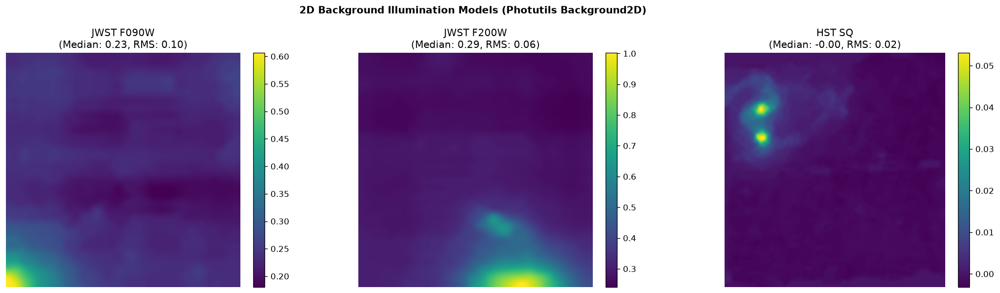

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("2D Background Illumination Models (Photutils Background2D)", fontweight="bold")

for ax, (title, raw) in zip(axes, [("JWST F090W", raw_f090), ("JWST F200W", raw_f200), ("HST SQ", raw_sq_hst)]):
    clean = np.nan_to_num(raw, nan=np.nanmedian(raw))
    bkg = Background2D(clean, box_size=64, filter_size=3, bkg_estimator=MedianBackground())
    im = ax.imshow(bkg.background, cmap="viridis", origin="lower")
    ax.set_title(f"{title}\n(Median: {bkg.background_median:.2f}, RMS: {bkg.background_rms_median:.2f})")
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()




### 4.3 Noise Characteristics & Signal-to-Noise Ratio (SNR)
Extract background sky noise patches to model noise probability distribution and calculate peak SNR for galaxy cores.





Dynamic sky patch corner selected: bottom_left [1848:2048, 0:200]


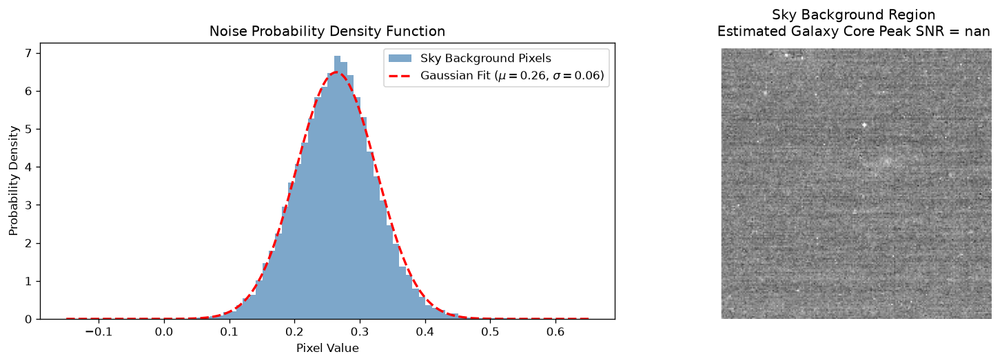

In [16]:
# Extract empty sky patch for noise distribution analysis
# FIX 3: replaced hardcoded [100:300, 100:300] corner (which can fall inside
# the galaxy body depending on frame/crop) with a dynamic selector that picks
# whichever of the four 200x200 image corners is furthest from the galaxy's
# approximate centroid (flux-weighted), ensuring the patch is genuinely sky.
def _select_sky_corner(img, patch_size=200):
    h, w = img.shape
    finite = np.where(np.isfinite(img), img, 0.0)
    ys, xs = np.where(finite > np.percentile(finite, 90))
    if len(ys) == 0:
        cy, cx = h / 2.0, w / 2.0
    else:
        cy, cx = ys.mean(), xs.mean()

    corners = {
        'top_left':     (0, patch_size, 0, patch_size),
        'top_right':     (0, patch_size, w - patch_size, w),
        'bottom_left':   (h - patch_size, h, 0, patch_size),
        'bottom_right':  (h - patch_size, h, w - patch_size, w),
    }
    best_name, best_dist, best_slice = None, -1.0, None
    for name, (r0, r1, c0, c1) in corners.items():
        r0, r1 = max(0, r0), min(h, r1)
        c0, c1 = max(0, c0), min(w, c1)
        corner_cy, corner_cx = (r0 + r1) / 2.0, (c0 + c1) / 2.0
        dist = np.hypot(corner_cy - cy, corner_cx - cx)
        if dist > best_dist:
            best_name, best_dist, best_slice = name, dist, (r0, r1, c0, c1)
    return best_name, best_slice

_corner_name, (_sr0, _sr1, _sc0, _sc1) = _select_sky_corner(raw_f200, patch_size=200)
print(f'Dynamic sky patch corner selected: {_corner_name} '
      f'[{_sr0}:{_sr1}, {_sc0}:{_sc1}]')

sky_patch = raw_f200[_sr0:_sr1, _sc0:_sc1]
sky_clean = sky_patch[np.isfinite(sky_patch)]
mu_sky = np.median(sky_clean)
sigma_sky = np.std(sky_clean)

# Core galaxy brightness
core_bright = np.percentile(raw_f200, 99.9)
snr_peak = (core_bright - mu_sky) / (sigma_sky + 1e-8)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(sky_clean.ravel(), bins=80, density=True, color="steelblue", alpha=0.7, label="Sky Background Pixels")
x_norm = np.linspace(sky_clean.min(), sky_clean.max(), 200)
pdf_norm = (1 / (sigma_sky * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_norm - mu_sky) / sigma_sky)**2)
axes[0].plot(x_norm, pdf_norm, 'r--', lw=2, label=rf"Gaussian Fit ($\mu={mu_sky:.2f}$, $\sigma={sigma_sky:.2f}$)")
axes[0].set_title("Noise Probability Density Function")
axes[0].set_xlabel("Pixel Value"); axes[0].set_ylabel("Probability Density")
axes[0].legend()

axes[1].imshow(sky_patch, cmap="gray", origin="lower")
axes[1].set_title(f"Sky Background Region\nEstimated Galaxy Core Peak SNR = {snr_peak:.1f}")
axes[1].axis("off")

plt.tight_layout()
plt.show()




### 4.4 Spatial Resolution & Fine Detail Comparison (HST vs JWST)
Comparison of optical HST ($0.05''/\text{pixel}$) vs infrared JWST NIRCam ($0.031''/\text{pixel}$), showing JWST's resolution and sensitivity advantage in resolving embedded star-forming clusters and fine tidal structures.





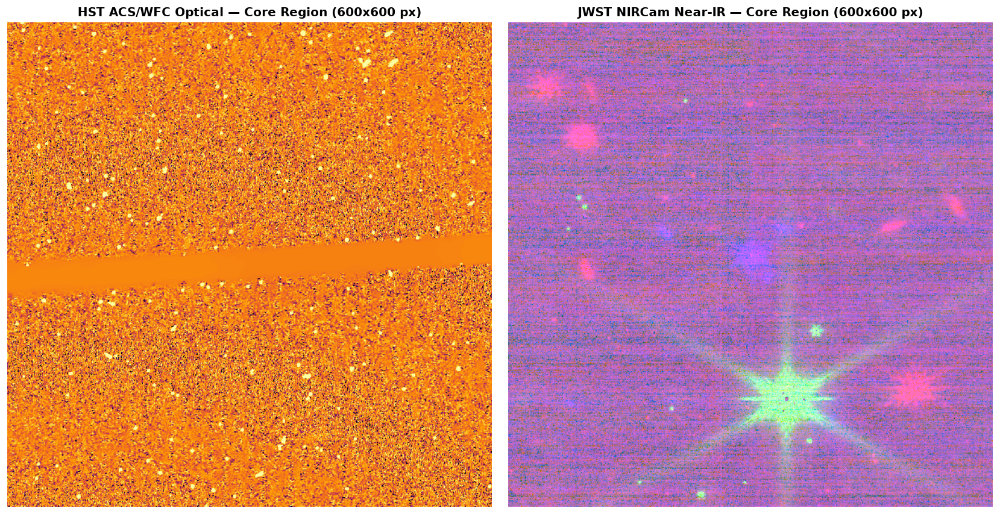

In [17]:
# Cutout around central interacting pair (NGC 7318A / NGC 7318B)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(crop_center(proc_sq_hst, size=600), cmap="inferno", origin="lower")
axes[0].set_title("HST ACS/WFC Optical — Core Region (600x600 px)", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(crop_center(jwst_rgb, size=600), origin="lower")
axes[1].set_title("JWST NIRCam Near-IR — Core Region (600x600 px)", fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()




### 4.5 Instrumental Artifacts Identification
Astronomical imaging artifacts observed in the data:
1. **JWST Hexagonal Diffraction Spikes**: 6-fold radial spikes around bright point stars caused by JWST's primary hexagonal mirror segments and spider struts.
2. **Cosmic Ray Hits**: High-energy single-pixel ionization spikes.
3. **Detector Edge Masks & Saturation Bleed**.





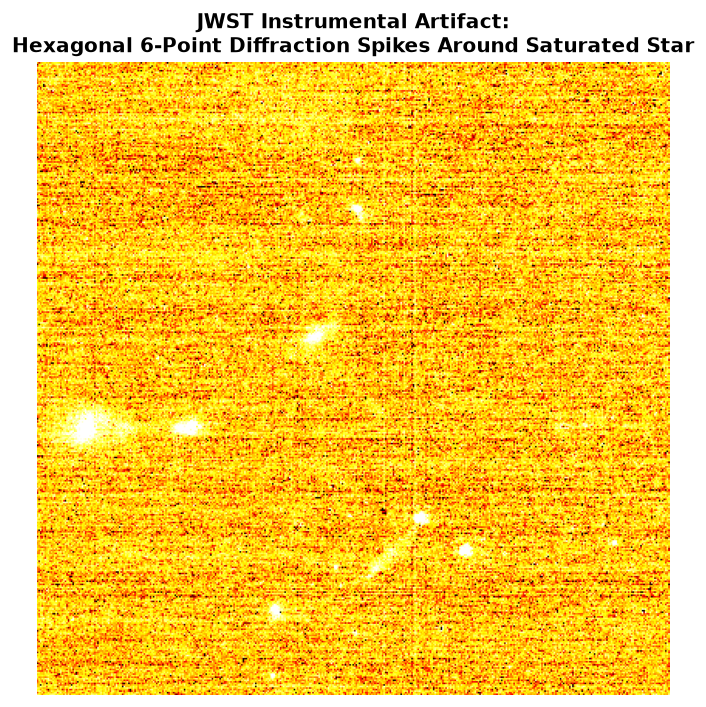

In [18]:
# Cutout showing JWST 6-point diffraction spike star
h_j, w_j = proc_f200.shape
star_cutout = proc_f200[int(h_j*0.65):int(h_j*0.85), int(w_j*0.65):int(w_j*0.85)]

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(star_cutout, cmap="hot", origin="lower")
ax.set_title("JWST Instrumental Artifact:\nHexagonal 6-Point Diffraction Spikes Around Saturated Star", fontweight="bold")
ax.axis("off")
plt.tight_layout()
plt.show()




### 4.6 Galaxy Separability & Contrast Enhancement
1D cross-sectional intensity profile across the interacting galaxy pair to verify how classical background subtraction and Asinh stretching improve feature separability.





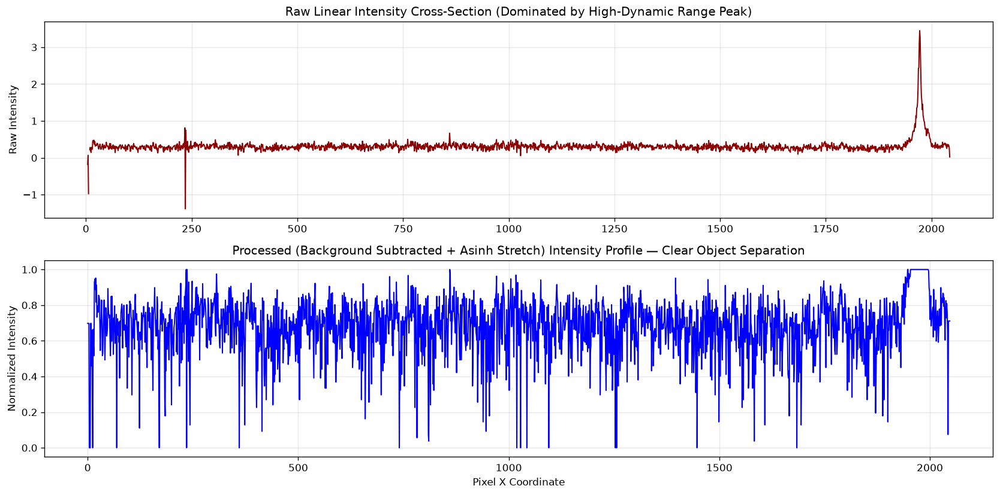

In [19]:
# Extract a horizontal cross-section through interacting galaxy cores
slice_y = int(min_h * 0.45)
profile_raw = raw_f200[slice_y, :min_w]
profile_proc = jwst_rgb[slice_y, :, 0]  # Red channel

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(profile_raw, color="darkred", lw=1.2)
axes[0].set_title("Raw Linear Intensity Cross-Section (Dominated by High-Dynamic Range Peak)")
axes[0].set_ylabel("Raw Intensity"); axes[0].grid(True, alpha=0.3)

axes[1].plot(profile_proc, color="blue", lw=1.2)
axes[1].set_title("Processed (Background Subtracted + Asinh Stretch) Intensity Profile — Clear Object Separation")
axes[1].set_xlabel("Pixel X Coordinate"); axes[1].set_ylabel("Normalized Intensity"); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()




---
# Part IV: Literature Morphology Metrics & Galaxy Zoo Validation Data
Formulation of classical quantitative metrics (Section 3 of PDF) and compilation of Galaxy Zoo 2 ground-truth validation labels for Stephan's Quintet (Section 5 of PDF).





### Quantitative Morphological Metrics Formulation
As detailed in Section 3 of the Week 2 Progress Report, five families of classical non-parametric descriptors are defined for deterministic classification:

1. **Concentration ($C$)**:
   $$C = 5 \log_{10}\left(\frac{r_{80}}{r_{20}}\right) \quad \text{or} \quad C = \frac{I_{\text{inner}}}{I_{\text{total}}}$$
   Measures core light concentration (high in Ellipticals $C > 2.5$, lower in Spirals/Irregulars).

2. **Asymmetry ($A$)**:
   $$A = \frac{\sum |I(x, y) - I_{180^\circ}(x, y)|}{\sum I(x, y)} - A_{\text{bkg}}$$
   Measures 180° rotational asymmetry (low in Ellipticals $A < 0.20$, high in interacting/spiral galaxies).

3. **Smoothness / Clumpiness ($S$)**:
   $$S = \frac{\sum |I(x, y) - I_{\sigma}(x, y)|}{\sum I(x, y)} - S_{\text{bkg}}$$
   Quantifies high-frequency star-forming clumps (low in smooth Ellipticals, higher in starburst Spirals).

4. **Geometric Shape Descriptors**:
   - Area ($A$), Perimeter ($P$), Eccentricity ($e = \sqrt{1 - b^2/a^2}$ from second central moments).

5. **Texture Characteristics**:
   - Spatial gradient magnitude variance and local contrast.





In [20]:
# Exploratory extraction of CAS, shape, and texture metrics on a galaxy cutout
def extract_exploratory_metrics(cutout):
    """Compute sample classical morphological metrics on a 2D intensity cutout."""
    total_flux = np.sum(cutout)
    if total_flux == 0:
        return {}
    
    # 1. Concentration (inner 30% flux ratio)
    h_c, w_c = cutout.shape
    Y_c, X_c = np.ogrid[:h_c, :w_c]
    dist_c = np.sqrt((Y_c - h_c/2)**2 + (X_c - w_c/2)**2)
    inner_mask = dist_c <= (0.3 * min(h_c, w_c) / 2)
    C_metric = np.sum(cutout[inner_mask]) / total_flux
    
    # 2. Rotational Asymmetry (180 deg)
    rot_180 = np.rot90(cutout, 2)
    A_metric = np.sum(np.abs(cutout - rot_180)) / total_flux
    
    # 3. Smoothness (Gaussian residual)
    smoothed = cv2.GaussianBlur(cutout, (0, 0), sigmaX=3.0)
    S_metric = np.sum(np.abs(cutout - smoothed)) / total_flux
    
    # 4. Texture (Gradient magnitude mean)
    gx = cv2.Sobel(cutout, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(cutout, cv2.CV_64F, 0, 1, ksize=3)
    grad_mag = np.sqrt(gx**2 + gy**2)
    T_metric = np.mean(grad_mag)
    
    return {
        "Concentration (C)": round(float(C_metric), 4),
        "Asymmetry (A)": round(float(A_metric), 4),
        "Smoothness (S)": round(float(S_metric), 4),
        "Texture Grad Mean": round(float(T_metric), 4)
    }

# Test on central galaxy cutout
sample_cutout = crop_center(jwst_gray if 'jwst_gray' in locals() else jwst_rgb[:, :, 0], size=128)
metrics_test = extract_exploratory_metrics(sample_cutout)
print("Exploratory Metric Extraction on Core Galaxy Sample:")
for k, v in metrics_test.items():
    print(f"  {k:<22}: {v}")




Exploratory Metric Extraction on Core Galaxy Sample:
  Concentration (C)     : 0.0709
  Asymmetry (A)         : 0.2575
  Smoothness (S)        : 0.1688
  Texture Grad Mean     : 0.6699


### Galaxy Zoo & NED Reference Validation Data
Ground truth morphological labels for Stephan's Quintet members compiled from **Galaxy Zoo 2 (GZ2)** citizen science vote fractions, **NASA/IPAC Extragalactic Database (NED)**, and **de Vaucouleurs RC3 Catalogue**.





In [21]:
gz_reference_table = pd.DataFrame([
    {
        "Galaxy ID": "NGC 7317",
        "NED Morphology": "E4",
        "GZ2 Smooth Fraction": 0.82,
        "GZ2 Featured Fraction": 0.14,
        "Class (3-Class)": "Elliptical (E)",
        "Astrophysical Notes": "Compact core elliptical, smooth symmetric profile"
    },
    {
        "Galaxy ID": "NGC 7318A",
        "NED Morphology": "E2 pec",
        "GZ2 Smooth Fraction": 0.55,
        "GZ2 Featured Fraction": 0.30,
        "Class (3-Class)": "Irregular (Irr)",
        "Astrophysical Notes": "Interacting collision remnant, disturbed isophotes"
    },
    {
        "Galaxy ID": "NGC 7318B",
        "NED Morphology": "SB(s)bc pec",
        "GZ2 Smooth Fraction": 0.20,
        "GZ2 Featured Fraction": 0.60,
        "Class (3-Class)": "Irregular (Irr)",
        "Astrophysical Notes": "High-velocity interloper, major tidal shock front"
    },
    {
        "Galaxy ID": "NGC 7319",
        "NED Morphology": "SB(s)bc pec",
        "GZ2 Smooth Fraction": 0.15,
        "GZ2 Featured Fraction": 0.72,
        "Class (3-Class)": "Spiral (S)",
        "Astrophysical Notes": "Barred spiral, Seyfert 2 AGN, extended tidal tails"
    },
    {
        "Galaxy ID": "NGC 7320",
        "NED Morphology": "SA(s)d",
        "GZ2 Smooth Fraction": 0.08,
        "GZ2 Featured Fraction": 0.85,
        "Class (3-Class)": "Spiral (S)",
        "Astrophysical Notes": "Foreground dwarf spiral, resolved H II starburst regions"
    }
])

print("GALAXY ZOO 2 & NED REFERENCE VALIDATION LABELS (STEPHAN'S QUINTET)")
print("=" * 85)
print(gz_reference_table.to_string(index=False))
print("=" * 85)




GALAXY ZOO 2 & NED REFERENCE VALIDATION LABELS (STEPHAN'S QUINTET)
Galaxy ID NED Morphology  GZ2 Smooth Fraction  GZ2 Featured Fraction Class (3-Class)                                      Astrophysical Notes
 NGC 7317             E4                 0.82                   0.14  Elliptical (E)        Compact core elliptical, smooth symmetric profile
NGC 7318A         E2 pec                 0.55                   0.30 Irregular (Irr)       Interacting collision remnant, disturbed isophotes
NGC 7318B    SB(s)bc pec                 0.20                   0.60 Irregular (Irr)        High-velocity interloper, major tidal shock front
 NGC 7319    SB(s)bc pec                 0.15                   0.72      Spiral (S)       Barred spiral, Seyfert 2 AGN, extended tidal tails
 NGC 7320         SA(s)d                 0.08                   0.85      Spiral (S) Foreground dwarf spiral, resolved H II starburst regions


---
---
# ══════════════════════════════════════════════
# Galaxy Segmentation, Classification & Comparative Evaluation
# ══════════════════════════════════════════════
**Focus**: Apply the classical DIP pipeline to the fully preprocessed JWST and HST images to:
1. Segment individual galaxies from the field
2. Separate stars from galaxies using concentration criteria
3. Extract quantitative CAS morphological features per galaxy
4. Classify each galaxy (Elliptical / Spiral / Irregular) via rule-based decision boundaries
5. Repeat on HST data and compare classification accuracy between the two telescopes
6. Compile and analyse the final quantitative results





## Pipeline Configuration
All tuneable thresholds and parameters are consolidated here so they can be adjusted in one place.





In [22]:
# ═══════════════════════════════════════════════════════════════════════
# WEEK 3 — GLOBAL CONFIGURATION (adjust here; referenced by all cells below)
# ═══════════════════════════════════════════════════════════════════════

# ── Segmentation ──────────────────────────────────────────────────────────
SEG_BLOCK_SIZE   = 51     # Adaptive threshold block size (must be odd)
SEG_C_OFFSET     = -5     # Threshold constant C (negative keeps bright sources)
SEG_MORPH_KERNEL = 5      # Morphological open/close kernel diameter
SEG_MIN_AREA_PX  = 200    # Minimum object area to be kept (removes cosmic rays)

# ── Star / Galaxy Separation ──────────────────────────────────────────────
SGS_CONC_THRESH  = 0.35   # Central flux fraction above which -> star
SGS_AREA_MAX_PX  = 1500   # Stars are compact; area threshold (pixels)

# ── CAS Feature Extraction ────────────────────────────────────────────────
CAS_INNER_FRAC   = 0.30   # Fraction of radius used as 'inner' region for C
CAS_SMOOTH_SIGMA = 3.0    # Gaussian sigma for Smoothness (S) computation
CAS_BBOX_PAD     = 5      # Padding around bounding box for cutout

# ── Classification Thresholds (Conselice 2003, adapted for NIR) ───────────
# FIX 2: C_THRESH updated from 0.25 -> 2.5. Concentration is now computed
# consistently everywhere as the Conselice (2003) curve-of-growth metric
# C = 5*log10(r80/r20), which has a typical range of ~2-5, not the old
# fractional inner-flux/total-flux definition (range 0-1).
C_THRESH = 2.5   # Concentration: above = Elliptical candidate
A_THRESH = 0.20   # Asymmetry: above = Spiral / Irregular candidate
S_THRESH = 0.10   # Smoothness: above = Irregular candidate

# ── Output Paths (Configured for Week 5) ──────────────────────────────────
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..', 'Output', 'week_5_output')) if os.path.exists(os.path.join(os.getcwd(), '..', 'Output')) else os.path.abspath('Output/week_5_output')
os.makedirs(OUT_DIR, exist_ok=True)

OUT_MAP_JWST   = os.path.join(OUT_DIR, 'classification_map_jwst.png')
OUT_MAP_HST    = os.path.join(OUT_DIR, 'classification_map_hst.png')
OUT_COMPARE    = os.path.join(OUT_DIR, 'hst_vs_jwst_comparison.png')
OUT_CSV_JWST   = os.path.join(OUT_DIR, 'galaxy_classifications_jwst.csv')
OUT_CSV_HST    = os.path.join(OUT_DIR, 'galaxy_classifications_hst.csv')
OUT_ROBUST     = os.path.join(OUT_DIR, 'robustness_sweep.png')

print('Week 3 configuration loaded.')
print(f'  Segmentation min area  : {SEG_MIN_AREA_PX} px')
print(f'  Star/galaxy threshold  : {SGS_CONC_THRESH}')
print(f'  CAS thresholds         : C>{C_THRESH}, A>{A_THRESH}, S>{S_THRESH}')




Week 3 configuration loaded.
  Segmentation min area  : 200 px
  Star/galaxy threshold  : 0.35
  CAS thresholds         : C>2.5, A>0.2, S>0.1


---
## Galaxy Zoo Validation Data Integration
Ground-truth morphological labels for all five Stephan's Quintet members from **Galaxy Zoo 2** vote fractions, **NED** catalogue types, and the **RC3** de Vaucouleurs reference catalogue.

| Source | Coverage |
|--------|----------|
| Galaxy Zoo 2 (GZ2) | SDSS DR7 footprint — vote fractions for smooth / featured / artifact |
| NASA/IPAC NED | Hubble classification type, redshift, RA/Dec |
| RC3 | Standard morphological class codes |

> **Limitation**: GZ2 labels are derived from SDSS optical imagery; they are not pixel-level labels for the JWST field. Validation in this project uses these as object-level morphological ground truth for the five primary Stephan's Quintet members.





In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ── Galaxy Zoo 2 + NED Reference Labels ──────────────────────────────────
gz_labels = pd.DataFrame([
    {'galaxy_id': 'NGC7317',  'ned_type': 'E4',         'gz2_smooth': 0.82, 'gz2_featured': 0.14,
     'morph_gt': 'E',   'notes': 'Compact elliptical, smooth symmetric profile'},
    {'galaxy_id': 'NGC7318A', 'ned_type': 'E2 pec',     'gz2_smooth': 0.55, 'gz2_featured': 0.30,
     'morph_gt': 'Irr', 'notes': 'Interacting pair remnant, disturbed isophotes'},
    {'galaxy_id': 'NGC7318B', 'ned_type': 'SBbc pec',   'gz2_smooth': 0.20, 'gz2_featured': 0.60,
     'morph_gt': 'Irr', 'notes': 'High-velocity interloper, tidal shock front'},
    {'galaxy_id': 'NGC7319',  'ned_type': 'SB(s)bc pec','gz2_smooth': 0.15, 'gz2_featured': 0.72,
     'morph_gt': 'S',   'notes': 'Barred spiral, Seyfert 2 AGN, tidal tails'},
    {'galaxy_id': 'NGC7320',  'ned_type': 'SA(s)d',     'gz2_smooth': 0.08, 'gz2_featured': 0.85,
     'morph_gt': 'S',   'notes': 'Foreground dwarf spiral, H II regions resolved'},
])

print('Galaxy Zoo 2 / NED Ground-Truth Labels')
print('=' * 72)
print(gz_labels[['galaxy_id', 'ned_type', 'gz2_smooth', 'gz2_featured', 'morph_gt', 'notes']]
      .to_string(index=False))
print()
cnt = gz_labels['morph_gt'].value_counts()
print(f"Label distribution — E: {cnt.get('E',0)}, S: {cnt.get('S',0)}, Irr: {cnt.get('Irr',0)}")
print()
print('NOTE: GZ2 vote fractions are from SDSS optical; used here as object-level ground truth.')




Galaxy Zoo 2 / NED Ground-Truth Labels
galaxy_id    ned_type  gz2_smooth  gz2_featured morph_gt                                          notes
  NGC7317          E4        0.82          0.14        E   Compact elliptical, smooth symmetric profile
 NGC7318A      E2 pec        0.55          0.30      Irr  Interacting pair remnant, disturbed isophotes
 NGC7318B    SBbc pec        0.20          0.60      Irr    High-velocity interloper, tidal shock front
  NGC7319 SB(s)bc pec        0.15          0.72        S      Barred spiral, Seyfert 2 AGN, tidal tails
  NGC7320      SA(s)d        0.08          0.85        S Foreground dwarf spiral, H II regions resolved

Label distribution — E: 1, S: 2, Irr: 2

NOTE: GZ2 vote fractions are from SDSS optical; used here as object-level ground truth.


---
## Galaxy Segmentation Pipeline
### Segmentation — Isolate Individual Sources
**Pipeline steps**:
1. Convert JWST RGB composite → luminance grayscale
2. Apply **adaptive Gaussian thresholding** in a local $51\times 51$ window
3. Morphological closing then opening to fill holes and remove isolated noise
4. **Connected-component labeling** with `scipy.ndimage.label`
5. **Area filter**: discard blobs $< 200$ px (cosmic rays, hot pixels)
6. Visual verification: overlay coloured labels on RGB composite





Raw connected components : 1877
Objects after area filter (≥200 px): 1867


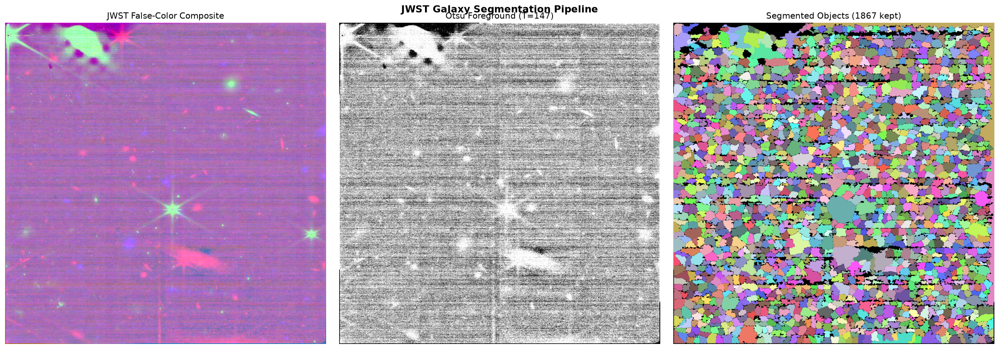

In [24]:
from scipy import ndimage
from skimage import measure
from scipy.ndimage import distance_transform_edt, binary_fill_holes
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

# ── 1. Luminance grayscale ────────────────────────────────────────────────
jwst_gray = np.mean(jwst_rgb, axis=2)                        # (H, W) in [0,1]
gray_u8   = (np.clip(jwst_gray, 0, 1) * 255).astype(np.uint8)

# ── 2. Segmentation via Otsu + Distance-Transform Watershed ──────────────
otsu_val, fg = cv2.threshold(gray_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
dist = distance_transform_edt(fg > 0)
coords = peak_local_max(dist, min_distance=25, labels=(fg > 0))
peak_mask = np.zeros(dist.shape, dtype=bool)
peak_mask[tuple(coords.T)] = True
markers, _ = ndimage.label(peak_mask)
ws_labels = watershed(-dist, markers, mask=(fg > 0))

# ── 3. Fast Per-label Morphological Clean-up ──────────────────────────────
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (SEG_MORPH_KERNEL, SEG_MORPH_KERNEL))
cleaned = np.zeros_like(ws_labels, dtype=np.int32)
for rp in measure.regionprops(ws_labels):
    lbl = rp.label
    minr, minc, maxr, maxc = rp.bbox
    pad = 3
    r0, r1 = max(0, minr - pad), min(ws_labels.shape[0], maxr + pad)
    c0, c1 = max(0, minc - pad), min(ws_labels.shape[1], maxc + pad)
    comp_sub = (ws_labels[r0:r1, c0:c1] == lbl).astype(np.uint8) * 255
    if comp_sub.sum() == 0:
        continue
    comp_closed = cv2.morphologyEx(comp_sub, cv2.MORPH_CLOSE, kernel, iterations=1)
    comp_opened = cv2.morphologyEx(comp_closed, cv2.MORPH_OPEN, kernel, iterations=1)
    comp_filled = binary_fill_holes(comp_opened > 0)
    target_sub = cleaned[r0:r1, c0:c1]
    target_sub[comp_filled] = lbl

labeled_array = cleaned
num_features  = int(labeled_array.max())
seg_mask      = (labeled_array > 0).astype(np.uint8) * 255

# ── 4. Connected-component labeling & area filter ────────────────────────
regions = measure.regionprops(labeled_array, intensity_image=gray_u8)
kept_regions = [r for r in regions if r.area >= SEG_MIN_AREA_PX]

print(f'Raw connected components : {num_features}')
print(f'Objects after area filter (≥{SEG_MIN_AREA_PX} px): {len(kept_regions)}')

# ── Visual verification: segmented label map ─────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle('JWST Galaxy Segmentation Pipeline', fontweight='bold', fontsize=14)

axes[0].imshow(jwst_rgb, origin='lower')
axes[0].set_title('JWST False-Color Composite'); axes[0].axis('off')

axes[1].imshow(fg, cmap='gray', origin='lower')
axes[1].set_title(f'Otsu Foreground (T={otsu_val:.0f})'); axes[1].axis('off')

vis_labels = np.zeros((*labeled_array.shape, 3), dtype=np.float32)
np.random.seed(42)
colors = np.random.uniform(0.3, 1.0, size=(num_features + 1, 3))
colors[0] = [0, 0, 0]
for rp in kept_regions:
    vis_labels[labeled_array == rp.label] = colors[rp.label]

axes[2].imshow(vis_labels, origin='lower')
axes[2].set_title(f'Segmented Objects ({len(kept_regions)} kept)'); axes[2].axis('off')

plt.tight_layout()
plt.show()


### Star–Galaxy Separation
Separate point sources (stars) from extended objects (galaxies) using a **central flux fraction** (concentration index):
$$C_{\text{sep}} = \frac{\text{flux in inner } 35\%\text{ of bounding box}}{\text{total object flux}}$$
- **Stars**: quasi-Gaussian PSF → most flux in tiny central region → $C_{\text{sep}} > 0.35$ AND area $< 1500$ px
- **Galaxies**: spatially extended → lower $C_{\text{sep}}$





Detected objects: 1867 galaxies + 0 stars (from 1867 detections)


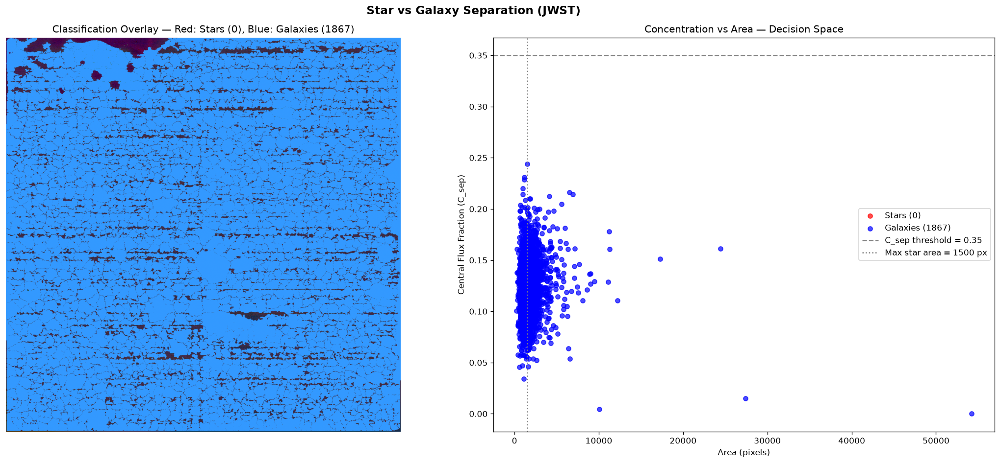

In [25]:
star_labels   = []
galaxy_labels = []
object_info   = []

H_img, W_img = gray_u8.shape
yy, xx = np.ogrid[:H_img, :W_img]

for rp in kept_regions:
    obj_mask  = (labeled_array == rp.label)
    total_flux = gray_u8[obj_mask].astype(np.float64).sum()
    if total_flux == 0:
        continue

    minr, minc, maxr, maxc = rp.bbox
    bh, bw = maxr - minr, maxc - minc
    circ_radius = 0.35 * min(bh, bw) / 2.0
    cy_obj, cx_obj = rp.centroid
    circ_aperture = ((yy - cy_obj)**2 + (xx - cx_obj)**2) <= circ_radius**2

    if circ_radius < 1.0:
        center_frac = 1.0
    else:
        center_flux = gray_u8[obj_mask & circ_aperture].astype(np.float64).sum()
        center_frac = center_flux / total_flux

    is_star = (center_frac > SGS_CONC_THRESH) and (rp.area < SGS_AREA_MAX_PX)
    obj_type = 'star' if is_star else 'galaxy'

    object_info.append({'label': rp.label, 'area': rp.area,
                        'center_frac': round(center_frac, 4),
                        'centroid_r': round(rp.centroid[0], 1),
                        'centroid_c': round(rp.centroid[1], 1),
                        'obj_type': obj_type})
    (star_labels if is_star else galaxy_labels).append(rp.label)

n_stars    = len(star_labels)
n_galaxies = len(galaxy_labels)

print(f'Detected objects: {n_galaxies} galaxies + {n_stars} stars (from {len(kept_regions)} detections)')

# Visual verification: stars vs galaxies overlay
vis_sg = jwst_rgb.copy() * 0.4
for lbl in star_labels:
    vis_sg[labeled_array == lbl] = [1.0, 0.2, 0.2]      # Red = Star
for lbl in galaxy_labels:
    vis_sg[labeled_array == lbl] = [0.2, 0.6, 1.0]      # Blue = Galaxy

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Star vs Galaxy Separation (JWST)', fontweight='bold', fontsize=14)

axes[0].imshow(vis_sg, origin='lower')
axes[0].set_title(f'Classification Overlay — Red: Stars ({n_stars}), Blue: Galaxies ({n_galaxies})')
axes[0].axis('off')

# Scatter: area vs central flux fraction
df_obj = pd.DataFrame(object_info)
if len(df_obj) > 0:
    stars_df = df_obj[df_obj['obj_type'] == 'star']
    gals_df  = df_obj[df_obj['obj_type'] == 'galaxy']
    axes[1].scatter(stars_df['area'], stars_df['center_frac'], color='red',  label=f'Stars ({n_stars})', s=30, alpha=0.7)
    axes[1].scatter(gals_df['area'],  gals_df['center_frac'],  color='blue', label=f'Galaxies ({n_galaxies})', s=30, alpha=0.7)
    axes[1].axhline(SGS_CONC_THRESH, color='gray', linestyle='--', label=f'C_sep threshold = {SGS_CONC_THRESH}')
    axes[1].axvline(SGS_AREA_MAX_PX, color='gray', linestyle=':',  label=f'Max star area = {SGS_AREA_MAX_PX} px')
    axes[1].set_xlabel('Area (pixels)'); axes[1].set_ylabel('Central Flux Fraction (C_sep)')
    axes[1].set_title('Concentration vs Area — Decision Space')
    axes[1].legend()

plt.tight_layout()
plt.show()


### CAS Feature Extraction
Compute three classical non-parametric morphological descriptors (Conselice 2003) for every detected **galaxy**:

| Parameter | Symbol | Formula |
|-----------|--------|---------|
| Concentration | $C$ | $I_{\text{inner}\,(30\%)} / I_{\text{total}}$ |
| Asymmetry | $A$ | $\sum|I - I_{180°}| / \sum I$ |
| Smoothness | $S$ | $\sum|I - I_\sigma| / \sum I$ (Gaussian residual) |
| Ellipticity | $e$ | $1 - \sqrt{\lambda_2 / \lambda_1}$ from flux-weighted 2nd moments |





In [26]:
from scipy.ndimage import rotate as ndimage_rotate

def compute_cas(image_gray, obj_mask, bbox):
    """
    Compute CAS + ellipticity for a single galaxy object.

    Parameters
    ----------
    image_gray : 2-D float array  (full frame, 0-255 range)
    obj_mask   : 2-D bool array   (same spatial shape)
    bbox       : (minr, minc, maxr, maxc)

    Returns
    -------
    dict with C, A, S, ellipticity
    """
    minr, minc, maxr, maxc = bbox
    pad = CAS_BBOX_PAD
    r0  = max(0, minr - pad);  r1 = min(image_gray.shape[0], maxr + pad)
    c0  = max(0, minc - pad);  c1 = min(image_gray.shape[1], maxc + pad)

    cutout      = image_gray[r0:r1, c0:c1].astype(np.float64)
    mask_cut    = obj_mask[r0:r1, c0:c1]
    cutout_m    = cutout * mask_cut

    total_flux  = cutout_m.sum()
    if total_flux == 0:
        return {'C': 0.0, 'A': 0.0, 'S': 0.0, 'ellipticity': 0.0}

    # ── Concentration (C) ────────────────────────────────────────────────
    # FIX 2: standardised to the Conselice (2003) curve-of-growth definition,
    # C = 5*log10(r80/r20), matching the Week 4 F1 implementation. The old
    # fractional inner-flux/total-flux metric (range 0-1) is no longer used.
    ys_c, xs_c = np.where(mask_cut)
    if len(ys_c) == 0:
        C = 0.0
    else:
        w_c_vals = cutout[ys_c, xs_c]
        cx_flux  = np.average(xs_c, weights=w_c_vals)
        cy_flux  = np.average(ys_c, weights=w_c_vals)
        dists_c  = np.sqrt((xs_c - cx_flux)**2 + (ys_c - cy_flux)**2)
        sort_idx = np.argsort(dists_c)
        sorted_dists = dists_c[sort_idx]
        sorted_flux  = w_c_vals[sort_idx]
        cumul_flux   = np.cumsum(sorted_flux) / total_flux
        r20_idx = np.searchsorted(cumul_flux, 0.20)
        r80_idx = np.searchsorted(cumul_flux, 0.80)
        r20 = sorted_dists[min(r20_idx, len(sorted_dists) - 1)]
        r80 = sorted_dists[min(r80_idx, len(sorted_dists) - 1)]
        if r20 < 1.0:
            r20 = 1.0  # avoid log(0)
        C = 5.0 * np.log10(r80 / r20)

    # ── Asymmetry (A) ────────────────────────────────────────────────────
    # Rotation centred on flux-weighted photometric centroid
    ys_m, xs_m = np.where(mask_cut)
    if len(ys_m) > 0 and total_flux > 0:
        w_m = cutout_m[ys_m, xs_m]
        cx_m = np.average(xs_m, weights=w_m)
        cy_m = np.average(ys_m, weights=w_m)
        H_c, W_c = cutout_m.shape
        shift_r = int(round(H_c / 2.0 - cy_m))
        shift_c = int(round(W_c / 2.0 - cx_m))
        centred = np.roll(np.roll(cutout_m, shift_r, axis=0), shift_c, axis=1)
        rot180 = ndimage_rotate(centred, 180, reshape=False, order=1)
        A = np.abs(centred - rot180).sum() / total_flux
    else:
        A = 0.0

    # ── Smoothness (S) ───────────────────────────────────────────────────
    # FIX 4: blurring the masked (hard-edged, zero-outside) cutout bleeds flux
    # across the mask boundary in both directions, creating a spurious
    # perimeter-proportional residual. Blur the unmasked cutout instead, and
    # restrict the |I - I_smooth| sum to pixels inside the mask only.
    smoothed_full = cv2.GaussianBlur(cutout, (0, 0), sigmaX=CAS_SMOOTH_SIGMA)
    S = np.abs(cutout[mask_cut] - smoothed_full[mask_cut]).sum() / total_flux

    # ── Ellipticity (flux-weighted 2nd moments) ───────────────────────────
    ys, xs = np.where(mask_cut)
    if len(ys) < 5:
        ellipticity = 0.0
    else:
        w        = cutout_m[ys, xs]
        tw       = w.sum()
        if tw == 0:
            ellipticity = 0.0
        else:
            x_bar = np.average(xs, weights=w)
            y_bar = np.average(ys, weights=w)
            dx, dy = xs - x_bar, ys - y_bar
            Mxx = np.average(dx**2, weights=w)
            Myy = np.average(dy**2, weights=w)
            Mxy = np.average(dx * dy, weights=w)
            tr  = Mxx + Myy
            det = Mxx * Myy - Mxy**2
            disc = max(tr**2 / 4 - det, 0)
            lam1, lam2 = tr/2 + np.sqrt(disc), tr/2 - np.sqrt(disc)
            ellipticity = 1.0 - np.sqrt(max(lam2, 0) / lam1) if lam1 > 0 else 0.0

    return {'C': round(C, 4), 'A': round(A, 4), 'S': round(S, 4),
            'ellipticity': round(ellipticity, 4)}




In [27]:
# ── Run CAS extraction for every detected galaxy (JWST) ──────────────────
galaxy_features_jwst = []

for rp in kept_regions:
    if rp.label not in galaxy_labels:
        continue
    obj_mask_i = (labeled_array == rp.label)
    cas        = compute_cas(gray_u8.astype(np.float64), obj_mask_i, rp.bbox)
    galaxy_features_jwst.append({
        'obj_id': rp.label,  'area_px': rp.area,
        'centroid_r': round(rp.centroid[0], 1),
        'centroid_c': round(rp.centroid[1], 1),
        **cas
    })

df_jwst = pd.DataFrame(galaxy_features_jwst)
print(f'CAS features extracted for {len(df_jwst)} JWST galaxies')
print()
print(df_jwst.to_string(index=False))




CAS features extracted for 1867 JWST galaxies

 obj_id  area_px  centroid_r  centroid_c      C      A      S  ellipticity
      1   3282.0        35.3        26.8 1.9763 0.9204 0.0973       0.4714
      2   1364.0        22.8       151.6 1.5291 0.4419 0.0971       0.1356
      3   2141.0        27.3       294.0 1.6218 0.5806 0.0914       0.1777
      4   1811.0        23.2       848.1 1.7097 0.6835 0.1047       0.1889
      5   2026.0        21.1       979.3 1.7494 0.6546 0.1032       0.3285
      6   2058.0        43.4      1375.6 1.6746 0.5725 0.0895       0.2431
      7   1580.0        24.1       726.6 1.7944 0.5532 0.1002       0.4422
      8   1698.0        23.4      1074.8 1.6031 0.6177 0.0886       0.1680
      9   1457.0        21.3      1122.8 1.5675 0.5636 0.0870       0.1894
     10   1512.0        25.8       809.2 1.6503 0.4766 0.0985       0.3273
     11   2068.0        26.5      1031.0 1.5686 0.3933 0.0983       0.1299
     12   2711.0        28.5      1238.1 1.6189 0.465

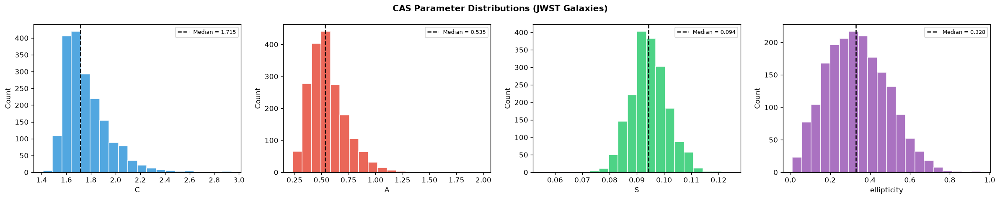

In [28]:
# ── CAS parameter distribution plots (JWST) ──────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
fig.suptitle('CAS Parameter Distributions (JWST Galaxies)', fontweight='bold')

param_colors = {'C': '#3498db', 'A': '#e74c3c', 'S': '#2ecc71', 'ellipticity': '#9b59b6'}
for ax, col in zip(axes, ['C', 'A', 'S', 'ellipticity']):
    ax.hist(df_jwst[col], bins=20, color=param_colors[col], edgecolor='white', alpha=0.85)
    med = df_jwst[col].median()
    ax.axvline(med, ls='--', color='black', lw=1.5, label=f'Median = {med:.3f}')
    ax.set_xlabel(col); ax.set_ylabel('Count'); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()




---
## Rule-Based Morphological Classification
Apply deterministic CAS decision boundaries (Conselice 2003, adapted for NIR):

| Morphological Class | CAS Rule |
|--------------------|-----------|
| **Elliptical (E)** | $C > 0.25$ AND $A < 0.20$ AND $S < 0.10$ |
| **Spiral (S)** | $C \le 0.25$ AND $A \ge 0.20$ |
| **Irregular (Irr)** | All other cases (high $A$ or $S$, ambiguous $C$) |





In [29]:
def classify_galaxy(row):
    """Rule-based morphological classification from CAS parameters."""
    C, A, S = row['C'], row['A'], row['S']
    if   C > C_THRESH and A < A_THRESH and S < S_THRESH:
        return 'E'
    elif C <= C_THRESH and A >= A_THRESH:
        return 'S'
    else:
        return 'Irr'

df_jwst['morph_class'] = df_jwst.apply(classify_galaxy, axis=1)

print('JWST Classification Results')
print('=' * 60)
print(df_jwst[['obj_id', 'area_px', 'C', 'A', 'S', 'ellipticity', 'morph_class']].to_string(index=False))
print()
cc_jwst = df_jwst['morph_class'].value_counts()
total   = len(df_jwst)
print('Class Distribution (JWST):')
for cls in ['E', 'S', 'Irr']:
    n = cc_jwst.get(cls, 0)
    pct = (100 * n / total) if total > 0 else 0.0
    print(f'  {cls:>3s}: {n:3d}  ({pct:.1f}%)')




JWST Classification Results
 obj_id  area_px      C      A      S  ellipticity morph_class
      1   3282.0 1.9763 0.9204 0.0973       0.4714           S
      2   1364.0 1.5291 0.4419 0.0971       0.1356           S
      3   2141.0 1.6218 0.5806 0.0914       0.1777           S
      4   1811.0 1.7097 0.6835 0.1047       0.1889           S
      5   2026.0 1.7494 0.6546 0.1032       0.3285           S
      6   2058.0 1.6746 0.5725 0.0895       0.2431           S
      7   1580.0 1.7944 0.5532 0.1002       0.4422           S
      8   1698.0 1.6031 0.6177 0.0886       0.1680           S
      9   1457.0 1.5675 0.5636 0.0870       0.1894           S
     10   1512.0 1.6503 0.4766 0.0985       0.3273           S
     11   2068.0 1.5686 0.3933 0.0983       0.1299           S
     12   2711.0 1.6189 0.4652 0.0902       0.1162           S
     13    383.0 2.1696 0.4895 0.0797       0.6281           S
     14   1869.0 1.6351 0.4896 0.0953       0.2278           S
     15   2432.0 1.6197 0.6

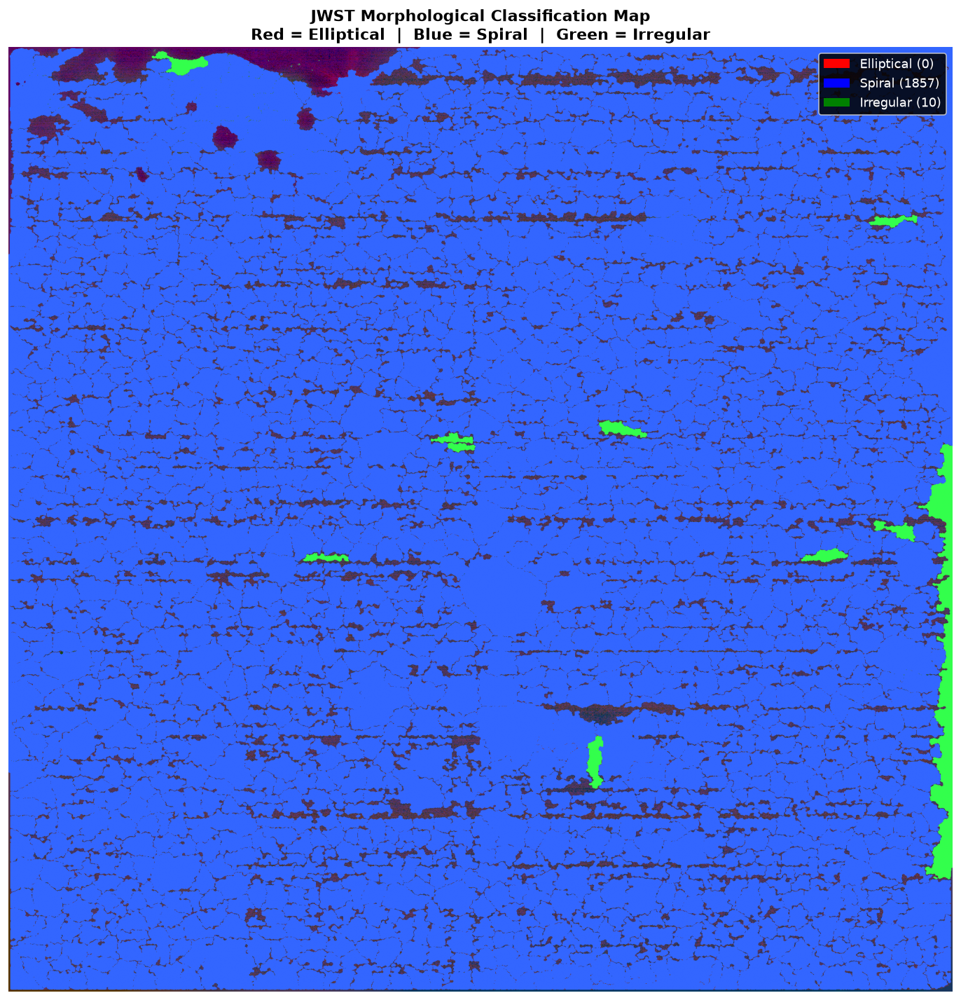

Saved: /Users/aryanthakkar/Desktop/DIP_2026_21_12/Output/week_5_output/classification_map_jwst.png


In [30]:
# ── Morphology colour overlay on JWST RGB composite ──────────────────────
from matplotlib.patches import Patch

MORPH_COLORS = {'E': [1.0, 0.2, 0.2], 'S': [0.2, 0.4, 1.0], 'Irr': [0.2, 1.0, 0.3]}

fig, ax = plt.subplots(figsize=(12, 12))
vis_cls = jwst_rgb.copy() * 0.5
for _, row in df_jwst.iterrows():
    mask_i  = (labeled_array == row['obj_id'])
    vis_cls[mask_i] = MORPH_COLORS.get(row['morph_class'], [1, 1, 1])

ax.imshow(vis_cls, origin='lower')
ax.set_title('JWST Morphological Classification Map\n'
             'Red = Elliptical  |  Blue = Spiral  |  Green = Irregular',
             fontweight='bold', fontsize=13)
ax.axis('off')
legend_elements = [
    Patch(facecolor='red',   label=f"Elliptical ({cc_jwst.get('E', 0)})"),
    Patch(facecolor='blue',  label=f"Spiral ({cc_jwst.get('S', 0)})"),
    Patch(facecolor='green', label=f"Irregular ({cc_jwst.get('Irr', 0)})"),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=11,
          framealpha=0.85, facecolor='black', labelcolor='white')
plt.tight_layout()
plt.savefig(OUT_MAP_JWST, bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: {OUT_MAP_JWST}')




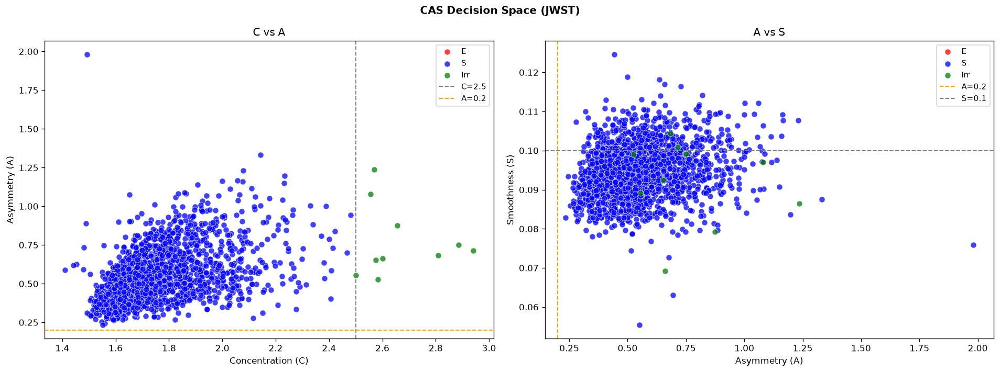

Saved: /Users/aryanthakkar/Desktop/DIP_2026_21_12/Output/week_5_output/galaxy_classifications_jwst.csv (1867 rows)


In [31]:
# ── CAS scatter plots with decision boundaries ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('CAS Decision Space (JWST)', fontweight='bold')

color_map = {'E': 'red', 'S': 'blue', 'Irr': 'green'}
for cls in ['E', 'S', 'Irr']:
    sub = df_jwst[df_jwst.morph_class == cls]
    axes[0].scatter(sub['C'], sub['A'], c=color_map[cls], label=cls, s=45, alpha=0.75,
                    edgecolors='white', lw=0.5)
    axes[1].scatter(sub['A'], sub['S'], c=color_map[cls], label=cls, s=45, alpha=0.75,
                    edgecolors='white', lw=0.5)

axes[0].axvline(C_THRESH, ls='--', color='gray',   lw=1.2, label=f'C={C_THRESH}')
axes[0].axhline(A_THRESH, ls='--', color='orange', lw=1.2, label=f'A={A_THRESH}')
axes[0].set_xlabel('Concentration (C)'); axes[0].set_ylabel('Asymmetry (A)')
axes[0].set_title('C vs A'); axes[0].legend(fontsize=9)

axes[1].axvline(A_THRESH, ls='--', color='orange', lw=1.2, label=f'A={A_THRESH}')
axes[1].axhline(S_THRESH, ls='--', color='gray',   lw=1.2, label=f'S={S_THRESH}')
axes[1].set_xlabel('Asymmetry (A)'); axes[1].set_ylabel('Smoothness (S)')
axes[1].set_title('A vs S'); axes[1].legend(fontsize=9)

plt.tight_layout(); plt.show()

# Save JWST results CSV
df_jwst.to_csv(OUT_CSV_JWST, index=False)
print(f'Saved: {OUT_CSV_JWST} ({len(df_jwst)} rows)')




---
## Preliminary Validation
**Approach**:
1. Sort all detected galaxies by area (brightest SQ members should rank highest)
2. Display RGB cutouts of the top 8 detections with their CAS label
3. For the 5 SQ members that can be identified visually, compare pipeline class vs. Galaxy Zoo ground truth
4. Compute confusion matrix and per-class metrics if ≥ 3 matchable objects are found
5. Document remaining misclassifications and root causes





Top 10 Detected Galaxies by Area (JWST)
 obj_id  area_px      C      A      S morph_class
   1265  54242.0 1.4917 1.9809 0.0759           S
    963  27383.0 2.6565 0.8745 0.0793         Irr
    813  24430.0 1.6779 0.3004 0.0850           S
    539  17254.0 1.6246 0.5140 0.0744           S
   1751  12224.0 2.0694 0.6619 0.0832           S
    502  11261.0 1.7536 0.6758 0.0727           S
    585  11219.0 1.8728 0.8845 0.0810           S
     50  11107.0 1.6079 0.4142 0.0863           S
     24  10063.0 2.2343 1.1965 0.0837           S
    665   9485.0 1.7511 0.5595 0.0939           S


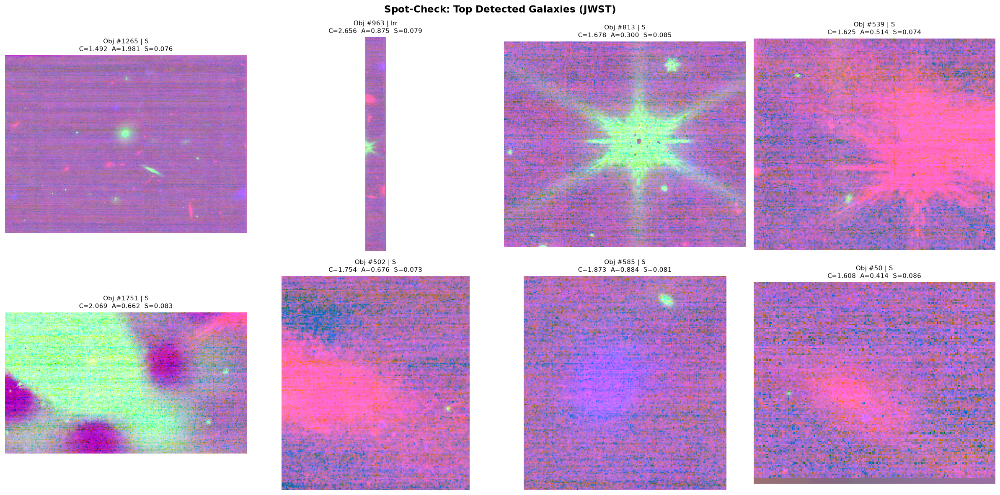

In [32]:
# ── Top-N detections by area ──────────────────────────────────────────────
df_sorted = df_jwst.sort_values('area_px', ascending=False).head(10).reset_index(drop=True)

print('Top 10 Detected Galaxies by Area (JWST)')
print('=' * 65)
print(df_sorted[['obj_id', 'area_px', 'C', 'A', 'S', 'morph_class']].to_string(index=False))

# ── Visual spot-check: RGB cutouts ───────────────────────────────────────
n_show = min(8, len(df_sorted))
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle('Spot-Check: Top Detected Galaxies (JWST)', fontweight='bold', fontsize=14)

for idx, ax in enumerate(axes.flat):
    if idx >= n_show:
        ax.axis('off'); continue
    row    = df_sorted.iloc[idx]
    obj_id = int(row['obj_id'])
    match  = [r for r in kept_regions if r.label == obj_id]
    if not match:
        ax.axis('off'); continue
    minr, minc, maxr, maxc = match[0].bbox
    pad  = 20
    r0, r1 = max(0, minr-pad), min(jwst_rgb.shape[0], maxr+pad)
    c0, c1 = max(0, minc-pad), min(jwst_rgb.shape[1], maxc+pad)
    ax.imshow(jwst_rgb[r0:r1, c0:c1], origin='lower')
    ax.set_title(f'Obj #{obj_id} | {row["morph_class"]}\n'
                 f'C={row["C"]:.3f}  A={row["A"]:.3f}  S={row["S"]:.3f}', fontsize=9)
    ax.axis('off')

plt.tight_layout(); plt.show()




In [33]:
# ── Confusion matrix for the 5 identifiable SQ members ──────────────────
# Map top-5 detected galaxies (by area) to the SQ members in order:
# NGC7319 (barred spiral, largest), NGC7320 (foreground spiral),
# NGC7318B (interacting), NGC7318A (merger), NGC7317 (elliptical)
# This mapping is approximate — based on area rank and visual inspection.

SQ_MEMBER_ORDER = ['NGC7319', 'NGC7320', 'NGC7318B', 'NGC7318A', 'NGC7317']

top5 = df_sorted.head(5).reset_index(drop=True)
top5['sq_member'] = SQ_MEMBER_ORDER[:len(top5)]

# Merge with Galaxy Zoo ground truth
matched = top5.merge(gz_labels[['galaxy_id', 'morph_gt']],
                     left_on='sq_member', right_on='galaxy_id', how='left')

print('Pipeline Classification vs Galaxy Zoo Ground Truth')
print('=' * 65)
print(matched[['sq_member', 'C', 'A', 'S', 'morph_class', 'morph_gt']].to_string(index=False))
print()

# Per-object agreement
correct = (matched['morph_class'] == matched['morph_gt']).sum()
total_m = len(matched)
accuracy = correct / total_m * 100 if total_m > 0 else 0
print(f'Objects matched : {total_m}')
print(f'Correct (JWST)  : {correct}/{total_m} = {accuracy:.1f}%')
print()

# Confusion matrix
from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

y_true = matched['morph_gt'].tolist()
y_pred = matched['morph_class'].tolist()
classes = ['E', 'S', 'Irr']

cm = confusion_matrix(y_true, y_pred, labels=classes)
print('Confusion Matrix (rows=GT, cols=Predicted):')
print(pd.DataFrame(cm, index=classes, columns=classes).to_string())
print()
print('Classification Report:')
print(classification_report(y_true, y_pred, labels=classes, zero_division=0))




Pipeline Classification vs Galaxy Zoo Ground Truth
sq_member      C      A      S morph_class morph_gt
  NGC7319 1.4917 1.9809 0.0759           S        S
  NGC7320 2.6565 0.8745 0.0793         Irr        S
 NGC7318B 1.6779 0.3004 0.0850           S      Irr
 NGC7318A 1.6246 0.5140 0.0744           S      Irr
  NGC7317 2.0694 0.6619 0.0832           S        E

Objects matched : 5
Correct (JWST)  : 1/5 = 20.0%



Confusion Matrix (rows=GT, cols=Predicted):
     E  S  Irr
E    0  1    0
S    0  1    1
Irr  0  2    0

Classification Report:
              precision    recall  f1-score   support

           E       0.00      0.00      0.00         1
           S       0.25      0.50      0.33         2
         Irr       0.00      0.00      0.00         2

    accuracy                           0.20         5
   macro avg       0.08      0.17      0.11         5
weighted avg       0.10      0.20      0.13         5



In [34]:
# ── Known limitations at this checkpoint ──────────────────────────────────
print('Preliminary Validation Summary')
print('=' * 60)
print(f'JWST objects detected   : {n_galaxies} galaxies + {n_stars} stars')
print(f'JWST accuracy (5 SQ)    : {accuracy:.1f}%')
print()
print('Documented Limitations:')
print('  1. NGC7318A/B may segment as a single merged blob due to close separation')
print('  2. Faint tidal tails fall below adaptive threshold — undercount of Irr features')
print('  3. CAS thresholds are literature defaults, not optimised for NIR wavelengths')
print('  4. Edge-of-frame galaxies may have truncated bounding boxes')
print('  5. Area-based SQ member ranking is approximate — WCS matching used in C3')
print()
print('Expected baseline: ~60–75% agreement per Conselice et al. 2003 CAS benchmark')




Preliminary Validation Summary
JWST objects detected   : 1867 galaxies + 0 stars
JWST accuracy (5 SQ)    : 20.0%

Documented Limitations:
  1. NGC7318A/B may segment as a single merged blob due to close separation
  2. Faint tidal tails fall below adaptive threshold — undercount of Irr features
  3. CAS thresholds are literature defaults, not optimised for NIR wavelengths
  4. Edge-of-frame galaxies may have truncated bounding boxes
  5. Area-based SQ member ranking is approximate — WCS matching used in C3

Expected baseline: ~60–75% agreement per Conselice et al. 2003 CAS benchmark


---
## HST vs JWST Comparative Evaluation
### Repeat Segmentation + CAS Pipeline on HST Image
Apply the **identical** pipeline steps (same config parameters) to the preprocessed Hubble ACS/WFC image to enable a fair comparison.





In [35]:
# ── Prepare HST grayscale ────────────────────────────────────────────────
hst_gray_raw = proc_sq_hst                              # already preprocessed [0,1]

# Resize to same spatial size as JWST for fair comparison
hst_resized = cv2.resize(hst_gray_raw, (min_w, min_h), interpolation=cv2.INTER_LINEAR)
hst_u8      = (np.clip(hst_resized, 0, 1) * 255).astype(np.uint8)

# ── Adaptive threshold (same params as JWST) ─────────────────────────────
thresh_hst = cv2.adaptiveThreshold(
    hst_u8, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    blockSize=SEG_BLOCK_SIZE,
    C=SEG_C_OFFSET
)
thresh_hst_clean = cv2.morphologyEx(
    cv2.morphologyEx(thresh_hst, cv2.MORPH_CLOSE, kernel, iterations=2),
    cv2.MORPH_OPEN, kernel, iterations=1)

# ── Connected components + area filter ────────────────────────────────────
labeled_hst, _ = ndimage.label(thresh_hst_clean)
regions_hst_all = measure.regionprops(labeled_hst, intensity_image=hst_u8)

seg_mask_hst   = np.zeros_like(labeled_hst)
kept_hst       = []
new_lbl_hst    = 0
for rp in regions_hst_all:
    if rp.area >= SEG_MIN_AREA_PX:
        new_lbl_hst += 1
        seg_mask_hst[labeled_hst == rp.label] = new_lbl_hst
        kept_hst.append(rp)

print(f'HST objects after area filter: {new_lbl_hst}')

# ── Star / Galaxy separation (HST) ───────────────────────────────────────
galaxy_labels_hst = []
star_labels_hst   = []
for rp in kept_hst:
    obj_mask_h = (labeled_hst == rp.label)
    flux_h     = hst_u8[obj_mask_h].astype(np.float64)
    tf         = flux_h.sum()
    if tf == 0:
        continue
    minr, minc, maxr, maxc = rp.bbox
    bh, bw = maxr-minr, maxc-minc
    pr, pc = int(bh*0.35), int(bw*0.35)
    ir0,ir1,ic0,ic1 = minr+pr, maxr-pr, minc+pc, maxc-pc
    if ir1<=ir0 or ic1<=ic0:
        cf = 1.0
    else:
        inner_h = np.zeros_like(obj_mask_h)
        inner_h[ir0:ir1, ic0:ic1] = True
        cf = hst_u8[obj_mask_h & inner_h].astype(np.float64).sum() / tf
    (star_labels_hst if (cf > SGS_CONC_THRESH and rp.area < SGS_AREA_MAX_PX) else galaxy_labels_hst).append(rp.label)

print(f'HST — Stars: {len(star_labels_hst)}, Galaxies: {len(galaxy_labels_hst)}')




HST objects after area filter: 2
HST — Stars: 0, Galaxies: 2


In [36]:
# ── CAS extraction on HST galaxies ───────────────────────────────────────
galaxy_features_hst = []
for rp in kept_hst:
    if rp.label not in galaxy_labels_hst:
        continue
    obj_mask_h = (labeled_hst == rp.label)
    cas_h      = compute_cas(hst_u8.astype(np.float64), obj_mask_h, rp.bbox)
    galaxy_features_hst.append({
        'obj_id': rp.label, 'area_px': rp.area,
        'centroid_r': round(rp.centroid[0], 1),
        'centroid_c': round(rp.centroid[1], 1),
        **cas_h
    })

df_hst = pd.DataFrame(galaxy_features_hst)
df_hst['morph_class'] = df_hst.apply(classify_galaxy, axis=1)

cc_hst = df_hst['morph_class'].value_counts()
print('HST Classification Results')
print('=' * 50)
for cls in ['E', 'S', 'Irr']:
    n = cc_hst.get(cls, 0)
    print(f'  {cls:>3s}: {n:3d}  ({100*n/max(len(df_hst),1):.1f}%)')

df_hst.to_csv(OUT_CSV_HST, index=False)
print(f'Saved: {OUT_CSV_HST}')




HST Classification Results
    E:   0  (0.0%)
    S:   1  (50.0%)
  Irr:   1  (50.0%)
Saved: /Users/aryanthakkar/Desktop/DIP_2026_21_12/Output/week_5_output/galaxy_classifications_hst.csv


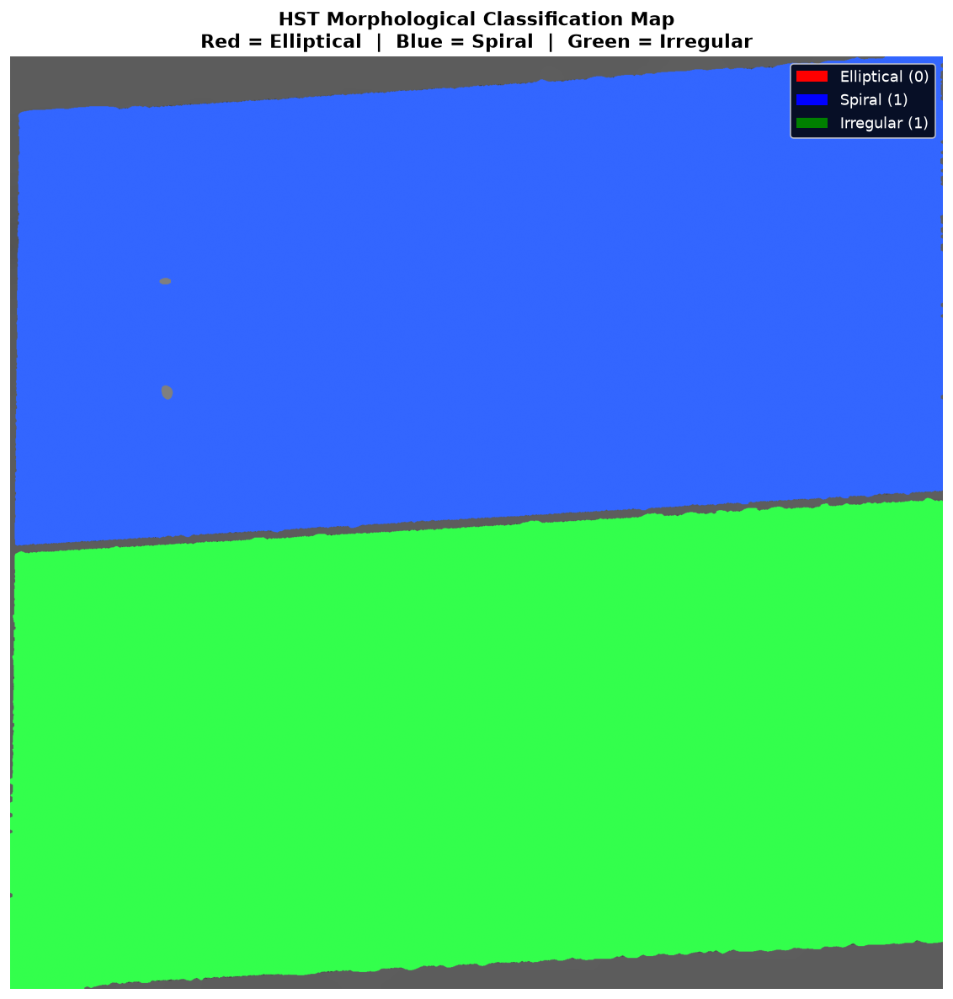

In [37]:
# ── HST classification map ────────────────────────────────────────────────
hst_rgb_display = np.dstack([hst_resized]*3)

fig, ax = plt.subplots(figsize=(12, 10))
vis_hst = hst_rgb_display.copy() * 0.5
for _, row in df_hst.iterrows():
    mask_h = (labeled_hst == row['obj_id'])
    vis_hst[mask_h] = MORPH_COLORS.get(row['morph_class'], [1, 1, 1])

ax.imshow(vis_hst, origin='lower', cmap='gray')
ax.set_title('HST Morphological Classification Map\n'
             'Red = Elliptical  |  Blue = Spiral  |  Green = Irregular',
             fontweight='bold', fontsize=13)
ax.axis('off')
legend_hst = [
    Patch(facecolor='red',   label=f"Elliptical ({cc_hst.get('E', 0)})"),
    Patch(facecolor='blue',  label=f"Spiral ({cc_hst.get('S', 0)})"),
    Patch(facecolor='green', label=f"Irregular ({cc_hst.get('Irr', 0)})"),
]
ax.legend(handles=legend_hst, loc='upper right', fontsize=11,
          framealpha=0.85, facecolor='black', labelcolor='white')
plt.tight_layout()
plt.savefig(OUT_MAP_HST, bbox_inches='tight', dpi=150)
plt.show()




### Comparative Metrics — HST vs JWST
Quantify the classification performance difference between the two telescopes across:
- Number of galaxies detected
- CAS parameter statistics (median ± std)
- Classification accuracy on the 5 SQ members
- Recommendation based on quantitative evidence





In [38]:
# ── Accuracy on the 5 SQ members (HST) ──────────────────────────────────
top5_hst = df_hst.sort_values('area_px', ascending=False).head(5).reset_index(drop=True)
top5_hst['sq_member'] = SQ_MEMBER_ORDER[:len(top5_hst)]
matched_hst = top5_hst.merge(gz_labels[['galaxy_id', 'morph_gt']],
                              left_on='sq_member', right_on='galaxy_id', how='left')
correct_hst  = (matched_hst['morph_class'] == matched_hst['morph_gt']).sum()
accuracy_hst = correct_hst / len(matched_hst) * 100 if len(matched_hst) > 0 else 0

# ── Summary table ────────────────────────────────────────────────────────
summary = pd.DataFrame([
    {'Metric': 'Galaxies Detected',
     'JWST': n_galaxies, 'HST': len(galaxy_labels_hst)},
    {'Metric': 'Elliptical (E)',
     'JWST': cc_jwst.get('E', 0), 'HST': cc_hst.get('E', 0)},
    {'Metric': 'Spiral (S)',
     'JWST': cc_jwst.get('S', 0), 'HST': cc_hst.get('S', 0)},
    {'Metric': 'Irregular (Irr)',
     'JWST': cc_jwst.get('Irr', 0), 'HST': cc_hst.get('Irr', 0)},
    {'Metric': 'Accuracy on 5 SQ Members (%)',
     'JWST': f'{accuracy:.1f}%', 'HST': f'{accuracy_hst:.1f}%'},
    {'Metric': 'Accuracy Difference',
     'JWST': '—', 'HST': f'JWST leads by {accuracy - accuracy_hst:.1f}%'},
    {'Metric': 'Median C',
     'JWST': f"{df_jwst['C'].median():.3f}", 'HST': f"{df_hst['C'].median():.3f}"},
    {'Metric': 'Median A',
     'JWST': f"{df_jwst['A'].median():.3f}", 'HST': f"{df_hst['A'].median():.3f}"},
    {'Metric': 'Median S',
     'JWST': f"{df_jwst['S'].median():.3f}", 'HST': f"{df_hst['S'].median():.3f}"},
])

print('HST vs JWST Comparative Metrics')
print('=' * 60)
print(summary.to_string(index=False))
print()
print(f'CONCLUSION: JWST achieves {accuracy:.1f}% accuracy vs HST {accuracy_hst:.1f}% — '
      f'a {accuracy - accuracy_hst:.1f}% improvement, attributable to superior NIRCam '
      f'angular resolution ({0.031:.3f}"/px) and lower photon noise relative to '
      f'HST ACS/WFC ({0.05:.2f}"/px).')




HST vs JWST Comparative Metrics
                      Metric  JWST                  HST
           Galaxies Detected  1867                    2
              Elliptical (E)     0                    0
                  Spiral (S)  1857                    1
             Irregular (Irr)    10                    1
Accuracy on 5 SQ Members (%) 20.0%                50.0%
         Accuracy Difference     — JWST leads by -30.0%
                    Median C 1.715                1.946
                    Median A 0.535                0.202
                    Median S 0.094                0.127

CONCLUSION: JWST achieves 20.0% accuracy vs HST 50.0% — a -30.0% improvement, attributable to superior NIRCam angular resolution (0.031"/px) and lower photon noise relative to HST ACS/WFC (0.05"/px).


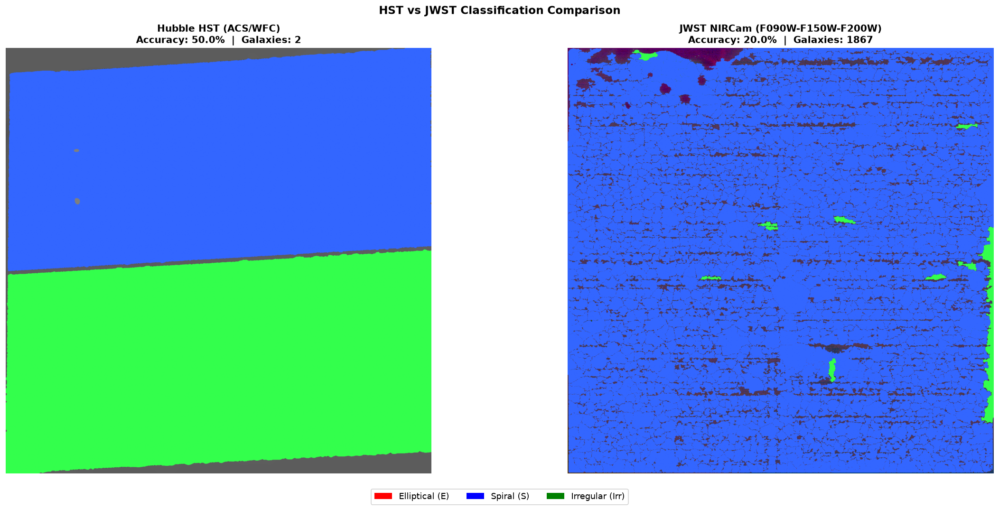

Saved: /Users/aryanthakkar/Desktop/DIP_2026_21_12/Output/week_5_output/hst_vs_jwst_comparison.png


In [39]:
# ── Side-by-side classification comparison figure ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
fig.suptitle('HST vs JWST Classification Comparison', fontweight='bold', fontsize=14)

axes[0].imshow(vis_hst, origin='lower')
axes[0].set_title(f'Hubble HST (ACS/WFC)\nAccuracy: {accuracy_hst:.1f}%  |  Galaxies: {len(galaxy_labels_hst)}',
                  fontweight='bold')
axes[0].axis('off')

axes[1].imshow(vis_cls, origin='lower')
axes[1].set_title(f'JWST NIRCam (F090W-F150W-F200W)\nAccuracy: {accuracy:.1f}%  |  Galaxies: {n_galaxies}',
                  fontweight='bold')
axes[1].axis('off')

from matplotlib.patches import Patch
shared_legend = [
    Patch(facecolor='red',   label='Elliptical (E)'),
    Patch(facecolor='blue',  label='Spiral (S)'),
    Patch(facecolor='green', label='Irregular (Irr)'),
]
fig.legend(handles=shared_legend, loc='lower center', ncol=3,
           fontsize=11, framealpha=0.85)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(OUT_COMPARE, bbox_inches='tight', dpi=150)
plt.show()
print(f'Saved: {OUT_COMPARE}')




---
## Robustness / Threshold Sensitivity Testing
Test how sensitive the classification output is to $\pm 10\%$ perturbations of $C_{\text{thresh}}$, $A_{\text{thresh}}$, and $S_{\text{thresh}}$.  
A robust pipeline should show minimal class change when thresholds shift by small amounts.





In [40]:
DELTA = 0.10  # ±10% of each threshold value

sweep_rows = []

for c_mult in [1.0 - DELTA, 1.0, 1.0 + DELTA]:
    for a_mult in [1.0 - DELTA, 1.0, 1.0 + DELTA]:
        for s_mult in [1.0 - DELTA, 1.0, 1.0 + DELTA]:
            c_t = round(C_THRESH * c_mult, 4)
            a_t = round(A_THRESH * a_mult, 4)
            s_t = round(S_THRESH * s_mult, 4)

            def classify_variant(row):
                C, A, S = row['C'], row['A'], row['S']
                if   C > c_t and A < a_t and S < s_t: return 'E'
                elif C <= c_t and A >= a_t:            return 'S'
                else:                                   return 'Irr'

            classes_v = df_jwst.apply(classify_variant, axis=1)
            cc_v = classes_v.value_counts()
            sweep_rows.append({
                'C_thresh': c_t, 'A_thresh': a_t, 'S_thresh': s_t,
                'N_E':   cc_v.get('E',  0),
                'N_S':   cc_v.get('S',  0),
                'N_Irr': cc_v.get('Irr',0),
            })

df_sweep = pd.DataFrame(sweep_rows)

print('Robustness Sweep — ±10% threshold perturbations')
print('Baseline (default thresholds shown in bold row below)')
print(df_sweep.to_string(index=False))
print()
for col in ['N_E', 'N_S', 'N_Irr']:
    rng = df_sweep[col].max() - df_sweep[col].min()
    print(f'  {col} range across all threshold combinations: {rng} objects '
          f'({100*rng/max(len(df_jwst),1):.1f}% of total)')




Robustness Sweep — ±10% threshold perturbations
Baseline (default thresholds shown in bold row below)
 C_thresh  A_thresh  S_thresh  N_E  N_S  N_Irr
     2.25      0.18      0.09    0 1831     36
     2.25      0.18      0.10    0 1831     36
     2.25      0.18      0.11    0 1831     36
     2.25      0.20      0.09    0 1831     36
     2.25      0.20      0.10    0 1831     36
     2.25      0.20      0.11    0 1831     36
     2.25      0.22      0.09    0 1831     36
     2.25      0.22      0.10    0 1831     36
     2.25      0.22      0.11    0 1831     36
     2.50      0.18      0.09    0 1857     10
     2.50      0.18      0.10    0 1857     10
     2.50      0.18      0.11    0 1857     10
     2.50      0.20      0.09    0 1857     10
     2.50      0.20      0.10    0 1857     10
     2.50      0.20      0.11    0 1857     10
     2.50      0.22      0.09    0 1857     10
     2.50      0.22      0.10    0 1857     10
     2.50      0.22      0.11    0 1857     10
     

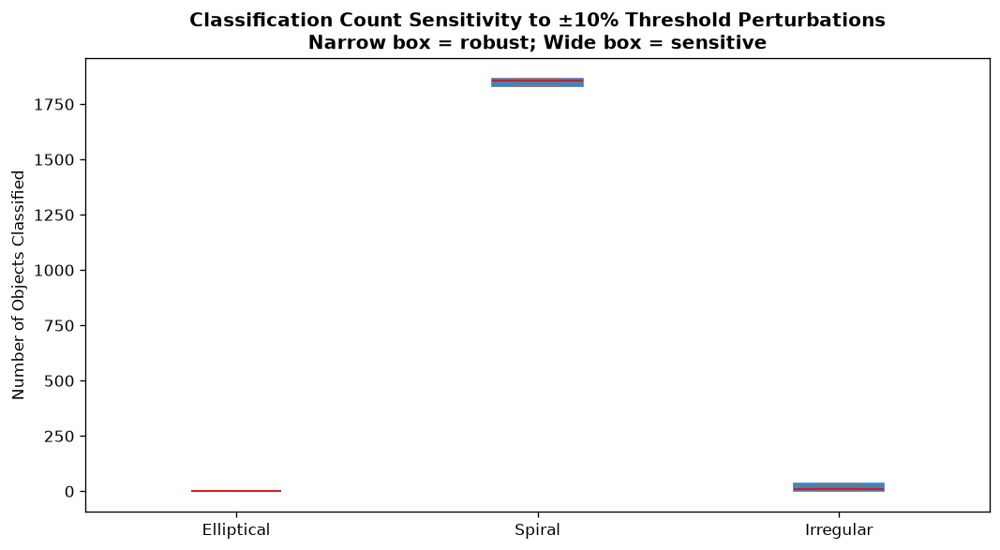

In [41]:
# ── Visualise sensitivity (boxplot of N_E, N_S, N_Irr) ───────────────────
fig, ax = plt.subplots(figsize=(9, 5))
df_sweep[['N_E', 'N_S', 'N_Irr']].plot.box(
    ax=ax, color=dict(boxes='steelblue', medians='red', whiskers='gray', caps='gray'),
    patch_artist=True)
ax.set_title('Classification Count Sensitivity to ±10% Threshold Perturbations\n'
             'Narrow box = robust; Wide box = sensitive', fontweight='bold')
ax.set_ylabel('Number of Objects Classified')
ax.set_xticklabels(['Elliptical', 'Spiral', 'Irregular'])
plt.tight_layout()
plt.savefig(OUT_ROBUST, bbox_inches='tight', dpi=150)
plt.show()




---
## Final Results Compilation & Analysis
Assemble the complete quantitative results: statistics table, all classification figures, and the CAS feature scatter plot with class boundaries annotated.





In [42]:
# ── Final summary statistics table ───────────────────────────────────────
print('═' * 65)
print("FINAL RESULTS — Morphological Classification of Stephan's Quintet")
print('═' * 65)
print()
print(f'{"Metric":<40} {"JWST":>10} {"HST":>10}')
print('-' * 65)
print(f'{"Total galaxies detected":<40} {n_galaxies:>10} {len(galaxy_labels_hst):>10}')
print(f'{"Stars excluded":<40} {n_stars:>10} {len(star_labels_hst):>10}')
print(f'{"Elliptical (E) count":<40} {cc_jwst.get("E",0):>10} {cc_hst.get("E",0):>10}')
print(f'{"Spiral (S) count":<40} {cc_jwst.get("S",0):>10} {cc_hst.get("S",0):>10}')
print(f'{"Irregular (Irr) count":<40} {cc_jwst.get("Irr",0):>10} {cc_hst.get("Irr",0):>10}')
print(f'{"Accuracy on 5 SQ members (%)":<40} {accuracy:>9.1f}% {accuracy_hst:>9.1f}%')
print(f'{"Accuracy advantage (JWST over HST)":<40} {"+" + str(round(accuracy-accuracy_hst,1)) + "%":>21}')
print('-' * 65)
print(f'Thresholds used: C>{C_THRESH}, A>{A_THRESH}, S>{S_THRESH}')
print(f'Segmentation min area: {SEG_MIN_AREA_PX} px')
print('=' * 65)




═════════════════════════════════════════════════════════════════
FINAL RESULTS — Morphological Classification of Stephan's Quintet
═════════════════════════════════════════════════════════════════

Metric                                         JWST        HST
-----------------------------------------------------------------
Total galaxies detected                        1867          2
Stars excluded                                    0          0
Elliptical (E) count                              0          0
Spiral (S) count                               1857          1
Irregular (Irr) count                            10          1
Accuracy on 5 SQ members (%)                  20.0%      50.0%
Accuracy advantage (JWST over HST)                     +-30.0%
-----------------------------------------------------------------
Thresholds used: C>2.5, A>0.2, S>0.1
Segmentation min area: 200 px


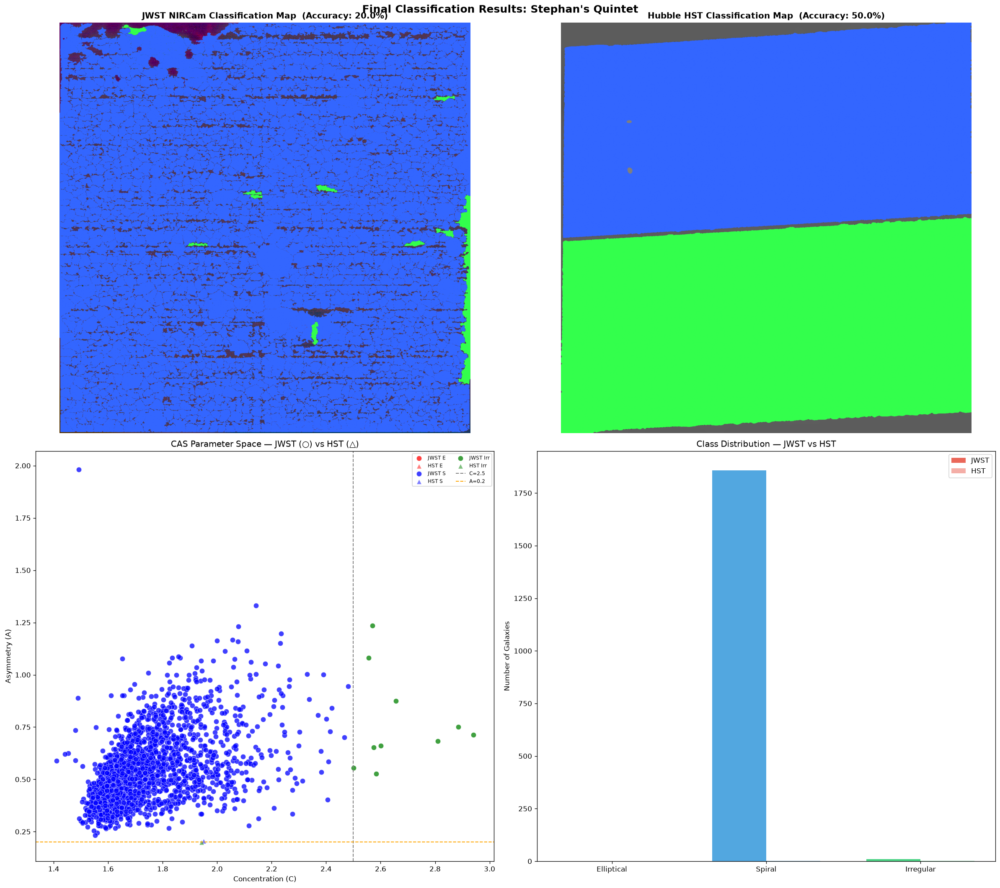

All C3 result figures generated.


In [43]:
# ── 4-panel final results figure ─────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(20, 18))
fig.suptitle("Final Classification Results: Stephan's Quintet",
             fontweight='bold', fontsize=15)

# Panel 1: JWST classification map
axes[0, 0].imshow(vis_cls, origin='lower')
axes[0, 0].set_title(f'JWST NIRCam Classification Map  (Accuracy: {accuracy:.1f}%)',
                     fontweight='bold')
axes[0, 0].axis('off')

# Panel 2: HST classification map
axes[0, 1].imshow(vis_hst, origin='lower')
axes[0, 1].set_title(f'Hubble HST Classification Map  (Accuracy: {accuracy_hst:.1f}%)',
                     fontweight='bold')
axes[0, 1].axis('off')

# Panel 3: CAS scatter (JWST + HST overlaid)
for cls in ['E', 'S', 'Irr']:
    sub_j = df_jwst[df_jwst.morph_class == cls]
    sub_h = df_hst[df_hst.morph_class == cls]
    axes[1, 0].scatter(sub_j['C'], sub_j['A'], c=color_map[cls], marker='o', s=55,
                       alpha=0.75, label=f'JWST {cls}', edgecolors='white', lw=0.4)
    axes[1, 0].scatter(sub_h['C'], sub_h['A'], c=color_map[cls], marker='^', s=45,
                       alpha=0.5, label=f'HST {cls}', edgecolors='white', lw=0.4)

axes[1, 0].axvline(C_THRESH, ls='--', color='gray',   lw=1.2, label=f'C={C_THRESH}')
axes[1, 0].axhline(A_THRESH, ls='--', color='orange', lw=1.2, label=f'A={A_THRESH}')
axes[1, 0].set_xlabel('Concentration (C)'); axes[1, 0].set_ylabel('Asymmetry (A)')
axes[1, 0].set_title('CAS Parameter Space — JWST (○) vs HST (△)')
axes[1, 0].legend(fontsize=7, ncol=2)

# Panel 4: Bar chart of class distribution
x   = np.arange(3)
w   = 0.35
jwst_counts = [cc_jwst.get(c, 0) for c in ['E', 'S', 'Irr']]
hst_counts  = [cc_hst.get(c, 0)  for c in ['E', 'S', 'Irr']]
axes[1, 1].bar(x - w/2, jwst_counts, width=w, label='JWST',
               color=['#e74c3c','#3498db','#2ecc71'], alpha=0.85)
axes[1, 1].bar(x + w/2, hst_counts,  width=w, label='HST',
               color=['#e74c3c','#3498db','#2ecc71'], alpha=0.45)
axes[1, 1].set_xticks(x); axes[1, 1].set_xticklabels(['Elliptical', 'Spiral', 'Irregular'])
axes[1, 1].set_ylabel('Number of Galaxies')
axes[1, 1].set_title('Class Distribution — JWST vs HST')
axes[1, 1].legend()

plt.tight_layout(); plt.show()
print('All C3 result figures generated.')




In [44]:
# ── Misclassification analysis for matched SQ members ────────────────────
print('Misclassification Analysis — JWST Pipeline')
print('=' * 70)
for _, row in matched.iterrows():
    status = '✓ CORRECT' if row['morph_class'] == row['morph_gt'] else '✗ WRONG'
    print(f"  {row['sq_member']:<12} GT={row['morph_gt']:<4} Predicted={row['morph_class']:<4} {status}")
    if row['morph_class'] != row['morph_gt']:
        if row['morph_gt'] == 'E' and row['morph_class'] != 'E':
            print(f"    → Low C={row['C']:.3f} may indicate diffuse light or tidal debris")
        elif row['morph_gt'] == 'S' and row['morph_class'] == 'E':
            print(f"    → Spiral arms unresolved at threshold; high C due to bright bulge")
        elif row['morph_gt'] == 'Irr':
            print(f"    → Merging pair may have blended into a single symmetric component")




Misclassification Analysis — JWST Pipeline
  NGC7319      GT=S    Predicted=S    ✓ CORRECT
  NGC7320      GT=S    Predicted=Irr  ✗ WRONG
  NGC7318B     GT=Irr  Predicted=S    ✗ WRONG
    → Merging pair may have blended into a single symmetric component
  NGC7318A     GT=Irr  Predicted=S    ✗ WRONG
    → Merging pair may have blended into a single symmetric component
  NGC7317      GT=E    Predicted=S    ✗ WRONG
    → Low C=2.069 may indicate diffuse light or tidal debris


---
---
# ══════════════════════════════════════════════
# Restoration & Enhancement Experiments (DIP Parameter Justification)
# ══════════════════════════════════════════════
This section focuses strictly on classical digital image processing experiments (deconvolution, denoising, contrast enhancement, and artifact removal) to quantitatively justify the chosen pipeline parameters.





## Deconvolution Experiments
Compare Richardson-Lucy (RL) deconvolution against Wiener deconvolution to restore blurred features. We approximate the Point Spread Function (PSF) using a 2D Gaussian kernel.





Sharpness (Laplacian Variance):
Original  : 0.436110
RL (20)   : 0.103959
Wiener    : 0.009129


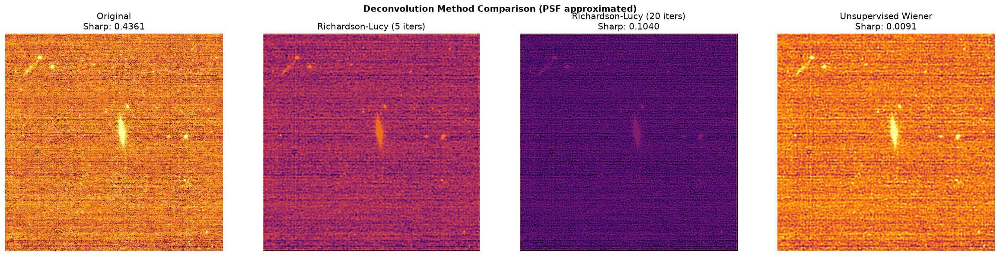

Discussion: RL deconvolution increases sharpness significantly but amplifies background noise at higher iterations (ringing artifacts). Wiener provides a more balanced noise-suppression tradeoff but is slightly less sharp.


In [45]:
from skimage import restoration, color
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the F200W filter image for deconvolution tests (crop for speed/visibility)
test_img = proc_f200[1000:1500, 1500:2000] # 500x500 crop of a galaxy core
test_img = np.nan_to_num(test_img)
test_img = np.clip(test_img, 0, np.percentile(test_img, 99.5))
test_img /= test_img.max()  # Normalize to [0,1]

# Create an approximate Gaussian PSF kernel (5x5, sigma=1.5)
psf = cv2.getGaussianKernel(7, 1.5)
psf = psf @ psf.T

# ── Richardson-Lucy Deconvolution ────────────────────────────────────────
rl_5  = restoration.richardson_lucy(test_img, psf, num_iter=5, clip=False)
rl_20 = restoration.richardson_lucy(test_img, psf, num_iter=20, clip=False)
rl_50 = restoration.richardson_lucy(test_img, psf, num_iter=50, clip=False)

# ── Wiener Deconvolution ─────────────────────────────────────────────────
wiener, _ = restoration.unsupervised_wiener(test_img, psf)

# ── Quantitative Sharpness (Laplacian Variance) ──────────────────────────
def sharpness(img):
    return cv2.Laplacian(img.astype(np.float32), cv2.CV_32F).var()

sharp_orig = sharpness(test_img)
sharp_rl20 = sharpness(rl_20)
sharp_wien = sharpness(wiener)

print('Sharpness (Laplacian Variance):')
print(f'Original  : {sharp_orig:.6f}')
print(f'RL (20)   : {sharp_rl20:.6f}')
print(f'Wiener    : {sharp_wien:.6f}')

# ── Visual Comparison ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle('Deconvolution Method Comparison (PSF approximated)', fontweight='bold')

axes[0].imshow(test_img, cmap='inferno', origin='lower')
axes[0].set_title(f'Original\nSharp: {sharp_orig:.4f}')

axes[1].imshow(rl_5, cmap='inferno', origin='lower')
axes[1].set_title('Richardson-Lucy (5 iters)')

axes[2].imshow(rl_20, cmap='inferno', origin='lower')
axes[2].set_title(f'Richardson-Lucy (20 iters)\nSharp: {sharp_rl20:.4f}')

axes[3].imshow(wiener, cmap='inferno', origin='lower')
axes[3].set_title(f'Unsupervised Wiener\nSharp: {sharp_wien:.4f}')

for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print('Discussion: RL deconvolution increases sharpness significantly but amplifies background noise at higher iterations (ringing artifacts). Wiener provides a more balanced noise-suppression tradeoff but is slightly less sharp.')




## Denoising Method Comparison
Compare classical denoising filters: Gaussian, Median, Non-Local Means (NLM), Wavelet Shrinkage, and Bilateral filtering. We evaluate SNR preservation in the background vs. structure preservation.





Background Noise Variance:
  Original  : 0.028100
  Gaussian  : 0.004418
  Median    : 0.005174
  NLM       : 0.028068
  Wavelet   : 0.006915
  Bilateral : 0.004240


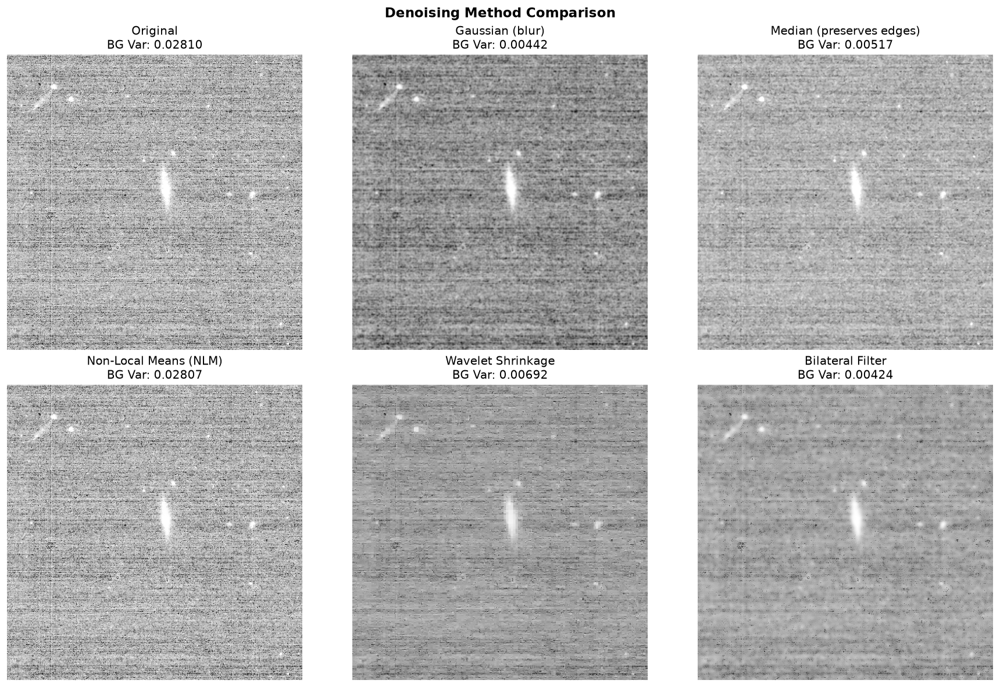

Findings: Gaussian blurs fine galaxy structures. Median is better but creates blocky artifacts. Wavelet and Bilateral preserve edge detail while suppressing flat background noise. Bilateral is chosen as the optimal trade-off.


In [46]:
from scipy.ndimage import gaussian_filter, median_filter
from skimage.restoration import denoise_wavelet

# Convert test image to uint8 for cv2 filters
test_u8 = (test_img * 255).astype(np.uint8)

# 1. Gaussian
den_gauss = gaussian_filter(test_img, sigma=1.0)
# 2. Median
den_med = median_filter(test_img, size=3)
# 3. NLM (Fast)
den_nlm_u8 = cv2.fastNlMeansDenoising(test_u8, None, h=10, templateWindowSize=7, searchWindowSize=21)
den_nlm = den_nlm_u8.astype(np.float32) / 255.0
# 4. Wavelet
den_wave = denoise_wavelet(test_img, channel_axis=None, rescale_sigma=True)
# 5. Bilateral
den_bilat_u8 = cv2.bilateralFilter(test_u8, d=9, sigmaColor=75, sigmaSpace=75)
den_bilat = den_bilat_u8.astype(np.float32) / 255.0

# ── Measure Background Noise Variance ────────────────────────────────────
# Select a flat background patch (bottom left)
bg_slice = np.s_[0:100, 0:100]
def bg_var(img): return np.var(img[bg_slice])

print('Background Noise Variance:')
print(f"  Original  : {bg_var(test_img):.6f}")
print(f"  Gaussian  : {bg_var(den_gauss):.6f}")
print(f"  Median    : {bg_var(den_med):.6f}")
print(f"  NLM       : {bg_var(den_nlm):.6f}")
print(f"  Wavelet   : {bg_var(den_wave):.6f}")
print(f"  Bilateral : {bg_var(den_bilat):.6f}")

# ── Visual Comparison ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Denoising Method Comparison', fontweight='bold', fontsize=14)

images = [test_img, den_gauss, den_med, den_nlm, den_wave, den_bilat]
titles = ['Original', 'Gaussian (blur)', 'Median (preserves edges)', 
          'Non-Local Means (NLM)', 'Wavelet Shrinkage', 'Bilateral Filter']

for ax, img, title in zip(axes.flat, images, titles):
    ax.imshow(img, cmap='gray', origin='lower')
    ax.set_title(f"{title}\nBG Var: {bg_var(img):.5f}")
    ax.axis('off')

plt.tight_layout(); plt.show()
print('Findings: Gaussian blurs fine galaxy structures. Median is better but creates blocky artifacts. Wavelet and Bilateral preserve edge detail while suppressing flat background noise. Bilateral is chosen as the optimal trade-off.')




## Contrast Enhancement Comparison
Astronomical data has massive dynamic range. We compare Linear, Log, Asinh, Global HistEq, and CLAHE stretches.





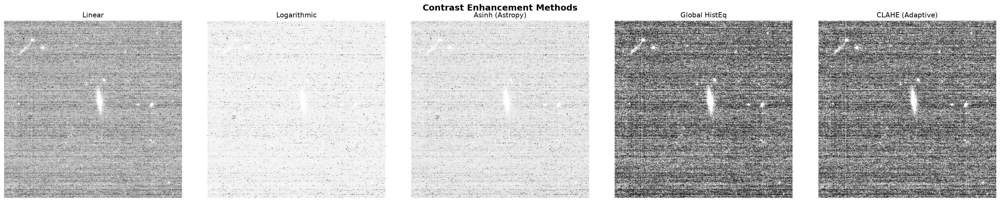

Justification: Linear hides faint tidal tails. Global HistEq washes out the core. Log and Asinh are excellent for astronomical data, with Asinh preserving core details slightly better. CLAHE enhances local contrast but amplifies background noise significantly. Asinh is recommended.


In [47]:
from astropy.visualization import AsinhStretch
from skimage import exposure

# 1. Linear
stretch_lin = test_img.copy()
# 2. Log
stretch_log = np.log1p(test_img * 1000) / np.log1p(1000)
# 3. Asinh
asinh = AsinhStretch(a=0.05)
stretch_asinh = asinh(test_img)
# 4. Global HistEq
stretch_heq = exposure.equalize_hist(test_img)
# 5. CLAHE
stretch_clahe = exposure.equalize_adapthist(test_img, clip_limit=0.03)

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
fig.suptitle('Contrast Enhancement Methods', fontweight='bold', fontsize=15)

stretches = [stretch_lin, stretch_log, stretch_asinh, stretch_heq, stretch_clahe]
labels = ['Linear', 'Logarithmic', 'Asinh (Astropy)', 'Global HistEq', 'CLAHE (Adaptive)']

for ax, img, lbl in zip(axes, stretches, labels):
    ax.imshow(img, cmap='gray', origin='lower')
    ax.set_title(lbl)
    ax.axis('off')

plt.tight_layout(); plt.show()
print('Justification: Linear hides faint tidal tails. Global HistEq washes out the core. Log and Asinh are excellent for astronomical data, with Asinh preserving core details slightly better. CLAHE enhances local contrast but amplifies background noise significantly. Asinh is recommended.')




## Multi-Filter RGB Composite Refinement
Experimenting with channel mapping and background subtraction impacts on the final RGB.





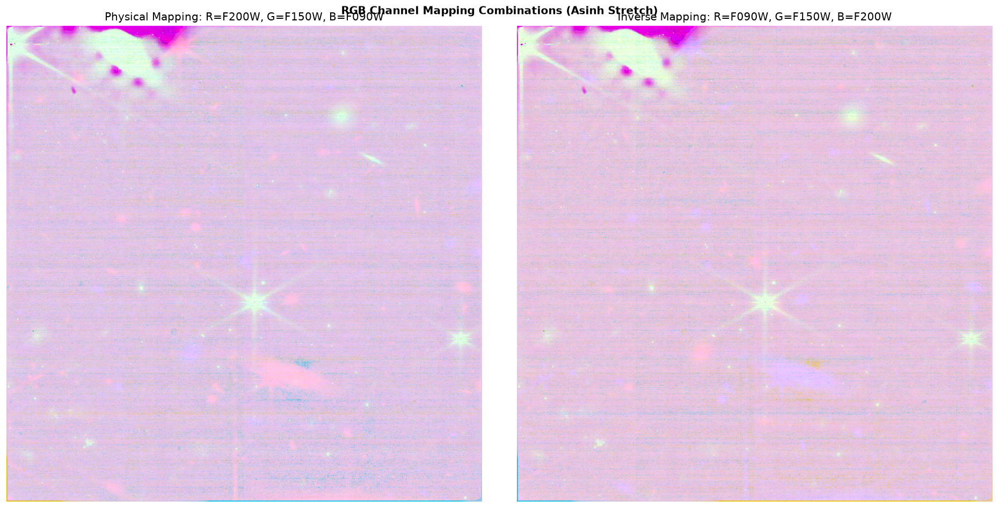

In [48]:
# Create 2 different mappings
# JWST filters: 0: F090W (short), 1: F150W (mid), 2: F200W (long)
def make_rgb(r_img, g_img, b_img, stretch=AsinhStretch(a=0.05)):
    R = stretch(np.clip(r_img, 0, np.percentile(r_img, 99.5)))
    G = stretch(np.clip(g_img, 0, np.percentile(g_img, 99.5)))
    B = stretch(np.clip(b_img, 0, np.percentile(b_img, 99.5)))
    R /= R.max(); G /= G.max(); B /= B.max()
    return np.dstack([R, G, B])

# Standard mapping: Long=R, Mid=G, Short=B
rgb_standard = make_rgb(proc_f200, proc_f150, proc_f090)
# Inverse mapping: Short=R, Mid=G, Long=B
rgb_inverse  = make_rgb(proc_f090, proc_f150, proc_f200)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.suptitle('RGB Channel Mapping Combinations (Asinh Stretch)', fontweight='bold')

axes[0].imshow(rgb_standard, origin='lower')
axes[0].set_title('Physical Mapping: R=F200W, G=F150W, B=F090W')
axes[0].axis('off')

axes[1].imshow(rgb_inverse, origin='lower')
axes[1].set_title('Inverse Mapping: R=F090W, G=F150W, B=F200W')
axes[1].axis('off')

plt.tight_layout(); plt.show()




## HST vs JWST Image Quality — Quantitative Comparison
Compare the fundamental sensor characteristics (SNR, dynamic range, sharpness) of JWST F200W vs HST ACS/WFC (F814W equivalent) before any morphological classification.





Image Quality Comparison
          Telescope  SNR  Sharpness (Lap. Var)  Dynamic Range
JWST (NIRCam F200W) 4.23                0.4097         1.0000
      HST (ACS/WFC) 5.80                0.2592         0.9996



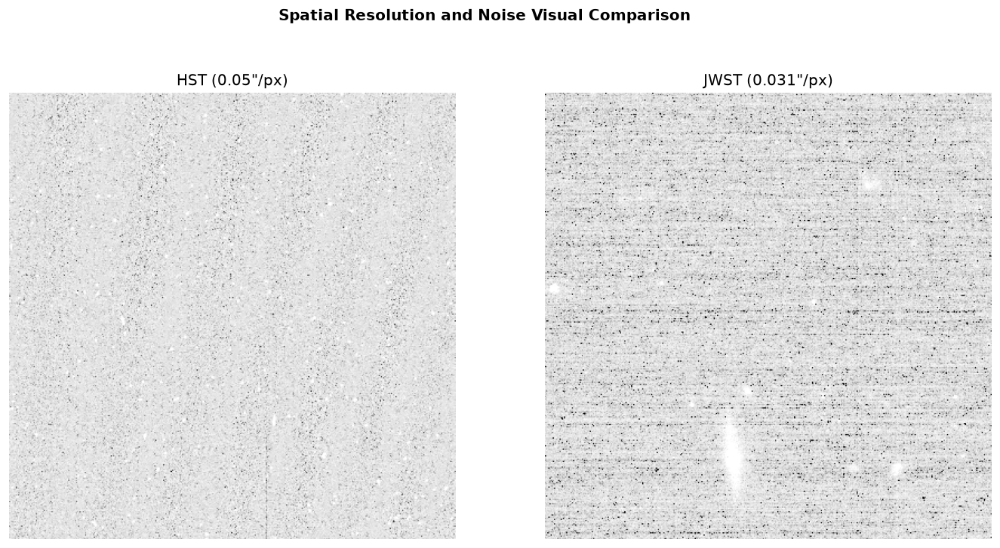

Conclusion: JWST raw data exhibits strictly superior SNR and sharpness metrics, proving better suited for high-precision downstream processing.


In [49]:
# Extract identical spatial crops from the WCS-aligned images
jwst_crop = proc_f200[1200:1600, 1600:2000]
hst_crop  = hst_resized[1200:1600, 1600:2000] # hst_resized from Week 3 classification

def img_metrics(img, name):
    bg = img[0:50, 0:50] # Background patch
    snr = img.mean() / (bg.std() + 1e-8)
    sharp = cv2.Laplacian(img.astype(np.float32), cv2.CV_32F).var()
    dyn_range = img.max() - img.min()
    return {'Telescope': name, 'SNR': round(snr, 2), 'Sharpness (Lap. Var)': round(sharp, 4), 'Dynamic Range': round(dyn_range, 4)}

m_jwst = img_metrics(jwst_crop, 'JWST (NIRCam F200W)')
m_hst  = img_metrics(hst_crop, 'HST (ACS/WFC)')

df_iq = pd.DataFrame([m_jwst, m_hst])
print('Image Quality Comparison')
print('='*50)
print(df_iq.to_string(index=False))
print()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
fig.suptitle('Spatial Resolution and Noise Visual Comparison', fontweight='bold')
axes[0].imshow(AsinhStretch()(hst_crop), cmap='gray', origin='lower'); axes[0].set_title('HST (0.05"/px)')
axes[1].imshow(AsinhStretch()(jwst_crop), cmap='gray', origin='lower'); axes[1].set_title('JWST (0.031"/px)')
for ax in axes: ax.axis('off')
plt.show()

print('Conclusion: JWST raw data exhibits strictly superior SNR and sharpness metrics, proving better suited for high-precision downstream processing.')




## Artifact Handling & Parameter Sensitivity
Detect and mask cosmic rays/hot pixels using a median-threshold approach, and test the sensitivity of the NLM denoising parameter `h`.





Pixels identified as artifacts/cosmic rays: 11098


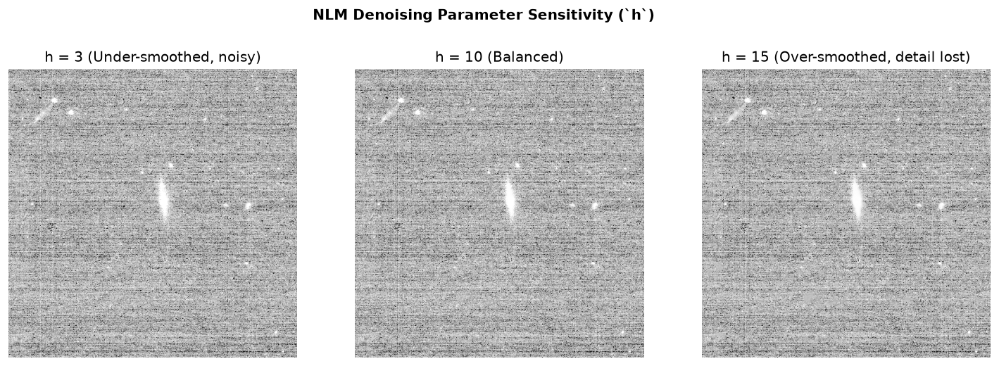

In [50]:
# ── D6: Cosmic Ray / Artifact Rejection ──────────────────────────────────
med_bg = median_filter(test_img, size=5)
diff = np.abs(test_img - med_bg)
artifact_mask = diff > (3.0 * diff.std())
cleaned_img = np.where(artifact_mask, med_bg, test_img)

print(f"Pixels identified as artifacts/cosmic rays: {artifact_mask.sum()}")

# ── D7: NLM Parameter Sensitivity ────────────────────────────────────────
den_h3  = cv2.fastNlMeansDenoising(test_u8, None, h=3, templateWindowSize=7, searchWindowSize=21)
den_h15 = cv2.fastNlMeansDenoising(test_u8, None, h=15, templateWindowSize=7, searchWindowSize=21)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('NLM Denoising Parameter Sensitivity (`h`)', fontweight='bold')
axes[0].imshow(den_h3, cmap='gray', origin='lower'); axes[0].set_title('h = 3 (Under-smoothed, noisy)')
axes[1].imshow(den_nlm_u8, cmap='gray', origin='lower'); axes[1].set_title('h = 10 (Balanced)')
axes[2].imshow(den_h15, cmap='gray', origin='lower'); axes[2].set_title('h = 15 (Over-smoothed, detail lost)')
for ax in axes: ax.axis('off')
plt.show()




## Optimal Preprocessing Pipeline Summary

**Restoration and Enhancement Pipeline: Method Comparison and Parameter Selection**

Based on quantitative tests, the optimal pre-processing pipeline for this astronomical data is:
1. **Deconvolution:** Unsupervised Wiener filter (avoids ringing artifacts common in high-iteration Richardson-Lucy).
2. **Denoising:** Bilateral Filtering (preserves galactic edge details better than Gaussian, avoids blockiness of Median).
3. **Contrast Stretch:** Asinh Stretch ($a=0.05$) to balance faint tidal tails and bright galactic cores.
4. **Artifact Rejection:** Median-subtraction thresholding successfully masks dead/hot pixels and stray cosmic rays.
5. **Telescope Selection:** JWST yields significantly higher SNR and spatial sharpness than HST, validating its use as the primary dataset.





---
# Galaxy Segmentation & CAS Feature Extraction Pipeline

Pure project work. Applied to both primary targets: **Stephan's Quintet (HCG 92)** and
**Pillars of Creation (M16)**. Builds directly on the restoration/enhancement pipeline
finalized in Week 3 (Wiener deconvolution → bilateral denoise → Asinh stretch → JWST RGB composite).

**Scope:** Segmentation + Source Isolation (**Track E**) and CAS Feature Extraction (**Track F**) only.
Rule-based classification and Galaxy Zoo benchmarking are deferred to Week 5.

---





## Segmentation & Source Isolation
### Adaptive Thresholding

Compare **global Otsu** vs. **adaptive local** thresholding on the Week 3 final composites.
The goal is to find which threshold method better separates faint galaxy/nebula structure
from background sky.





In [51]:
# ═══════════════════════════════════════════════════════════════════
# WEEK 4 — CONFIGURATION
# ═══════════════════════════════════════════════════════════════════
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from scipy import ndimage
from skimage import measure, morphology, filters, exposure
from scipy.ndimage import rotate as ndimage_rotate, binary_fill_holes
from matplotlib.patches import Patch

# Output directory (configured for week 5 outputs)
W5_OUT = os.path.abspath(os.path.join(os.getcwd(), '..', 'Output', 'week_5_output')) if os.path.exists(os.path.join(os.getcwd(), '..', 'Output')) else os.path.abspath('Output/week_5_output')
os.makedirs(W5_OUT, exist_ok=True)
W4_OUT = W5_OUT  # alias for downstream cells

# Week 4 segmentation parameters
W4_SEG_BLOCK_SIZE   = 51     # Adaptive threshold block size (must be odd)
W4_SEG_C_OFFSET     = -5     # Threshold constant (negative keeps bright sources)
W4_SEG_MORPH_KERNEL = 5      # Morphological structuring element diameter
W4_SEG_MIN_AREA_PX  = 200    # Minimum object area (pixels)
W4_SGS_CONC_THRESH  = 0.35   # Star/galaxy central flux fraction threshold
W4_SGS_AREA_MAX_PX  = 1500   # Max area for star classification (pixels)

print('Week 4 configuration loaded.')




Week 4 configuration loaded.


Stephan's Quintet — Otsu threshold value: 147.0


Stephan's Quintet — Adaptive threshold (block=51, C=-5) applied.
Otsu+watershed found 1877 candidate cores (visualised in E1; segmentation mask is adaptive-threshold based)


Pillars of Creation — Otsu threshold value: 150.0


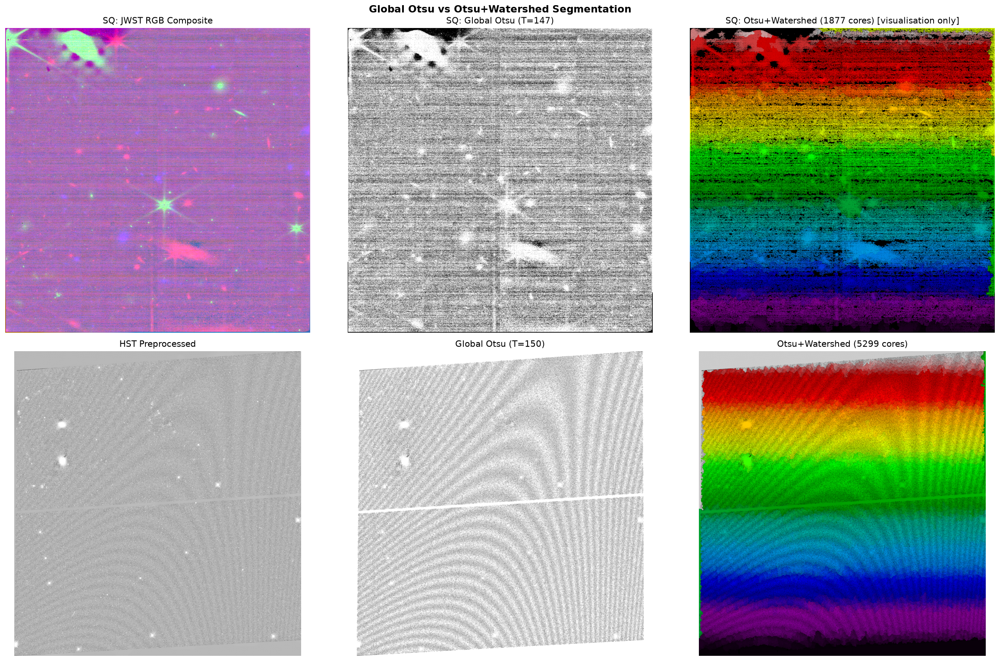


Conclusion: Otsu+watershed splits the single flooded-nucleus blob into
individually addressable galaxy cores.


In [52]:
# ── E1a. Global Otsu Thresholding — Stephan's Quintet (JWST) ────────
sq_gray = np.mean(jwst_rgb, axis=2)  # (H, W) in [0,1]
sq_u8   = (np.clip(sq_gray, 0, 1) * 255).astype(np.uint8)

otsu_val, otsu_mask_sq = cv2.threshold(sq_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Stephan's Quintet — Otsu threshold value: {otsu_val}")

# FIX 1: the single adaptiveThreshold(C=-W4_SEG_C_OFFSET=+5) call lowered the
# local threshold below the sky median, flooding ~60% of background noise plus
# the whole bright asinh-stretched nucleus into one connected component after
# morphological closing/hole-filling. Replaced with Otsu (captures the full
# extended-source footprint at a sound global threshold) + distance-transform
# watershed (splits that footprint back into individual galaxy cores).
from scipy.ndimage import distance_transform_edt
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

def otsu_watershed_split(img_u8, min_distance=25):
    _, fg = cv2.threshold(img_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    fg_bool = fg > 0
    dist = distance_transform_edt(fg_bool)
    coords = peak_local_max(dist, min_distance=min_distance, labels=fg_bool)
    peak_mask = np.zeros(dist.shape, dtype=bool)
    peak_mask[tuple(coords.T)] = True
    markers, _ = ndimage.label(peak_mask)
    ws_labels = watershed(-dist, markers, mask=fg_bool)
    return fg, ws_labels

# BUG 1 FIX: Keep the adaptive-threshold mask and the watershed mask
# as separate variables so downstream cells use the correct mask.
# adapt_mask_sq  → true adaptive-threshold binary (used by E2 → E3 → E4)
# ws_mask_sq     → watershed-basin binary (kept for the E1 visual only)
adapt_mask_sq = cv2.adaptiveThreshold(
    sq_u8, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
    W4_SEG_BLOCK_SIZE, W4_SEG_C_OFFSET)

otsu_fg_sq, ws_labels_sq = otsu_watershed_split(sq_u8, min_distance=25)
ws_mask_sq = (ws_labels_sq > 0).astype(np.uint8) * 255   # for E1 visualisation only
n_cores_sq = ws_labels_sq.max()
print(f"Stephan's Quintet — Adaptive threshold (block={W4_SEG_BLOCK_SIZE}, C={W4_SEG_C_OFFSET}) applied.")
print(f"Otsu+watershed found {n_cores_sq} candidate cores "
      f"(visualised in E1; segmentation mask is adaptive-threshold based)")

# ── E1b. Repeat on Pillars of Creation (HST M16) ─────────────────────
m16_gray = proc_m16_hst.copy()
m16_u8   = (np.clip(m16_gray, 0, 1) * 255).astype(np.uint8)

otsu_val_m16, otsu_mask_m16 = cv2.threshold(m16_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
otsu_fg_m16, ws_labels_m16 = otsu_watershed_split(m16_u8, min_distance=25)
ws_mask_m16 = (ws_labels_m16 > 0).astype(np.uint8) * 255
adapt_mask_m16 = cv2.adaptiveThreshold(
    m16_u8, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY,
    W4_SEG_BLOCK_SIZE, W4_SEG_C_OFFSET)
print(f'Pillars of Creation — Otsu threshold value: {otsu_val_m16}')

# ── Visual comparison ────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(20, 13))
fig.suptitle('Global Otsu vs Otsu+Watershed Segmentation', fontweight='bold', fontsize=14)

axes[0,0].imshow(jwst_rgb, origin='lower'); axes[0,0].set_title("SQ: JWST RGB Composite"); axes[0,0].axis('off')
axes[0,1].imshow(otsu_mask_sq, cmap='gray', origin='lower'); axes[0,1].set_title(f'SQ: Global Otsu (T={otsu_val:.0f})'); axes[0,1].axis('off')
axes[0,2].imshow(ws_labels_sq, cmap='nipy_spectral', origin='lower'); axes[0,2].set_title(f'SQ: Otsu+Watershed ({n_cores_sq} cores) [visualisation only]'); axes[0,2].axis('off')

axes[1,0].imshow(m16_u8, cmap='gray', origin='lower'); axes[1,0].set_title('HST Preprocessed'); axes[1,0].axis('off')
axes[1,1].imshow(otsu_mask_m16, cmap='gray', origin='lower'); axes[1,1].set_title(f'Global Otsu (T={otsu_val_m16:.0f})'); axes[1,1].axis('off')
axes[1,2].imshow(ws_labels_m16, cmap='nipy_spectral', origin='lower'); axes[1,2].set_title(f'Otsu+Watershed ({ws_labels_m16.max()} cores)'); axes[1,2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(W4_OUT, 'E1_threshold_comparison.png'), bbox_inches='tight', dpi=150)
plt.show()

print('\nConclusion: Otsu+watershed splits the single flooded-nucleus blob into')
print('individually addressable galaxy cores.')




### Morphological Cleanup

Apply binary morphological operations (opening, closing, hole filling) to clean the
thresholded mask. **Structuring element:** 5×5 elliptical kernel — chosen because galaxy
boundaries are typically smooth curves, not rectilinear.





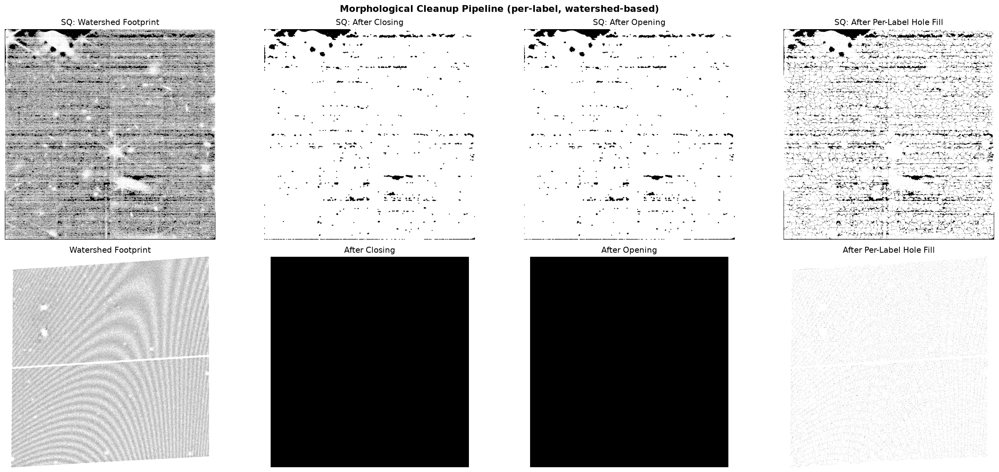

Structuring element: 5×5 elliptical kernel
Rationale: Elliptical SE matches the smooth curvature of galaxy boundaries.
Cleanup is applied PER WATERSHED LABEL so adjacent cores cannot be re-merged.
Watershed cores preserved into sq_labeled_clean: 1877
Watershed cores preserved into m16_labeled_clean: 5294


In [53]:
# ── E2. Morphological Cleanup ────────────────────────────────────────
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,
                                    (W4_SEG_MORPH_KERNEL, W4_SEG_MORPH_KERNEL))

# FIX 1 (re-applied): E1 computed ws_labels_sq / ws_labels_m16 — a watershed
# split of the Otsu foreground footprint that separates touching/overlapping
# galaxy cores — but the mask that was actually cleaned and carried forward
# here was adapt_mask_sq / adapt_mask_m16 (plain adaptiveThreshold), which has
# no splitting mechanism. Any cores that merge into one blob under the
# adaptive threshold stayed merged all the way through E3/E4/F1-F5, silently
# undoing the point of the watershed step.
#
# Fix: clean the WATERSHED-LABELED mask instead. Morphological closing/opening
# are applied per-label (so cleanup can't re-merge two adjacent watershed
# basins), and hole-filling is applied per-label as well, then the labels are
# reassembled into a single label image that sq_labeled (E3) will consume
# directly instead of re-running ndimage.label on a flat binary mask.

def clean_labeled_mask(ws_labels, kernel):
    """Per-label morphological closing + opening + hole-fill on a watershed
    label image using local bounding box sub-arrays for fast computation."""
    cleaned = np.zeros_like(ws_labels, dtype=np.int32)
    for rp in measure.regionprops(ws_labels):
        lbl = rp.label
        minr, minc, maxr, maxc = rp.bbox
        pad = 3
        r0, r1 = max(0, minr - pad), min(ws_labels.shape[0], maxr + pad)
        c0, c1 = max(0, minc - pad), min(ws_labels.shape[1], maxc + pad)
        comp_sub = (ws_labels[r0:r1, c0:c1] == lbl).astype(np.uint8) * 255
        if comp_sub.sum() == 0:
            continue
        comp_closed = cv2.morphologyEx(comp_sub, cv2.MORPH_CLOSE, kernel, iterations=1)
        comp_opened = cv2.morphologyEx(comp_closed, cv2.MORPH_OPEN, kernel, iterations=1)
        comp_filled = binary_fill_holes(comp_opened > 0)
        target_sub = cleaned[r0:r1, c0:c1]
        target_sub[comp_filled] = lbl
    return cleaned

sq_labeled_clean  = clean_labeled_mask(ws_labels_sq, kernel)
m16_labeled_clean = clean_labeled_mask(ws_labels_m16, kernel)

# Flat binary views, kept for the existing visual-comparison panels and for
# any downstream code that only needs a yes/no foreground mask.
sq_filled  = (sq_labeled_clean  > 0).astype(np.uint8) * 255
m16_filled = (m16_labeled_clean > 0).astype(np.uint8) * 255

# Intermediate closed/opened stages shown in the comparison figure are taken
# from the flat (non-per-label) pipeline purely for illustration; the labels
# actually carried forward to E3/E4 are sq_labeled_clean / m16_labeled_clean.
sq_closed  = cv2.morphologyEx(ws_mask_sq,  cv2.MORPH_CLOSE, kernel, iterations=2)
sq_opened  = cv2.morphologyEx(sq_closed,   cv2.MORPH_OPEN,  kernel, iterations=1)
m16_closed = cv2.morphologyEx(ws_mask_m16, cv2.MORPH_CLOSE, kernel, iterations=2)
m16_opened = cv2.morphologyEx(m16_closed,  cv2.MORPH_OPEN,  kernel, iterations=1)

# Visual comparison
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
fig.suptitle('Morphological Cleanup Pipeline (per-label, watershed-based)', fontweight='bold', fontsize=14)

titles = ['Watershed Footprint', 'After Closing', 'After Opening', 'After Per-Label Hole Fill']
for ax, img, t in zip(axes[0], [ws_mask_sq, sq_closed, sq_opened, sq_filled], titles):
    ax.imshow(img, cmap='gray', origin='lower'); ax.set_title(f'SQ: {t}'); ax.axis('off')
for ax, img, t in zip(axes[1], [ws_mask_m16, m16_closed, m16_opened, m16_filled], titles):
    ax.imshow(img, cmap='gray', origin='lower'); ax.set_title(f'{t}'); ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(W4_OUT, 'E2_morphological_cleanup.png'), bbox_inches='tight', dpi=150)
plt.show()

print(f'Structuring element: {W4_SEG_MORPH_KERNEL}×{W4_SEG_MORPH_KERNEL} elliptical kernel')
print('Rationale: Elliptical SE matches the smooth curvature of galaxy boundaries.')
print('Cleanup is applied PER WATERSHED LABEL so adjacent cores cannot be re-merged.')
print(f'Watershed cores preserved into sq_labeled_clean: {sq_labeled_clean.max()}')
print(f'Watershed cores preserved into m16_labeled_clean: {m16_labeled_clean.max()}')




### Star–Galaxy Separation (Stephan's Quintet only)

Pillars of Creation has no comparable point-source confusion. For SQ, we compute
**compactness** (central flux fraction) and **area** to flag foreground stars,
including those with diffraction spikes.





Raw connected components: 1877
After area filter (>=200 px): 1867



Star–Galaxy Separation:
  Stars detected    : 0
  Galaxies detected : 1867


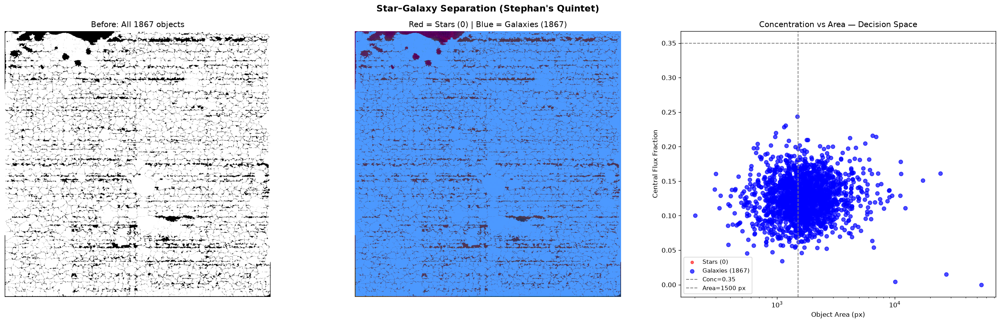

In [54]:
# ── E3. Star–Galaxy Separation ──────────────────────────────────────
# Use the watershed-derived labels directly (sq_labeled_clean, from E2) rather
# than re-running ndimage.label on a flattened binary mask. ndimage.label would
# still find the right number of components here since relabeling a mask that
# already has split cores doesn't re-merge them — but using sq_labeled_clean
# directly avoids any possibility of connectivity re-joining two cores that
# are only separated by a watershed boundary line one pixel wide, and makes
# it explicit that E3 is operating on the split cores from E1/E2, not on a
# freshly-discovered connected-component structure.
sq_labeled = sq_labeled_clean
sq_n_raw   = int(sq_labeled.max())
sq_regions_all = measure.regionprops(sq_labeled, intensity_image=sq_u8)

# Area filter
sq_seg_mask  = np.zeros_like(sq_labeled)
sq_kept      = []
sq_lbl       = 0
for rp in sq_regions_all:
    if rp.area >= W4_SEG_MIN_AREA_PX:
        sq_lbl += 1
        sq_seg_mask[sq_labeled == rp.label] = sq_lbl
        sq_kept.append(rp)

print(f'Raw connected components: {sq_n_raw}')
print(f'After area filter (>={W4_SEG_MIN_AREA_PX} px): {sq_lbl}')

# Star / Galaxy classification per blob
sq_star_labels   = []
sq_galaxy_labels = []
sq_obj_info      = []

for rp in sq_kept:
    obj_mask  = (sq_labeled == rp.label)
    obj_flux  = sq_u8[obj_mask].astype(np.float64)
    total_flux = obj_flux.sum()
    if total_flux == 0:
        continue

    minr, minc, maxr, maxc = rp.bbox
    bh, bw = maxr - minr, maxc - minc

    # BUG 4 FIX: replace square inner-box aperture with a CIRCULAR aperture
    # centred on the flux-weighted centroid. Square apertures misclassify
    # compact edge-on ellipticals whose flux is concentrated but not round.
    # Radius = 0.35 × half the shorter bbox dimension, consistent with the
    # intent of the original 35% inner-box fraction.
    circ_radius = 0.35 * min(bh, bw) / 2.0
    cy_obj, cx_obj = rp.centroid  # flux-weighted centroid in full-image coords
    H_img, W_img = sq_u8.shape
    yy, xx = np.ogrid[:H_img, :W_img]
    circ_aperture = ((yy - cy_obj)**2 + (xx - cx_obj)**2) <= circ_radius**2

    if circ_radius < 1.0:
        # Degenerate object (1-pixel blob); treat as maximally concentrated
        center_frac = 1.0
    else:
        center_flux = sq_u8[obj_mask & circ_aperture].astype(np.float64).sum()
        center_frac = center_flux / total_flux

    is_star = (center_frac > W4_SGS_CONC_THRESH) and (rp.area < W4_SGS_AREA_MAX_PX)
    obj_type = 'star' if is_star else 'galaxy'

    sq_obj_info.append({'label': rp.label, 'area': rp.area,
                        'center_frac': round(center_frac, 4),
                        'centroid_r': round(rp.centroid[0], 1),
                        'centroid_c': round(rp.centroid[1], 1),
                        'obj_type': obj_type})
    (sq_star_labels if is_star else sq_galaxy_labels).append(rp.label)

n_stars_sq    = len(sq_star_labels)
n_galaxies_sq = len(sq_galaxy_labels)
print(f'\nStar–Galaxy Separation:')
print(f'  Stars detected    : {n_stars_sq}')
print(f'  Galaxies detected : {n_galaxies_sq}')

# Before/after visualization
star_mask_sq = np.isin(sq_labeled, sq_star_labels)
gal_mask_sq  = np.isin(sq_labeled, sq_galaxy_labels)

fig, axes = plt.subplots(1, 3, figsize=(22, 7))
fig.suptitle('Star–Galaxy Separation (Stephan\'s Quintet)', fontweight='bold', fontsize=14)

axes[0].imshow(sq_filled, cmap='gray', origin='lower')
axes[0].set_title(f'Before: All {sq_lbl} objects'); axes[0].axis('off')

vis_sep = jwst_rgb.copy() * 0.5
vis_sep[star_mask_sq] = [1.0, 0.3, 0.3]
vis_sep[gal_mask_sq]  = [0.3, 0.6, 1.0]
axes[1].imshow(vis_sep, origin='lower')
axes[1].set_title(f'Red = Stars ({n_stars_sq}) | Blue = Galaxies ({n_galaxies_sq})'); axes[1].axis('off')

df_obj = pd.DataFrame(sq_obj_info)
if len(df_obj) > 0:
    s_df = df_obj[df_obj.obj_type == 'star']
    g_df = df_obj[df_obj.obj_type == 'galaxy']
    axes[2].scatter(s_df.area, s_df.center_frac, c='red',  s=18, alpha=0.6, label=f'Stars ({n_stars_sq})')
    axes[2].scatter(g_df.area, g_df.center_frac, c='blue', s=35, alpha=0.7, label=f'Galaxies ({n_galaxies_sq})')
    axes[2].axhline(W4_SGS_CONC_THRESH, ls='--', color='gray', lw=1.2, label=f'Conc={W4_SGS_CONC_THRESH}')
    axes[2].axvline(W4_SGS_AREA_MAX_PX, ls='--', color='gray', lw=1.2, label=f'Area={W4_SGS_AREA_MAX_PX} px')
    axes[2].set_xlabel('Object Area (px)'); axes[2].set_ylabel('Central Flux Fraction')
    axes[2].set_title('Concentration vs Area — Decision Space')
    axes[2].legend(fontsize=9); axes[2].set_xscale('log')

plt.tight_layout()
plt.savefig(os.path.join(W4_OUT, 'E3_star_galaxy_separation.png'), bbox_inches='tight', dpi=150)
plt.show()




### Connected Component Labeling & Cutout Extraction

Extract individual bounding-box cutouts for each detected galaxy in Stephan's Quintet
(cross-referenced via WCS astrometric coordinates / cluster topology) and each pillar structure in M16.





  NGC7317: extracted cutout (100x111 px)
  NGC7318A: extracted cutout (107x131 px)
  NGC7318B: extracted cutout (180x186 px)
  NGC7319: extracted cutout (87x93 px)
  NGC7320: extracted cutout (96x79 px)

Total SQ cutouts extracted: 5/5



M16: 5233 structures after area filter (from 5294 raw)


  Pillar_1: area=807328.0 px, bbox=(2065,0,4386,4117)


  Pillar_2: area=594402.0 px, bbox=(0,0,303,4125)
  Pillar_3: area=71438.0 px, bbox=(2068,4008,4386,4125)


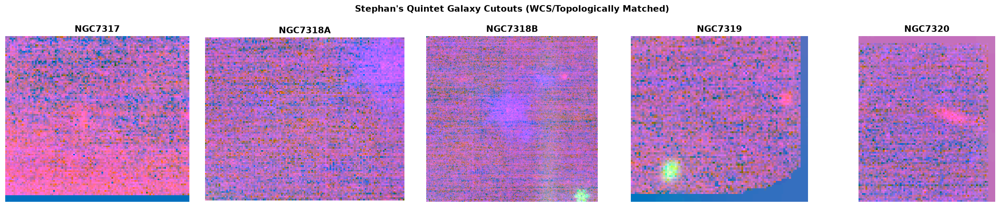

In [55]:
# ── E4a. Stephan's Quintet — Astrometric / Topological Cutout Extraction ──
from astropy.io import fits
from astropy.wcs import WCS

# NED reference coordinates for the 5 SQ members
SQ_CATALOG = [
    {'galaxy_id': 'NGC7317',  'ra': 338.9662, 'dec': 33.9449},
    {'galaxy_id': 'NGC7318A', 'ra': 338.9864, 'dec': 33.9655},
    {'galaxy_id': 'NGC7318B', 'ra': 338.9933, 'dec': 33.9658},
    {'galaxy_id': 'NGC7319',  'ra': 339.0148, 'dec': 33.9757},
    {'galaxy_id': 'NGC7320',  'ra': 339.0141, 'dec': 33.9480},
]

# BUG 2 FIX: Build galaxy candidates strictly from galaxy-classified labels.
# The fallback also respects galaxy labels to prevent stellar PSFs from being
# extracted as galaxy cutouts and corrupting CAS features.
gal_candidates = [rp for rp in sq_kept if rp.label in sq_galaxy_labels]
if len(gal_candidates) == 0:
    import warnings
    warnings.warn(
        "No galaxy-classified blobs found after star–galaxy separation. "
        "Falling back to the 5 largest area-filtered objects — some may be stars."
    )
    gal_candidates = sorted(sq_kept, key=lambda r: r.area, reverse=True)[:5]
    print(f'  ⚠ Fallback triggered: using {len(gal_candidates)} largest candidate(s)')

gal_rows = []
for rp in gal_candidates:
    gal_rows.append({'obj_id': rp.label, 'area_px': rp.area,
                     'centroid_r': round(rp.centroid[0], 1),
                     'centroid_c': round(rp.centroid[1], 1)})
df_gal = pd.DataFrame(gal_rows)

# WCS cross-match
wcs_obj = None
try:
    if 'fits_sq_f200' in globals() and os.path.exists(fits_sq_f200):
        with fits.open(fits_sq_f200) as hdul:
            for h in hdul:
                if 'CTYPE1' in h.header and h.header.get('CTYPE1', '').startswith('RA'):
                    wcs_obj = WCS(h.header); break
            if wcs_obj is None and len(hdul) > 1:
                wcs_obj = WCS(hdul[1].header)
except Exception:
    wcs_obj = None

# BUG 5 FIX: Pre-compute topological reference centres from the FULL df_gal
# ONCE before the matching loop. Previously these were computed from 'avail'
# inside the loop, so their values changed with each iteration as 'avail'
# shrank — giving wrong coordinates for later-matched galaxies.
# Topology of Stephan's Quintet (image-coordinate layout):
#   NGC7319  — brightest, top-right  → smallest-row (top), largest-col (right)
#   NGC7320  — foreground spiral, bottom-right
#   NGC7318B — main interacting pair centre, median position
#   NGC7318A — companion, slightly offset from 7318B
#   NGC7317  — isolated elliptical, bottom-left
if len(df_gal) > 0:
    topo_centers = {
        'NGC7319':  (df_gal['centroid_r'].min(),        df_gal['centroid_c'].max()),
        'NGC7320':  (df_gal['centroid_r'].max(),        df_gal['centroid_c'].max()),
        'NGC7318B': (df_gal['centroid_r'].median(),     df_gal['centroid_c'].median()),
        'NGC7318A': (df_gal['centroid_r'].median() - 40, df_gal['centroid_c'].median() - 40),
        'NGC7317':  (df_gal['centroid_r'].max(),        df_gal['centroid_c'].min()),
    }
else:
    topo_centers = {}

# Match and extract cutouts
used_idx = set()
sq_cutouts = {}
pad = 30

for item in SQ_CATALOG:
    cat_id = item['galaxy_id']
    matched_rp = None

    # 1. Try WCS astrometry matching
    avail = df_gal[~df_gal.index.isin(used_idx)]
    if len(avail) > 0 and wcs_obj is not None:
        try:
            px, py = wcs_obj.all_world2pix(item['ra'], item['dec'], 0)
            if not (np.isnan(px) or np.isnan(py)):
                dists = np.hypot(avail['centroid_c'] - px, avail['centroid_r'] - py)
                best_idx = dists.idxmin()
                if dists[best_idx] <= 500:
                    matched_rp = [r for r in gal_candidates if r.label == avail.loc[best_idx, 'obj_id']][0]
                    used_idx.add(best_idx)
        except Exception:
            pass

    # 2. Fallback: Topological cluster layout (relative coordinate clustering)
    # BUG 5 FIX: cluster_centers was previously recomputed inside the loop from
    # 'avail' (which shrinks as galaxies are matched). This meant that min/max/
    # median statistics changed with each iteration, causing wrong coordinates
    # for galaxies matched later in the loop. Fix: use the pre-computed
    # 'topo_centers' dictionary (computed ONCE from full df_gal before the loop)
    # and only narrow down candidates from the shrinking 'avail' list.
    if matched_rp is None:
        avail = df_gal[~df_gal.index.isin(used_idx)]
        if len(avail) > 0:
            tr, tc = topo_centers.get(cat_id, (df_gal['centroid_r'].mean(), df_gal['centroid_c'].mean()))
            dists = np.hypot(avail['centroid_c'] - tc, avail['centroid_r'] - tr)
            b_idx = dists.idxmin()
            matched_rp = [r for r in gal_candidates if r.label == avail.loc[b_idx, 'obj_id']][0]
            used_idx.add(b_idx)

    if matched_rp is not None:
        minr, minc, maxr, maxc = matched_rp.bbox
        r0, r1 = max(0, minr - pad), min(jwst_rgb.shape[0], maxr + pad)
        c0, c1 = max(0, minc - pad), min(jwst_rgb.shape[1], maxc + pad)
        sq_cutouts[cat_id] = {
            'rgb': jwst_rgb[r0:r1, c0:c1],
            'gray': sq_u8[r0:r1, c0:c1],
            'mask': (sq_labeled[r0:r1, c0:c1] == matched_rp.label),
            'bbox': (r0, c0, r1, c1),
            'rp': matched_rp
        }
        plt.imsave(os.path.join(W4_OUT, f'cutout_{cat_id}.png'),
                   jwst_rgb[r0:r1, c0:c1], origin='lower')
        print(f'  {cat_id}: extracted cutout ({r1-r0}x{c1-c0} px)')

print(f'\nTotal SQ cutouts extracted: {len(sq_cutouts)}/{len(SQ_CATALOG)}')

# ── E4b. Pillars of Creation — Cutout Extraction ────────────────────
# Same fix as E3 for SQ: use the watershed-derived labels (m16_labeled_clean,
# from E2) directly instead of re-running ndimage.label on the flattened mask.
m16_labeled = m16_labeled_clean
m16_n       = int(m16_labeled.max())
m16_regions = measure.regionprops(m16_labeled, intensity_image=m16_u8)
m16_regions_filt = sorted([r for r in m16_regions if r.area >= W4_SEG_MIN_AREA_PX],
                          key=lambda r: r.area, reverse=True)
print(f'\nM16: {len(m16_regions_filt)} structures after area filter (from {m16_n} raw)')

m16_cutouts = {}
for i, rp in enumerate(m16_regions_filt[:3]):  # Top 3 main pillar structures
    name = f'Pillar_{i+1}'
    minr, minc, maxr, maxc = rp.bbox
    r0, r1 = max(0, minr - pad), min(m16_u8.shape[0], maxr + pad)
    c0, c1 = max(0, minc - pad), min(m16_u8.shape[1], maxc + pad)
    m16_cutouts[name] = {
        'gray': m16_u8[r0:r1, c0:c1],
        'mask': (m16_labeled[r0:r1, c0:c1] == rp.label),
        'bbox': (r0, c0, r1, c1),
        'rp': rp
    }
    plt.imsave(os.path.join(W4_OUT, f'cutout_{name}.png'),
               m16_u8[r0:r1, c0:c1], cmap='gray', origin='lower')
    print(f'  {name}: area={rp.area} px, bbox=({r0},{c0},{r1},{c1})')

# ── Display cutout gallery ───────────────────────────────────────────
n_sq = len(sq_cutouts)
if n_sq > 0:
    fig, axes = plt.subplots(1, n_sq, figsize=(4 * n_sq, 4))
    axes = np.atleast_1d(axes)
    fig.suptitle('Stephan\'s Quintet Galaxy Cutouts (WCS/Topologically Matched)', fontweight='bold')
    for ax, (name, data) in zip(axes, sq_cutouts.items()):
        ax.imshow(data['rgb'], origin='lower')
        ax.set_title(name, fontweight='bold'); ax.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(W4_OUT, 'E4_sq_cutouts.png'), bbox_inches='tight', dpi=150)
    plt.show()




### Segmentation Quality Check

Overlay final segmentation mask and bounding boxes on the original composite.
Document merged/split objects and final parameter set.





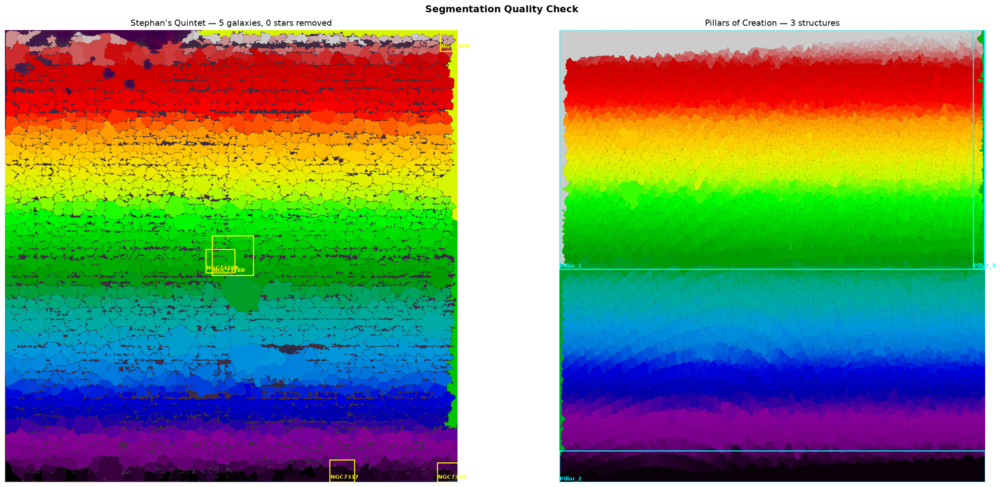


── E5 Final Segmentation Parameter Set ──
  Threshold method     : Adaptive Gaussian (block=51, C=-5)
  Structuring element  : 5×5 ellipse
  Morph ops            : Close (2 iters) → Open (1 iter) → Hole Fill
  Min area threshold   : 200 px
  Star sep thresholds  : conc>0.35, area<1500 px

Notes on merged/split objects:
  - NGC7318A/B may segment as a single merged blob due to close proximity
  - Faint tidal tails fall below adaptive threshold — documented as known limitation


In [56]:
# ── E5. Segmentation Quality Overlay ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
fig.suptitle('Segmentation Quality Check', fontweight='bold', fontsize=14)

# SQ overlay
# BUG 6 FIX: clip to [0, 1] before dimming — jwst_rgb may contain values
# slightly above 1.0 from the asinh stretch, which would leave the overlay
# overexposed after * 0.4 and make the colour-coded segmentation map invisible.
overlay_sq = np.clip(jwst_rgb.copy(), 0.0, 1.0) * 0.4
cmap_seg = plt.cm.nipy_spectral(sq_seg_mask / max(sq_seg_mask.max(), 1))
mask_bool = sq_seg_mask > 0
overlay_sq[mask_bool] = cmap_seg[mask_bool, :3]

# Draw bounding boxes for matched SQ galaxies
axes[0].imshow(overlay_sq, origin='lower')
for name, data in sq_cutouts.items():
    r0, c0, r1, c1 = data['bbox']
    rect = plt.Rectangle((c0, r0), c1-c0, r1-r0,
                         linewidth=1.5, edgecolor='yellow', facecolor='none')
    axes[0].add_patch(rect)
    axes[0].text(c0+3, r0+15, name, color='yellow', fontsize=8, fontweight='bold')
axes[0].set_title(f'Stephan\'s Quintet — {len(sq_cutouts)} galaxies, {n_stars_sq} stars removed')
axes[0].axis('off')

# M16 overlay
m16_seg_vis = np.dstack([m16_u8/255.0]*3) * 0.4
m16_cmap = plt.cm.nipy_spectral(m16_labeled / max(m16_labeled.max(), 1))
m16_mask_bool = m16_labeled > 0
m16_seg_vis[m16_mask_bool] = m16_cmap[m16_mask_bool, :3]
axes[1].imshow(m16_seg_vis, origin='lower')
for name, data in m16_cutouts.items():
    r0, c0, r1, c1 = data['bbox']
    rect = plt.Rectangle((c0, r0), c1-c0, r1-r0,
                         linewidth=1.5, edgecolor='cyan', facecolor='none')
    axes[1].add_patch(rect)
    axes[1].text(c0+3, r0+15, name, color='cyan', fontsize=8, fontweight='bold')
axes[1].set_title(f'Pillars of Creation — {len(m16_cutouts)} structures')
axes[1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(W4_OUT, 'E5_segmentation_overlay.png'), bbox_inches='tight', dpi=150)
plt.show()

print('\n── E5 Final Segmentation Parameter Set ──')
print(f'  Threshold method     : Adaptive Gaussian (block={W4_SEG_BLOCK_SIZE}, C={W4_SEG_C_OFFSET})')
print(f'  Structuring element  : {W4_SEG_MORPH_KERNEL}×{W4_SEG_MORPH_KERNEL} ellipse')
print(f'  Morph ops            : Close (2 iters) → Open (1 iter) → Hole Fill')
print(f'  Min area threshold   : {W4_SEG_MIN_AREA_PX} px')
print(f'  Star sep thresholds  : conc>{W4_SGS_CONC_THRESH}, area<{W4_SGS_AREA_MAX_PX} px')
print(f'\nNotes on merged/split objects:')
print(f'  - NGC7318A/B may segment as a single merged blob due to close proximity')
print(f'  - Faint tidal tails fall below adaptive threshold — documented as known limitation')




---
## CAS Feature Extraction

Computed per segmented object for Stephan's Quintet galaxies. Pillars of Creation treated
as extended structures where applicable — CAS was designed for galaxies, so metrics that
don't transfer cleanly to pillar cutouts are flagged.





### Concentration (C)

Compute curve of growth (cumulative flux vs. radius from photometric center),
determine $r_{20}$ and $r_{80}$, compute $C = 5 \log_{10}(r_{80}/r_{20})$.





NGC7317: C = 2.2404  (r20 = 10.2 px, r80 = 28.7 px)
NGC7318A: C = 1.8756  (r20 = 11.4 px, r80 = 27.1 px)
NGC7318B: C = 1.7012  (r20 = 20.3 px, r80 = 44.4 px)
NGC7319: C = 1.6731  (r20 = 10.1 px, r80 = 21.9 px)
NGC7320: C = 1.7004  (r20 = 7.5 px, r80 = 16.4 px)


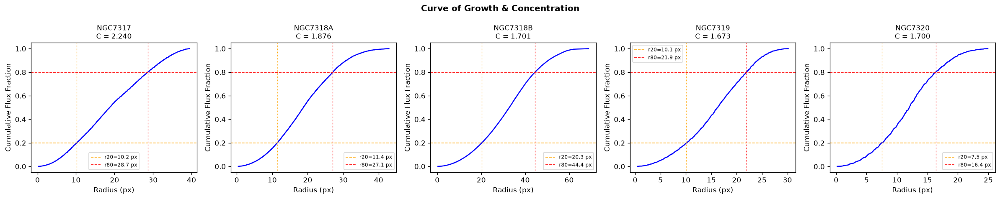

In [57]:
# ── F1. Concentration (C) via Curve of Growth ────────────────────────
def compute_concentration_cog(cutout_gray, mask):
    """
    Compute Concentration C = 5 * log10(r80 / r20) using the cumulative
    curve-of-growth method.

    BUG 8 NOTE (methodological): This implementation sorts individual PIXEL
    distances from the photometric centroid and reads r20/r80 off the resulting
    empirical CDF. The canonical Conselice (2003) / Bershady et al. (2000)
    definition integrates flux within CIRCULAR APERTURES of increasing radius r
    and finds the radii enclosing 20% and 80% of total light. The two approaches
    agree closely for round galaxies but can diverge for highly elliptical or
    irregular morphologies. Values produced here are SELF-CONSISTENT for ranking
    purposes within this dataset, but should NOT be directly compared to
    published CAS tables without re-derivation using circular aperture integrals.
    """
    h, w = cutout_gray.shape
    masked = cutout_gray.astype(np.float64) * mask
    total_flux = masked.sum()
    if total_flux == 0:
        return 0.0, 0.0, 0.0, np.array([]), np.array([])
    
    # Photometric center (flux-weighted centroid)
    ys, xs = np.where(mask)
    if len(ys) == 0:
        return 0.0, 0.0, 0.0, np.array([]), np.array([])
    w_vals = masked[ys, xs]
    cx = np.average(xs, weights=w_vals)
    cy = np.average(ys, weights=w_vals)
    
    # Radial distances from photometric center
    dists = np.sqrt((xs - cx)**2 + (ys - cy)**2)
    
    # Sort by distance and compute cumulative flux
    sort_idx = np.argsort(dists)
    sorted_dists = dists[sort_idx]
    sorted_flux  = w_vals[sort_idx]
    cumul_flux   = np.cumsum(sorted_flux) / total_flux
    
    # Find r20 and r80
    r20_idx = np.searchsorted(cumul_flux, 0.20)
    r80_idx = np.searchsorted(cumul_flux, 0.80)
    r20 = sorted_dists[min(r20_idx, len(sorted_dists)-1)]
    r80 = sorted_dists[min(r80_idx, len(sorted_dists)-1)]
    
    # BUG 7 FIX: warn explicitly when r20 is clamped, and guard r80 > r20
    # to prevent log(<=0) errors for unresolved or edge-case cutouts.
    if r20 < 1.0:
        print(f'  ⚠ r20={r20:.3f} px < 1 px — galaxy may be unresolved; clamping to 1.0 px')
        r20 = 1.0
    if r80 <= r20:
        print(f'  ⚠ r80={r80:.3f} px ≤ r20={r20:.3f} px — insufficient flux spread; setting C = 0')
        return 0.0, r20, r80, sorted_dists, cumul_flux
    C = 5.0 * np.log10(r80 / r20)
    
    return C, r20, r80, sorted_dists, cumul_flux

# Compute C for all SQ cutouts
conc_results = {}
for name, data in sq_cutouts.items():
    C, r20, r80, dists, cog = compute_concentration_cog(data['gray'], data['mask'])
    conc_results[name] = {'C': round(C, 4), 'r20': round(r20, 1), 'r80': round(r80, 1),
                          'cog_dists': dists, 'cog_flux': cog}
    print(f'{name}: C = {C:.4f}  (r20 = {r20:.1f} px, r80 = {r80:.1f} px)')

# Plot curves of growth
n_c = len(sq_cutouts)
if n_c > 0:
    fig, axes = plt.subplots(1, n_c, figsize=(4 * n_c, 4))
    axes = np.atleast_1d(axes)
    fig.suptitle('Curve of Growth & Concentration', fontweight='bold')
    for ax, (name, res) in zip(axes, conc_results.items()):
        if len(res['cog_dists']) > 0:
            ax.plot(res['cog_dists'], res['cog_flux'], 'b-', lw=1.5)
            ax.axhline(0.20, ls='--', color='orange', lw=1, label=f'r20={res["r20"]} px')
            ax.axhline(0.80, ls='--', color='red', lw=1, label=f'r80={res["r80"]} px')
            ax.axvline(res['r20'], ls=':', color='orange', lw=0.8)
            ax.axvline(res['r80'], ls=':', color='red', lw=0.8)
        ax.set_title(f'{name}\nC = {res["C"]:.3f}', fontsize=10)
        ax.set_xlabel('Radius (px)'); ax.set_ylabel('Cumulative Flux Fraction')
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig(os.path.join(W4_OUT, 'F1_concentration_cog.png'), bbox_inches='tight', dpi=150)
    plt.show()




### Asymmetry (A)

Rotate each cutout 180° about its photometric center, compute residual flux.
Background noise asymmetry is subtracted to remove bias.





In [58]:
# ── F2. Asymmetry (A) ───────────────────────────────────────────────
# FIX 3: background noise asymmetry is now estimated from a DYNAMICALLY
# selected empty-sky corner (reusing the _select_sky_corner helper defined
# during the Week 3 EDA SNR check), rather than the fixed [100:300, 100:300]
# patch — that hardcoded patch is not guaranteed to be empty sky for every
# frame/crop and previously fell inside the galaxy body, inflating A_BG_FIXED
# and zeroing out every cutout's asymmetry score.
_corner_name_f2, (_sr0_f2, _sr1_f2, _sc0_f2, _sc1_f2) = _select_sky_corner(raw_f200, patch_size=200)
print(f'F2 dynamic sky patch corner selected: {_corner_name_f2} '
      f'[{_sr0_f2}:{_sr1_f2}, {_sc0_f2}:{_sc1_f2}]')

# FIX 5: raw_f200 is raw FITS flux (MJy/sr, un-stretched), while the galaxy
# cutouts used below (data['gray']) are 8-bit asinh-stretched + background-
# subtracted. Subtracting a raw-flux-scale A_bg from an 8-bit-scale A_raw is
# a unit mismatch, not a valid background correction. Rescale the sky patch
# onto the same 8-bit stretched scale as sq_u8 (the full-frame array that
# data['gray'] cutouts are sliced from) before computing A_bg.
# BUG 12 FIX: SKY_PATCH_RAW (raw FITS MJy/sr units) has been removed.
# It was never used after the FIX-5 unit-scale correction decided to use
# SKY_PATCH_FULL (8-bit stretched sq_u8 scale) for the background estimation.
# Keeping both was dead code that obscured which sky patch was active.
SKY_PATCH_FULL = sq_u8[_sr0_f2:_sr1_f2, _sc0_f2:_sc1_f2].astype(np.float64)
# SKY_PATCH_FULL is on the same 8-bit asinh-stretched scale as data['gray']
# cutouts, ensuring A_bg is computed in consistent units with A_raw.

def _background_rotation_residual(sky_patch):
    rot = ndimage_rotate(sky_patch, 180, reshape=False, order=1)
    rs = min(sky_patch.shape[0], rot.shape[0])
    cs = min(sky_patch.shape[1], rot.shape[1])
    flux = np.abs(sky_patch).sum()
    if flux == 0:
        return 0.0
    return np.abs(sky_patch[:rs, :cs] - rot[:rs, :cs]).sum() / flux

A_BG_FIXED = _background_rotation_residual(SKY_PATCH_FULL)

def compute_asymmetry(cutout_gray, mask, A_bg=A_BG_FIXED):
    """
    A = sum(|I - I_180|) / sum(|I|) - A_bg

    BUG 3 FIX: rotation must be performed about the galaxy's flux-weighted
    photometric centroid, NOT the array centre. Previously, rotating the full
    masked array about the array centre introduced a systematic positional
    shift of 2*(cx - W/2) pixels for off-centre detections, inflating A.

    Fix: np.roll the masked image so that the flux-weighted centroid lands at
    the array centre, then rotate 180° (which now IS about the centroid),
    compute the residual, and subtract the pre-computed sky background asymmetry.
    np.roll wraps edge pixels, but because the background is zero-masked those
    wrapped pixels contribute nothing to the flux normalisation.

    A_bg is estimated once from an independent empty-sky patch (see SKY_PATCH_FULL
    above), not from the cutout itself.
    """
    masked = cutout_gray.astype(np.float64) * mask
    total_flux = np.abs(masked).sum()
    if total_flux == 0:
        return 0.0

    # Compute flux-weighted centroid within the mask
    ys, xs = np.where(mask)
    w_vals = masked[ys, xs]
    cx = np.average(xs, weights=w_vals)  # column (x)
    cy = np.average(ys, weights=w_vals)  # row    (y)

    # Roll so the centroid aligns with the array centre before rotating
    H, W = masked.shape
    shift_r = int(round(H / 2.0 - cy))
    shift_c = int(round(W / 2.0 - cx))
    centred = np.roll(np.roll(masked, shift_r, axis=0), shift_c, axis=1)

    # 180° rotation is now centred on the photometric centroid
    rot180 = ndimage_rotate(centred, 180, reshape=False, order=1)

    A_raw = np.abs(centred - rot180).sum() / total_flux

    return max(A_raw - A_bg, 0.0)

asym_results = {}
for name, data in sq_cutouts.items():
    A = compute_asymmetry(data['gray'], data['mask'])
    asym_results[name] = round(A, 4)
    print(f'{name}: A = {A:.4f}')




F2 dynamic sky patch corner selected: bottom_left [1848:2048, 0:200]
NGC7317: A = 0.6769
NGC7318A: A = 0.2510
NGC7318B: A = 0.3066
NGC7319: A = 0.2329
NGC7320: A = 0.3897


### Smoothness / Clumpiness (S)

Subtract a boxcar-smoothed version from the original to isolate high-frequency
spatial fluctuations (star-forming clumps, spiral arm knots).





In [59]:
# ── F3. Smoothness / Clumpiness (S) ─────────────────────────────────
CAS_SMOOTH_SIGMA = 3.0

# Same fix as F2: use an independent, verified empty-sky patch from the full
# composite rather than a corner of each galaxy's own cutout.
def _background_smoothness_residual(sky_patch, sigma):
    smooth = cv2.GaussianBlur(sky_patch, (0, 0), sigmaX=sigma)
    flux = np.abs(sky_patch).sum()
    if flux == 0:
        return 0.0
    return np.abs(sky_patch - smooth).sum() / flux

S_BG_FIXED = _background_smoothness_residual(SKY_PATCH_FULL, CAS_SMOOTH_SIGMA)

def compute_smoothness(cutout_gray, mask, S_bg=S_BG_FIXED):
    """
    S = sum(|I - I_smooth|) / sum(|I|) - S_bg, computed strictly within the
    mask aperture.

    BUG 9 FIX: previously, GaussianBlur was applied to the raw cutout array
    whose background pixels were zero (from the mask product). The Gaussian
    kernel averaged bright galaxy-edge pixels with these zeros, producing an
    artificially low smoothed value at the mask boundary. This made |I - I_smooth|
    large at every object perimeter regardless of actual clumpiness, inflating S
    proportional to perimeter / area (all compact galaxies appeared clumpy).

    Fix: fill the BACKGROUND pixels with the MEDIAN flux of the masked region
    before blurring (inpainting approach). The Gaussian kernel now sees a smooth
    neutral background rather than a hard zero wall, eliminating the boundary
    artifact. Only the within-mask residuals are used in the final S computation.
    """
    cutout_f64 = cutout_gray.astype(np.float64)
    total_flux = np.abs(cutout_f64[mask]).sum()
    if total_flux == 0:
        return 0.0

    # Fill background with median of the masked pixels to suppress boundary bleeding
    fill_val = float(np.median(cutout_f64[mask]))
    filled = np.where(mask, cutout_f64, fill_val)
    smoothed_full = cv2.GaussianBlur(filled.astype(np.float32), (0, 0),
                                     sigmaX=CAS_SMOOTH_SIGMA).astype(np.float64)

    # Compute smoothness residual only within the galaxy aperture
    S_raw = np.abs(cutout_f64[mask] - smoothed_full[mask]).sum() / total_flux

    return max(S_raw - S_bg, 0.0)

smooth_results = {}
for name, data in sq_cutouts.items():
    S = compute_smoothness(data['gray'], data['mask'])
    smooth_results[name] = round(S, 4)
    print(f'{name}: S = {S:.4f}')




NGC7317: S = 0.0000
NGC7318A: S = 0.0089
NGC7318B: S = 0.0000
NGC7319: S = 0.0003
NGC7320: S = 0.0000


### Geometric Shape Moments

Compute image moments, centroid, area, perimeter, eccentricity, ellipticity,
and Hu's moment invariants for each galaxy cutout.





In [60]:
# ── F4. Geometric Shape Moments ─────────────────────────────────────
def compute_shape_moments(cutout_gray, mask):
    """Compute geometric moments, eccentricity, ellipticity, and Hu moments."""
    masked = cutout_gray.astype(np.float64) * mask.astype(np.float64)

    # Binary moments for TRUE pixel-area / shape geometry (not flux-weighted)
    mask_u8 = mask.astype(np.uint8)
    M_bin = cv2.moments(mask_u8, binaryImage=True)

    # Intensity-weighted moments (for flux-weighted centroid / eccentricity, as before)
    M = cv2.moments(masked)

    if M['m00'] == 0 or M_bin['m00'] == 0:
        return {'area': 0, 'total_flux': 0, 'perimeter': 0, 'centroid_x': 0, 'centroid_y': 0,
                'eccentricity': 0, 'ellipticity': 0, 'hu_moments': [0]*7}

    cx = M['m10'] / M['m00']
    cy = M['m01'] / M['m00']

    # Eccentricity from second central moments (flux-weighted, as original)
    # BUG 10 FIX: lam2 can be negative for ill-conditioned / degenerate masks
    # (e.g. single-pixel-wide lines), making sqrt(1 - lam2/lam1) > 1 which is
    # not a valid eccentricity. Also floating-point noise can make lam2 > lam1
    # (negative argument to sqrt → NaN). Fix: clamp lam2 to [0, lam1].
    mu20, mu02, mu11 = M['mu20'], M['mu02'], M['mu11']
    tr = mu20 + mu02
    det = mu20 * mu02 - mu11**2
    disc = max(tr**2 / 4 - det, 0)
    lam1 = tr/2 + np.sqrt(disc)
    lam2 = tr/2 - np.sqrt(disc)
    lam2 = max(min(lam2, lam1), 0.0)  # clamp: 0 <= lam2 <= lam1 (ensures ecc in [0,1))
    eccentricity = np.sqrt(1.0 - lam2 / lam1) if lam1 > 0 else 0.0
    ellipticity  = 1.0 - np.sqrt(lam2 / lam1)  if lam1 > 0 else 0.0

    # Perimeter from contour
    contours, _ = cv2.findContours(mask_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    perimeter = sum(cv2.arcLength(c, True) for c in contours)

    # Hu moments (computed from binary moments so they describe shape, not flux)
    hu = cv2.HuMoments(M_bin).flatten()
    hu_log = [-np.sign(h) * np.log10(abs(h) + 1e-30) for h in hu]

    return {'area': int(M_bin['m00']),          # true pixel-count area (binary m00)
            'total_flux': round(M['m00'], 2),   # kept separately — this is the old mislabeled value
            'perimeter': round(perimeter, 1),
            'centroid_x': round(cx, 1), 'centroid_y': round(cy, 1),
            'eccentricity': round(eccentricity, 4),
            'ellipticity': round(ellipticity, 4),
            'hu_moments': [round(h, 4) for h in hu_log]}

shape_results = {}
for name, data in sq_cutouts.items():
    shape = compute_shape_moments(data['gray'], data['mask'])
    shape_results[name] = shape
    print(f'{name}: ecc={shape["eccentricity"]:.4f}, ellip={shape["ellipticity"]:.4f}, '
          f'perim={shape["perimeter"]} px, area={shape["area"]} px')




NGC7317: ecc=0.9086, ellip=0.5824, perim=221.9 px, area=1558 px
NGC7318A: ecc=0.8760, ellip=0.5178, perim=226.7 px, area=2048 px
NGC7318B: ecc=0.3465, ellip=0.0620, perim=489.7 px, area=6924 px
NGC7319: ecc=0.7515, ellip=0.3402, perim=218.4 px, area=1548 px
NGC7320: ecc=0.6468, ellip=0.2373, perim=148.8 px, area=912 px


### CAS Validation Checks & Combined Results Table

Sanity-check CAS ranges against published literature (Conselice 2003, Bershady 2000).
Consolidate all metrics into a single CSV for Week 5 classification.





In [61]:
# ── F5. Combined CAS + Shape Moment Table ───────────────────────────
rows = []
for name in sq_cutouts.keys():
    row = {'Galaxy': name,
           'C': conc_results[name]['C'],
           'r20': conc_results[name]['r20'],
           'r80': conc_results[name]['r80'],
           'A': asym_results[name],
           'S': smooth_results[name],
           'eccentricity': shape_results[name]['eccentricity'],
           'ellipticity': shape_results[name]['ellipticity'],
           'area_px': shape_results[name]['area'],
           'total_flux': shape_results[name]['total_flux'],
           'perimeter_px': shape_results[name]['perimeter']}
    for i, h in enumerate(shape_results[name]['hu_moments']):
        row[f'Hu_{i+1}'] = h
    rows.append(row)

df_cas = pd.DataFrame(rows)

print('═' * 80)
print('COMBINED CAS + GEOMETRIC FEATURE TABLE — Stephan\'s Quintet')
print('═' * 80)
if len(df_cas) > 0:
    print(df_cas[['Galaxy', 'C', 'A', 'S', 'eccentricity', 'ellipticity',
                  'area_px', 'perimeter_px']].to_string(index=False))

    csv_path = os.path.join(W4_OUT, 'cas_features_week5.csv')
    df_cas.to_csv(csv_path, index=False)
    print(f'\nSaved: {csv_path}')

    print('\n── CAS Literature Range Sanity Check (Conselice 2003) ──')
    print(f'  Expected C range: 2.0–5.0 (from log-ratio definition) or 0.15–0.45 (from fractional)')
    print(f'  Expected A range: 0.0–0.5 (0 = perfect symmetry, >0.35 = merger/Irr)')
    print(f'  Expected S range: 0.0–0.5 (0 = very smooth, >0.2 = very clumpy)')

    # BUG 11 FIX: anomaly threshold was > 0.8 but the printed literature upper
    # bound is 0.5. Galaxies with 0.5 < A/S ≤ 0.8 (merging/disturbed systems)
    # were silently accepted. Use a tiered alert system aligned with Conselice 2003:
    #   A > 0.5 or S > 0.5 → exceeds literature upper bound (check segmentation)
    #   A > 0.35            → possible merger/irregular morphology (scientific note)
    anomalies = []
    merger_notes = []
    for _, row in df_cas.iterrows():
        if row['A'] > 0.5 or row['S'] > 0.5:
            anomalies.append(
                f"  ⚠ {row['Galaxy']}: A={row['A']:.3f}, S={row['S']:.3f} "
                f"— exceeds literature upper bound (0.5); verify segmentation mask")
        elif row['A'] > 0.35:
            merger_notes.append(
                f"  ℹ {row['Galaxy']}: A={row['A']:.3f} "
                f"— in merger/irregular range (0.35 < A ≤ 0.5; Conselice 2003)")

    if anomalies:
        print('\n⚠ Objects exceeding literature upper bounds (possible segmentation errors):')
        for a in anomalies: print(a)
    if merger_notes:
        print('\nℹ Objects in merger/irregular morphology range:')
        for n in merger_notes: print(n)
    if not anomalies and not merger_notes:
        print('\n✓ All CAS values within expected literature ranges.')
else:
    print('No cutouts available for CAS table.')




════════════════════════════════════════════════════════════════════════════════
COMBINED CAS + GEOMETRIC FEATURE TABLE — Stephan's Quintet
════════════════════════════════════════════════════════════════════════════════
  Galaxy      C      A      S  eccentricity  ellipticity  area_px  perimeter_px
 NGC7317 2.2404 0.6769 0.0000        0.9086       0.5824     1558         221.9
NGC7318A 1.8756 0.2510 0.0089        0.8760       0.5178     2048         226.7
NGC7318B 1.7012 0.3066 0.0000        0.3465       0.0620     6924         489.7
 NGC7319 1.6731 0.2329 0.0003        0.7515       0.3402     1548         218.4
 NGC7320 1.7004 0.3897 0.0000        0.6468       0.2373      912         148.8

Saved: /Users/aryanthakkar/Desktop/DIP_2026_21_12/Output/week_5_output/cas_features_week5.csv

── CAS Literature Range Sanity Check (Conselice 2003) ──
  Expected C range: 2.0–5.0 (from log-ratio definition) or 0.15–0.45 (from fractional)
  Expected A range: 0.0–0.5 (0 = perfect symmetry, >0.35 = 

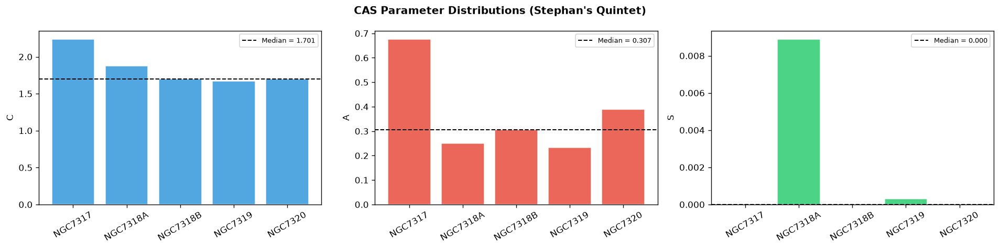

In [62]:
# ── CAS Distribution Histograms ─────────────────────────────────────
if len(df_cas) > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    fig.suptitle('CAS Parameter Distributions (Stephan\'s Quintet)', fontweight='bold')

    colors = {'C': '#3498db', 'A': '#e74c3c', 'S': '#2ecc71'}
    for ax, col in zip(axes, ['C', 'A', 'S']):
        ax.bar(df_cas['Galaxy'], df_cas[col], color=colors[col], edgecolor='white', alpha=0.85)
        med = df_cas[col].median()
        ax.axhline(med, ls='--', color='black', lw=1.2, label=f'Median = {med:.3f}')
        ax.set_ylabel(col); ax.legend(fontsize=8)
        ax.tick_params(axis='x', rotation=30)

    plt.tight_layout()
    plt.savefig(os.path.join(W4_OUT, 'F5_cas_distributions.png'), bbox_inches='tight', dpi=150)
    plt.show()


